# Baseline Plots

Loads all `.npz` / `.csv` files produced by `baseline_compute.py` and renders every plot inline.

Run `baseline_compute.py` first, then use this notebook to explore results.

In [1]:
import os, pickle
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve,
                              precision_recall_curve, average_precision_score)
from sklearn.model_selection import train_test_split

import utils
from utils import (
    GRUModel, LSTMModel, AttentionGRUModel, AttentionLSTMModel,
    CNNModel, set_seed, pick_best,
)

set_seed(42)

SIM_DIR       = "/home/hoepler/eICU_Real_World_Example/sim_outputs_advanced/"
OUTPUT_DIR    = "/home/hoepler/eICU_Real_World_Example/simulation_results_advanced/"
SCENARIO_NAME = "baseline"
TAG           = "N3000_V20_trig0.15_esc0.10_bg0.010_corr0.00_ac0.00"
STORE_PATH    = os.path.join(OUTPUT_DIR, 'scenario_store_baseline.pkl')
out           = os.path.join(OUTPUT_DIR, SCENARIO_NAME)
device        = torch.device('cpu')

print(f"Output dir: {out}")

Random seed set to: 42
Output dir: /home/hoepler/eICU_Real_World_Example/simulation_results_advanced/baseline


## Reload store & models

In [2]:
with open(STORE_PATH, 'rb') as f:
    _store = pickle.load(f)

feature_names  = _store['feature_names']
n_visits       = _store['n_visits']
n_static       = _store.get('n_static', 2)
X_seq_test     = _store['X_explain']
X_static_test  = _store.get('X_static_test', None)
X_seq_train    = _store['X_train']
X_static_train = _store.get('X_static_train', None)
y_test         = _store['y_test']
y_train        = _store['y_train']
pid_test       = _store['pid_test']
hist_gru       = _store['hist_gru']
hist_lstm      = _store['hist_lstm']
hist_attn_gru  = _store['hist_attn_gru']
hist_attn_lstm = _store['hist_attn_lstm']
hist_cnn       = _store.get('hist_cnn', None)
perf           = _store['perf']

n_patients = int(TAG.split('_')[0][1:])
n_tokens   = _store.get('n_tokens', len(feature_names) - n_static)
input_size = n_tokens
T          = n_visits
F          = len(feature_names)
fnames_seq = feature_names[:n_tokens]

# Rebuild models
model_gru       = GRUModel(          input_size=input_size, hidden_size=32, output_size=1, static_size=n_static)
model_lstm      = LSTMModel(         input_size=input_size, hidden_size=32, output_size=1, static_size=n_static)
model_attn_gru  = AttentionGRUModel( input_size=input_size, hidden_size=32, output_size=1, static_size=n_static)
model_attn_lstm = AttentionLSTMModel(input_size=input_size, hidden_size=32, output_size=1, static_size=n_static)
model_cnn       = CNNModel(          input_size=input_size, output_size=1,  static_size=n_static, num_filters=64)

for m, fname in [
    (model_gru,       'best_model_gru.pth'),
    (model_lstm,      'best_model_lstm.pth'),
    (model_attn_gru,  'best_model_attn_gru.pth'),
    (model_attn_lstm, 'best_model_attn_lstm.pth'),
    (model_cnn,       'best_model_cnn.pth'),
]:
    m.load_state_dict(torch.load(os.path.join(out, fname), map_location=device))
    m.to(device).eval()

X_test_tensor = torch.tensor(X_seq_test, dtype=torch.float32).to(device)
X_static_t    = torch.tensor(X_static_test, dtype=torch.float32).to(device) \
                if X_static_test is not None else None

# Aggregate temporal features by summing across time
if X_static_train is not None:
    X_train_flat = np.concatenate([X_seq_train.sum(axis=1), X_static_train], axis=1)
    X_test_flat  = np.concatenate([X_seq_test.sum(axis=1), X_static_test], axis=1)
else:
    X_train_flat = X_seq_train.sum(axis=1)
    X_test_flat  = X_seq_test.sum(axis=1)

lr_model = LogisticRegression(penalty='l2', C=1.0, max_iter=1000)
rf_model = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=3105)
lr_model.fit(X_train_flat, y_train)
rf_model.fit(X_train_flat, y_train)

print(f"Loaded: {n_tokens} token features + {n_static} static = {F} total, {n_visits} visits")

Loaded: 140 token features + 2 static = 142 total, 20 visits


## Load XAI arrays from disk

In [3]:
# KernelSHAP
ks_data = np.load(os.path.join(out, 'kernelshap_results.npz'), allow_pickle=True)
shap_ntf_dict = {
    'gru':       ks_data['shap_ntf_gru'],
    'lstm':      ks_data['shap_ntf_lstm'],
    'attn_gru':  ks_data['shap_ntf_attn_gru'],
    'attn_lstm': ks_data['shap_ntf_attn_lstm'],
    'cnn':       ks_data['shap_ntf_cnn'],
}
case_indices = ks_data['case_indices'].tolist()
case_titles  = ks_data['case_titles'].tolist()
print(f"KernelSHAP loaded: {shap_ntf_dict['gru'].shape}")

KernelSHAP loaded: (8, 20, 140)


In [4]:
# KernelSHAP
ks_data = np.load(os.path.join(out, 'kernelshap_results.npz'), allow_pickle=True)
shap_ntf_dict = {
    'gru':       ks_data['shap_ntf_gru'],
    'lstm':      ks_data['shap_ntf_lstm'],
    'attn_gru':  ks_data['shap_ntf_attn_gru'],
    'attn_lstm': ks_data['shap_ntf_attn_lstm'],
    'cnn':       ks_data['shap_ntf_cnn'],
}
case_indices = ks_data['case_indices'].tolist()
case_titles  = ks_data['case_titles'].tolist()
print(f"KernelSHAP loaded: {shap_ntf_dict['gru'].shape}")

# TimeSHAP
timeshap_ntf_dict = {}
for model_name in ['gru', 'lstm', 'attn_gru', 'attn_lstm', 'cnn']:
    ts_data = np.load(os.path.join(out, f'timeshap_cell_ntf_{model_name}.npz'))
    timeshap_ntf_dict[model_name] = ts_data[f'ts_{model_name}_ntf']
    print(f"TimeSHAP {model_name}: {timeshap_ntf_dict[model_name].shape}")

# WindowSHAP
windowshap_ntf_dict = {}
for model_name in ['gru', 'lstm', 'attn_gru', 'attn_lstm', 'cnn']:
    ws_path = os.path.join(out, f'windowshap_{model_name}.npz')
    if os.path.exists(ws_path):
        d = np.load(ws_path)
        windowshap_ntf_dict[model_name] = {'stat': d['stat_ntf'], 'slid': d['slid_ntf'], 'dyn': d['dyn_ntf']}
        print(f"WindowSHAP {model_name}: stat={d['stat_ntf'].shape}")
tp_sample  = d['tp_ws']
tp_pos_map = dict(zip(d['tp_pos_map_keys'].tolist(), d['tp_pos_map_values'].tolist()))

# IG
ig_data          = np.load(os.path.join(out, 'ig_arrays.npz'))
ig_gru_ntf       = ig_data['ig_gru_ntf']
ig_lstm_ntf      = ig_data['ig_lstm_ntf']
ig_attn_gru_ntf  = ig_data['ig_attn_gru_ntf']
ig_attn_lstm_ntf = ig_data['ig_attn_lstm_ntf']
ig_cnn_ntf       = ig_data['ig_cnn_ntf']
print(f"IG loaded: {ig_gru_ntf.shape}")

# EG
eg_data          = np.load(os.path.join(out, 'eg_arrays.npz'))
eg_gru_ntf       = eg_data['eg_gru_ntf']
eg_lstm_ntf      = eg_data['eg_lstm_ntf']
eg_attn_gru_ntf  = eg_data['eg_attn_gru_ntf']
eg_attn_lstm_ntf = eg_data['eg_attn_lstm_ntf']
eg_cnn_ntf       = eg_data['eg_cnn_ntf']
base_val_gru, base_val_lstm, base_val_attn_gru, base_val_attn_lstm, base_val_cnn = eg_data['base_vals']
print(f"EG loaded: {eg_gru_ntf.shape}")

cs_case_indices = list(case_indices)


KernelSHAP loaded: (8, 20, 140)
TimeSHAP gru: (600, 20, 140)
TimeSHAP lstm: (600, 20, 140)
TimeSHAP attn_gru: (600, 20, 140)
TimeSHAP attn_lstm: (600, 20, 140)
TimeSHAP cnn: (600, 20, 140)
WindowSHAP gru: stat=(8, 20, 140)
WindowSHAP lstm: stat=(8, 20, 140)
WindowSHAP attn_gru: stat=(8, 20, 140)
WindowSHAP attn_lstm: stat=(8, 20, 140)
WindowSHAP cnn: stat=(8, 20, 140)
IG loaded: (600, 20, 140)
EG loaded: (600, 20, 140)


## Load case studies & shared variables

In [5]:
# ── Load case_studies from store (fixed selection, matches baseline_compute.py) ──
# This replaces the previous pick_best() recomputation, which could select
# different patients if GRU probabilities shifted between runs.
_store_cs = pickle.load(open(STORE_PATH, 'rb'))

if 'case_studies' in _store_cs:
    case_studies = _store_cs['case_studies']
    print("case_studies loaded from store — patients are fixed.")
else:
    # Fallback for old stores that predate the fix.
    print("WARNING: store predates case_studies persistence — rebuilding from GRU probs.")
    print("         Re-run baseline_compute.py (Part A) once to make the selection permanent.")
    pid_to_test_index = {pid: i for i, pid in enumerate(pid_test)}
    labels_test = labels[labels['patient_id'].isin(pid_test)].copy()
    labels_test['test_idx'] = labels_test['patient_id'].map(pid_to_test_index)
    with torch.no_grad():
        y_probs_ref = model_gru(X_test_tensor, X_static_t).cpu().numpy().flatten()
    case_studies = {}
    for group, title in [
        ('trigger_only',       'Pure Trigger'),
        ('chronic_only',       'Pure Chronic'),
        ('escalation_only',    'Pure Late Escalation'),
        ('trigger+chronic',    'Mixed: Trigger + Chronic'),
        ('trigger+escalation', 'Mixed: Trigger + Escalation'),
        ('escalation+chronic', 'Mixed: Chronic + Escalation'),
        ('all_three',          'Mixed: All Three'),
    ]:
        cand = labels_test.loc[labels_test['group_gt'] == group, 'test_idx'].dropna().astype(int).values
        cand = cand[y_test[cand] == 1]
        p = pick_best(cand, y_probs_ref)
        if p is not None: case_studies[title] = p
    fp = np.where((y_test == 0) & (y_probs_ref > 0.6))[0]
    p  = pick_best(fp, y_probs_ref)
    if p is not None: case_studies['False Positive'] = p

df_events = pd.read_csv(os.path.join(SIM_DIR, f"ehr_events_{TAG}.csv"))
df_static = pd.read_csv(os.path.join(SIM_DIR, f"static_data_{TAG}.csv"))
labels    = pd.read_csv(os.path.join(SIM_DIR, f"phenotype_labels_gt_{TAG}.csv"))
tokens    = sorted(df_events['token'].unique())

idx_icd10        = feature_names.index('ICD_10')
idx_atc5         = feature_names.index('ATC_5')
chronic_feat_ids = [feature_names.index(n) for n in ['ICD_1', 'ICD_2', 'ICD_3']]
gt_indices       = [idx_icd10, idx_atc5] + chronic_feat_ids

MODEL_KEYS   = ['gru', 'lstm', 'attn_gru', 'attn_lstm', 'cnn']
MODEL_LABELS = ['GRU', 'LSTM', 'AttnGRU', 'AttnLSTM', 'CNN']
model_labels = {'gru': 'GRU', 'lstm': 'LSTM', 'attn_gru': 'AttnGRU', 'attn_lstm': 'AttnLSTM', 'cnn': 'CNN'}

visit_labels = [f'V{t+1}' for t in range(T)]
gt_feats     = {'ICD_10', 'ATC_5', 'ICD_1', 'ICD_2', 'ICD_3'}
TOP_K        = 15
GT_FEATURES  = gt_feats
GT_COLOR     = '#e6194b'
DEFAULT_COLOR = 'steelblue'

colors = {
    'GRU': '#E69F00', 'LSTM': '#56B4E9', 'AttnGRU': '#009E73',
    'AttnLSTM': '#CC79A7', 'CNN': '#7B2D8B', 'LR': '#D55E00', 'RF': '#0072B2',
}

EG_ARRS = [eg_gru_ntf, eg_lstm_ntf, eg_attn_gru_ntf, eg_attn_lstm_ntf, eg_cnn_ntf]
IG_ARRS = [ig_gru_ntf, ig_lstm_ntf, ig_attn_gru_ntf, ig_attn_lstm_ntf, ig_cnn_ntf]
MODEL_IG      = list(zip(MODEL_LABELS, IG_ARRS))
MODEL_EG_LIST = list(zip(MODEL_LABELS, EG_ARRS))
MODEL_OBJ     = {'GRU': model_gru, 'LSTM': model_lstm, 'AttnGRU': model_attn_gru,
                 'AttnLSTM': model_attn_lstm, 'CNN': model_cnn}

# New — load from store, already aligned to feature_names
gt_ntf_full = _store_cs['gt_ntf']  # (N_patients, T, n_tokens)

# Subset to test patients for per-patient evaluation
# pid_test is 1-indexed, so subtract 1 for array indexing
truth_ntf = gt_ntf_full[(pid_test - 1).astype(int)]  # (N_test, T, n_tokens)

print(f"Case studies: {list(case_studies.keys())}")
print(f"Patient test indices: { {t: int(i) for t, i in case_studies.items()} }")


case_studies loaded from store — patients are fixed.
Case studies: ['Pure Trigger', 'Pure Chronic', 'Pure Late Escalation', 'Mixed: Trigger + Chronic', 'Mixed: Trigger + Escalation', 'Mixed: Chronic + Escalation', 'Mixed: All Three', 'False Positive']
Patient test indices: {'Pure Trigger': 78, 'Pure Chronic': 399, 'Pure Late Escalation': 586, 'Mixed: Trigger + Chronic': 590, 'Mixed: Trigger + Escalation': 55, 'Mixed: Chronic + Escalation': 528, 'Mixed: All Three': 593, 'False Positive': 561}


---
## Training curves

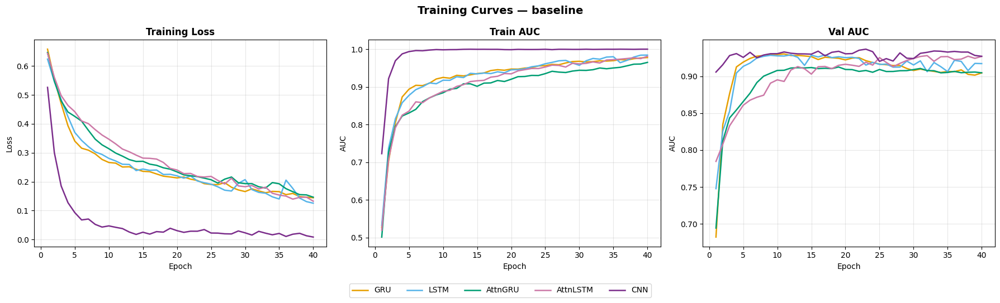

In [6]:
ALL_MODELS = [
    ('GRU', hist_gru), ('LSTM', hist_lstm),
    ('AttnGRU', hist_attn_gru), ('AttnLSTM', hist_attn_lstm), ('CNN', hist_cnn),
]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(f'Training Curves — {SCENARIO_NAME}', fontsize=14, fontweight='bold')
for ax, title, key in zip(axes,
        ['Training Loss', 'Train AUC', 'Val AUC'],
        ['train_loss',   'train_auc', 'val_auc']):
    for label, hist in ALL_MODELS:
        if hist is None: continue
        ax.plot(range(1, len(hist[key]) + 1), hist[key],
                label=label, color=colors[label], linewidth=1.8)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel('Loss'); axes[1].set_ylabel('AUC'); axes[2].set_ylabel('AUC')
handles, labels_leg = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_leg, loc='lower center', ncol=5,
           bbox_to_anchor=(0.5, -0.08), fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(out, 'training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## ROC / Precision-Recall curves

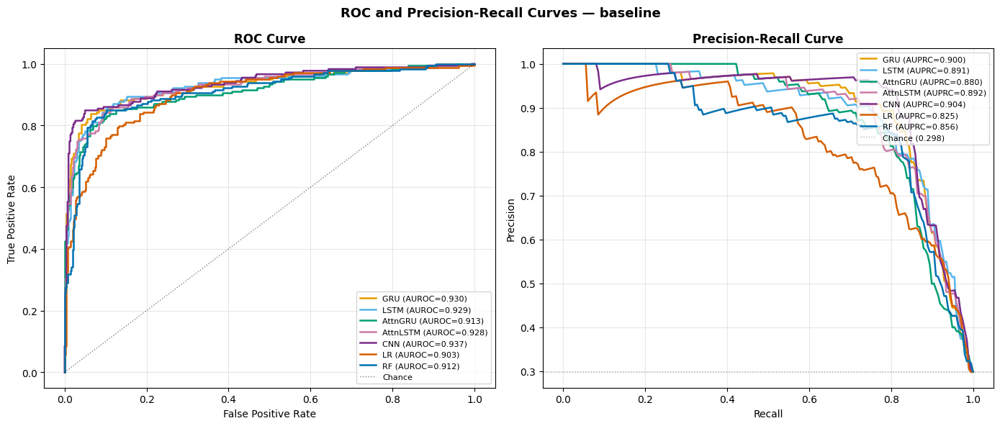

,Model,AUROC,AUPRC
0,GRU,0.930241,0.900145
1,LSTM,0.928967,0.891186
2,AttnGRU,0.912525,0.880279
3,AttnLSTM,0.927971,0.891867
4,CNN,0.936710,0.903940
5,LR,0.903250,0.825353
6,RF,0.912061,0.856005


In [7]:
probs = {}
with torch.no_grad():
    for name, m in [('GRU', model_gru), ('LSTM', model_lstm),
                    ('AttnGRU', model_attn_gru), ('AttnLSTM', model_attn_lstm),
                    ('CNN', model_cnn)]:
        probs[name] = m(X_test_tensor, X_static_t).cpu().numpy().flatten()
probs['LR'] = lr_model.predict_proba(X_test_flat)[:, 1]
probs['RF'] = rf_model.predict_proba(X_test_flat)[:, 1]

prevalence  = y_test.mean()
recall_grid = np.linspace(0, 1, 200)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(f'ROC and Precision-Recall Curves — {SCENARIO_NAME}', fontsize=13, fontweight='bold')
ax = axes[0]
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    auroc = roc_auc_score(y_test, p)
    ax.plot(fpr, tpr, color=colors[name], linewidth=1.8, label=f'{name} (AUROC={auroc:.3f})')
ax.plot([0,1],[0,1], 'k:', linewidth=1, alpha=0.5, label='Chance')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve', fontweight='bold')
ax.legend(fontsize=8, loc='lower right'); ax.grid(alpha=0.3)
ax = axes[1]
for name, p in probs.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    prec_s = np.interp(recall_grid, rec[::-1], prec[::-1])
    ap = average_precision_score(y_test, p)
    ax.plot(recall_grid, prec_s, color=colors[name], linewidth=1.8, label=f'{name} (AUPRC={ap:.3f})')
ax.axhline(prevalence, color='gray', linestyle=':', linewidth=1, alpha=0.6,
           label=f'Chance ({prevalence:.3f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve', fontweight='bold')
ax.legend(fontsize=8, loc='upper right'); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(out, 'roc_pr_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

auc_rows = [(n, roc_auc_score(y_test, p), average_precision_score(y_test, p))
            for n, p in probs.items()]
pd.DataFrame(auc_rows, columns=['Model', 'AUROC', 'AUPRC'])

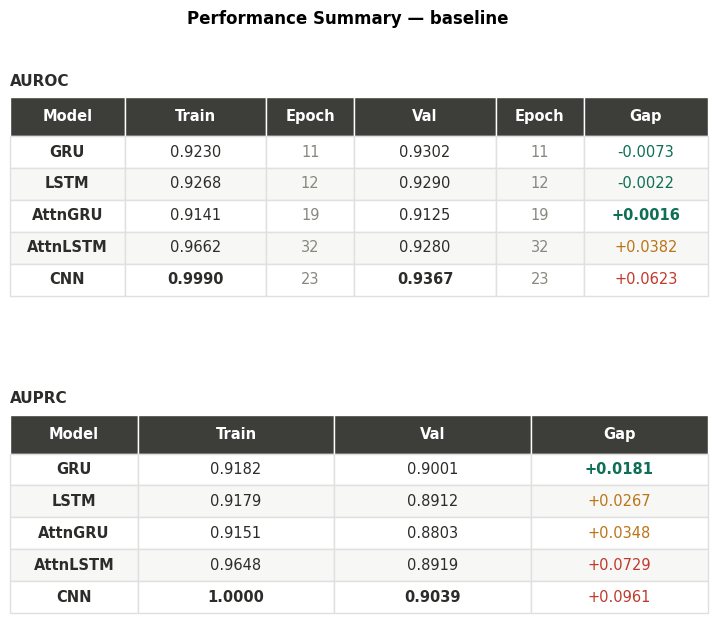

In [8]:
# ── AUC + AUPRC summary table (CORRECTED) ─────────────────────────────────
from sklearn.metrics import average_precision_score

with torch.no_grad():
    probs_dict = {
        'GRU':      model_gru(      X_test_tensor, X_static_t).cpu().numpy().flatten(),
        'LSTM':     model_lstm(     X_test_tensor, X_static_t).cpu().numpy().flatten(),
        'AttnGRU':  model_attn_gru( X_test_tensor, X_static_t).cpu().numpy().flatten(),
        'AttnLSTM': model_attn_lstm(X_test_tensor, X_static_t).cpu().numpy().flatten(),
        'CNN':      model_cnn(      X_test_tensor, X_static_t).cpu().numpy().flatten(),
    }

with torch.no_grad():
    X_train_t  = torch.tensor(X_seq_train,    dtype=torch.float32)
    X_strain_t = torch.tensor(X_static_train, dtype=torch.float32) \
                 if X_static_train is not None else None
    probs_train_dict = {
        'GRU':      model_gru(      X_train_t, X_strain_t).cpu().numpy().flatten(),
        'LSTM':     model_lstm(     X_train_t, X_strain_t).cpu().numpy().flatten(),
        'AttnGRU':  model_attn_gru( X_train_t, X_strain_t).cpu().numpy().flatten(),
        'AttnLSTM': model_attn_lstm(X_train_t, X_strain_t).cpu().numpy().flatten(),
        'CNN':      model_cnn(      X_train_t, X_strain_t).cpu().numpy().flatten(),
    }

# ── build row data (CORRECTED: same epoch) ─────────────────────────────────
auroc_rows = []
auprc_rows = []

for label, hist in ALL_MODELS:
    if hist is None:
        continue
    
    # Find best val epoch
    best_val_idx = int(np.argmax(hist['val_auc']))
    best_val_epoch = best_val_idx + 1
    
    # Get metrics from SAME epoch (best val epoch)
    train_auc_at_best_val = hist['train_auc'][best_val_idx]
    val_auc_at_best_val = hist['val_auc'][best_val_idx]
    auroc_gap = train_auc_at_best_val - val_auc_at_best_val

    auprc_train = average_precision_score(y_train, probs_train_dict[label])
    auprc_val = average_precision_score(y_test, probs_dict[label])
    auprc_gap = auprc_train - auprc_val

    auroc_rows.append([label,
                       f'{train_auc_at_best_val:.4f}', str(best_val_epoch),
                       f'{val_auc_at_best_val:.4f}', str(best_val_epoch),
                       f'{auroc_gap:+.4f}'])
    auprc_rows.append([label,
                       f'{auprc_train:.4f}', '—',
                       f'{auprc_val:.4f}', '—',
                       f'{auprc_gap:+.4f}'])

col_labels = ['Model', 'Train', 'Epoch', 'Val', 'Epoch', 'Gap']
n_rows = len(auroc_rows)
n_cols = len(col_labels)

def _best_vals(rows):
    return {
        1: max([float(r[1]) for r in rows]),
        3: max([float(r[3]) for r in rows]),
        5: min([abs(float(r[5])) for r in rows]),
    }

auroc_best = _best_vals(auroc_rows)
auprc_best = _best_vals(auprc_rows)

def _draw_table(ax, rows, best, title, col_labels, col_widths):
    ax.axis('off')
    ax.set_title(title, fontweight='bold', fontsize=11,
                 loc='left', pad=8, color='#2c2c2a')

    n_cols = len(col_labels)

    tbl = ax.table(
        cellText=rows,
        colLabels=col_labels,
        loc='center',
        cellLoc='center',
        bbox=[0.0, 0.0, 1.0, 1.0],
    )
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(10.5)

    for j in range(n_cols):
        cell = tbl[0, j]
        cell.set_facecolor('#3d3d3a')
        cell.set_text_props(color='white', fontweight='bold')
        cell.set_edgecolor('white')
        cell.set_height(0.22)

    for i, row in enumerate(rows, start=1):
        row_bg = '#f7f7f5' if i % 2 == 0 else '#ffffff'
        for j in range(n_cols):
            cell = tbl[i, j]
            cell.set_facecolor(row_bg)
            cell.set_edgecolor('#e0e0e0')
            cell.set_height(0.18)

            if j == 0:
                cell.set_text_props(fontweight='bold', color='#2c2c2a')
                continue

            # epoch columns
            if col_labels[j] == 'Epoch':
                cell.set_text_props(color='#888780')
                continue

            try:
                val = float(row[j])
            except ValueError:
                cell.set_text_props(color='#888780')
                continue

            is_best = (j in best and abs(val) == best[j])
            fw = 'bold' if is_best else 'normal'

            if col_labels[j] == 'Gap':
                fg = '#c0392b' if abs(val) > 0.05 else \
                     '#ba7517' if abs(val) > 0.02 else '#0f6e56'
                cell.set_text_props(color=fg, fontweight=fw)
            else:
                cell.set_text_props(color='#2c2c2a', fontweight=fw)

    for j, w in enumerate(col_widths):
        for i in range(n_rows + 1):
            tbl[i, j].set_width(w)

# AUROC: with epoch columns
auroc_col_labels  = ['Model', 'Train', 'Epoch', 'Val', 'Epoch', 'Gap']
auroc_col_widths  = [0.13, 0.16, 0.10, 0.16, 0.10, 0.14]
auroc_best_idx    = {1: max, 3: max, 5: min}

# AUPRC: without epoch columns
auprc_col_labels  = ['Model', 'Train', 'Val', 'Gap']
auprc_col_widths  = [0.13, 0.20, 0.20, 0.18]

# strip epoch columns from auprc_rows
auprc_rows_short  = [[r[0], r[1], r[3], r[5]] for r in auprc_rows]
auprc_best_idx    = {1: max, 2: max, 3: min}

def _get_best(rows, best_idx):
    result = {}
    for col_idx, fn in best_idx.items():
        vals = []
        for r in rows:
            try: 
                vals.append(abs(float(r[col_idx])) if col_idx in [5, 3] else float(r[col_idx]))
            except ValueError: 
                pass
        if vals:
            result[col_idx] = fn(vals)
    return result

auroc_best = _get_best(auroc_rows,       auroc_best_idx)
auprc_best = _get_best(auprc_rows_short, auprc_best_idx)

fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(9, 1.2 + 0.55 * n_rows * 2))
fig.suptitle(f'Performance Summary — {SCENARIO_NAME}',
             fontsize=12, fontweight='bold', y=1.01)
fig.subplots_adjust(hspace=0.6)

_draw_table(ax_top, auroc_rows,       auroc_best,
            'AUROC', auroc_col_labels, auroc_col_widths)
_draw_table(ax_bot, auprc_rows_short, auprc_best,
            'AUPRC', auprc_col_labels, auprc_col_widths)

plt.savefig(os.path.join(out, 'auc_summary_table.png'),
            dpi=150, bbox_inches='tight')
plt.show()

---
## KernelSHAP heatmaps

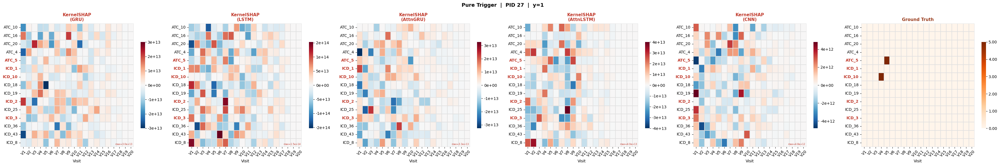

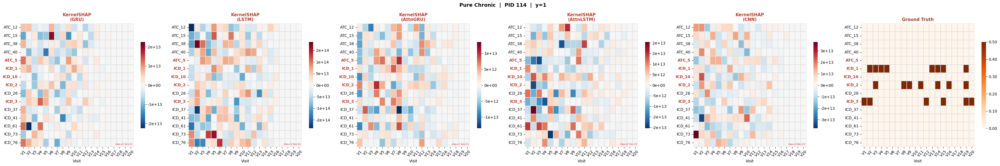

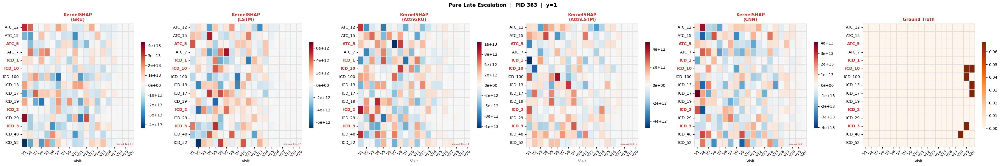

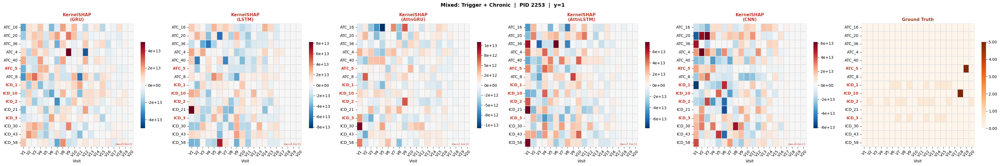

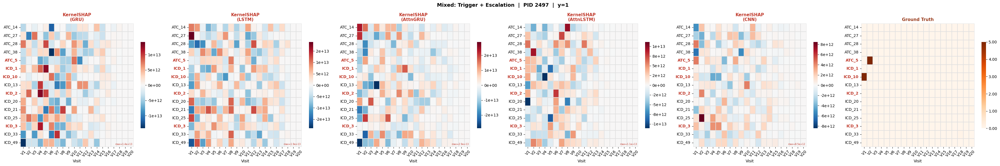

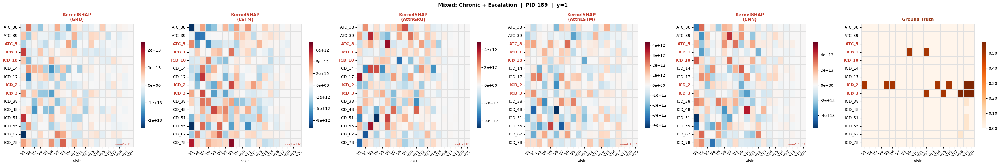

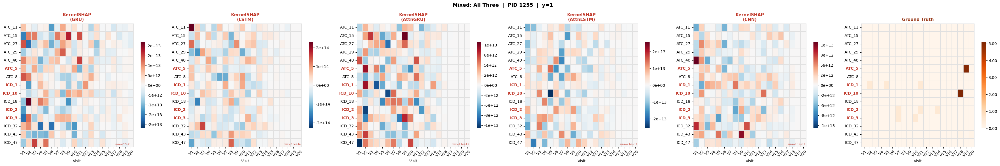

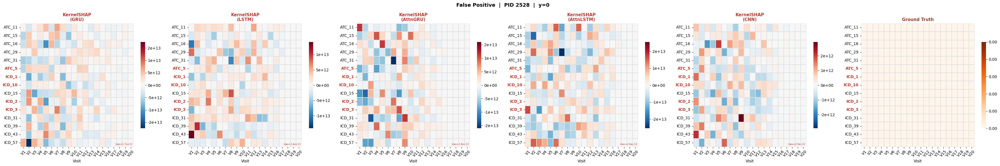

In [9]:
for ci, (case_title, p_idx) in enumerate(zip(case_titles, case_indices)):
    p_idx   = int(p_idx)
    pid_val = int(pid_test[p_idx])
    gt_ids  = set(gt_indices)
    pat_maps = {}
    for mkey in MODEL_KEYS:
        pat_maps[f'KernelSHAP\n({model_labels[mkey]})'] = shap_ntf_dict[mkey][ci, :, :n_tokens]
    pat_maps['Ground Truth'] = truth_ntf[p_idx]
    combined_imp = sum(np.abs(mat).sum(axis=0) for t, mat in pat_maps.items() if t != 'Ground Truth')
    top_by     = np.argsort(combined_imp)[-12:][::-1]
    show       = sorted(set(gt_ids) | set(top_by))[:TOP_K]
    show_names = [fnames_seq[i] for i in show]
    n_panels   = len(pat_maps)
    fig, axes  = plt.subplots(1, n_panels, figsize=(6 * n_panels, 6))
    fig.suptitle(f'{case_title}  |  PID {pid_val}  |  y={int(y_test[p_idx])}',
                 fontsize=13, fontweight='bold')
    for ax, (panel_title, mat) in zip(axes, pat_maps.items()):
        is_gt  = panel_title == 'Ground Truth'
        m_show = mat[:, show]
        vmax   = np.abs(m_show).max() + 1e-8
        sns.heatmap(m_show.T, ax=ax,
                    cmap='Oranges' if is_gt else 'RdBu_r',
                    center=None if is_gt else 0,
                    vmin=0 if is_gt else -vmax, vmax=vmax,
                    xticklabels=visit_labels, yticklabels=show_names,
                    linewidths=0.3, linecolor='#e0e0e0',
                    cbar_kws={'shrink': 0.7, 'format': '%.0e' if not is_gt else '%.2f'})
        ax.set_title(panel_title, fontsize=11, fontweight='bold',
                     color='#993C1D' if is_gt else '#c0392b')
        ax.set_xlabel('Visit')
        ax.tick_params(axis='x', rotation=45)
        if not is_gt:
            ax.set_facecolor('#fff5f5')
            ax.text(0.99, 0.01, f'max={vmax:.1e}', ha='right', va='bottom',
                    fontsize=6, color='#c0392b', transform=ax.transAxes)
        for fi, f_idx in enumerate(show):
            if fnames_seq[f_idx] in gt_feats:
                ax.get_yticklabels()[fi].set_color('#c0392b')
                ax.get_yticklabels()[fi].set_fontweight('bold')
    plt.tight_layout()
    safe = case_title.replace(' ', '_').replace(':', '').replace('+', '_')
    plt.savefig(os.path.join(out, f'kernelshap_all_models_{safe}.png'), dpi=150, bbox_inches='tight')
    plt.show()

---
## TimeSHAP heatmaps

In [10]:
def get_pruning_cutoff(arr):
    """Return index of first non-pruned visit (0-based).
    Pruned visits are a contiguous block of all-zero rows at the start.
    Returns 0 if no visits were pruned, T if all were pruned.
    """
    for t in range(arr.shape[0]):
        if arr[t].sum() != 0:
            return t
    return arr.shape[0]

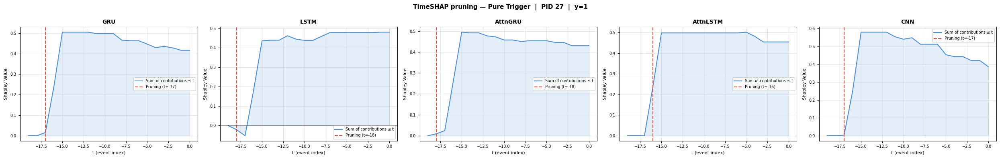

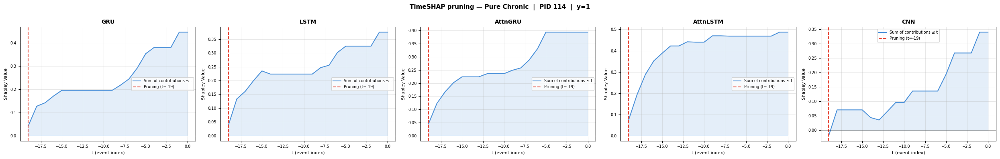

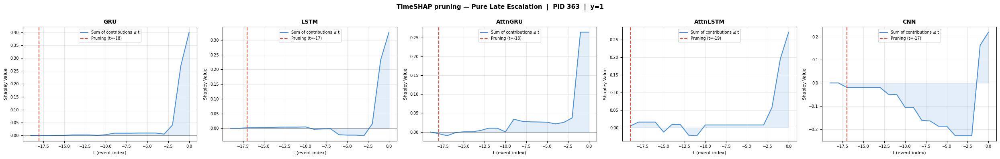

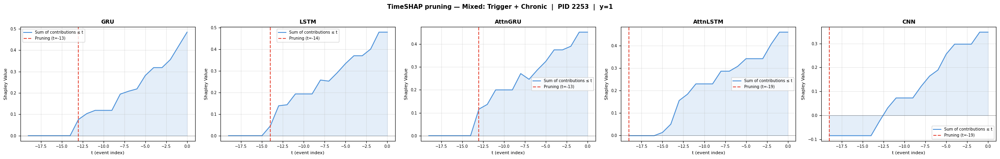

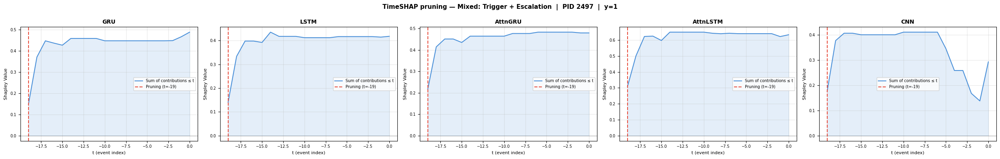

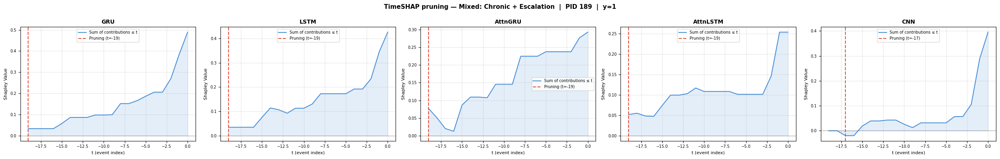

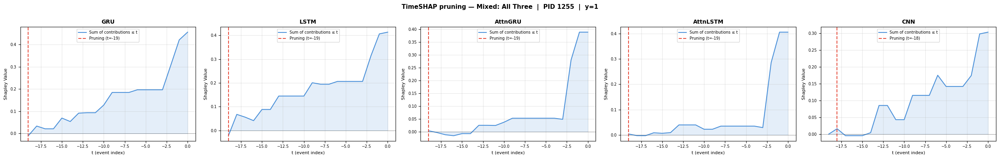

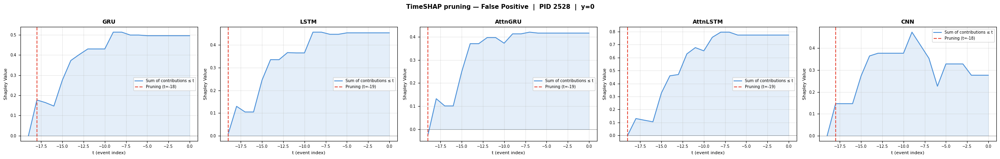

In [11]:
for case_title, p_idx in case_studies.items():
    p_idx   = int(p_idx)
    pid_val = int(pid_test[p_idx])

    fig, axes = plt.subplots(1, len(timeshap_ntf_dict),
                              figsize=(5 * len(timeshap_ntf_dict), 4),
                              sharey=False)
    if len(timeshap_ntf_dict) == 1: axes = [axes]
    fig.suptitle(f'TimeSHAP pruning — {case_title}  |  PID {pid_val}  |  y={int(y_test[p_idx])}',
                 fontsize=11, fontweight='bold')

    for ax, (mname, ntf) in zip(axes, timeshap_ntf_dict.items()):
        arr       = ntf[p_idx, :, :n_tokens]          # (T, F)
        visit_imp = arr.sum(axis=1)                    # (T,) sum of Shapley values per visit
        # Express as negative event index (TimeSHAP convention: t=0 is last visit)
        t_index   = np.arange(-T + 1, 1)              # [-T+1, ..., -1, 0]
        cumsum    = np.cumsum(visit_imp)               # cumulative sum left-to-right

        # Find pruning cutoff — first visit with non-zero attribution
        cutoff_t  = 0
        for t in range(T):
            if arr[t].sum() != 0:
                cutoff_t = t
                break
        cutoff_event_idx = t_index[cutoff_t]           # in TimeSHAP's negative indexing

        ax.plot(t_index, cumsum, color='#4a90d9', linewidth=1.5,
                label='Sum of contributions ≤ t')
        ax.fill_between(t_index, 0, cumsum, alpha=0.15, color='#4a90d9')
        ax.axvline(cutoff_event_idx, color='#e74c3c', linewidth=1.5,
                   linestyle='--', label=f'Pruning (t={cutoff_event_idx})')
        ax.axhline(0, color='black', linewidth=0.6, alpha=0.4)
        ax.set_title(model_labels[mname], fontsize=10, fontweight='bold')
        ax.set_xlabel('t (event index)', fontsize=8)
        ax.set_ylabel('Shapley Value', fontsize=8)
        ax.tick_params(labelsize=7)
        ax.legend(fontsize=7)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    safe = case_title.replace(' ', '_').replace(':', '').replace('+', '_')
    plt.savefig(os.path.join(out, f'timeshap_pruning_{safe}.png'), dpi=150, bbox_inches='tight')
    plt.show()

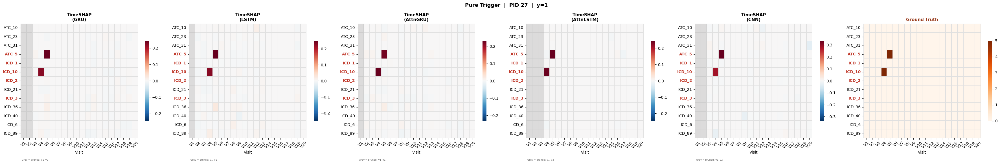

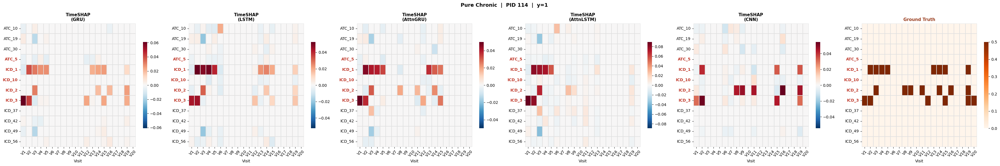

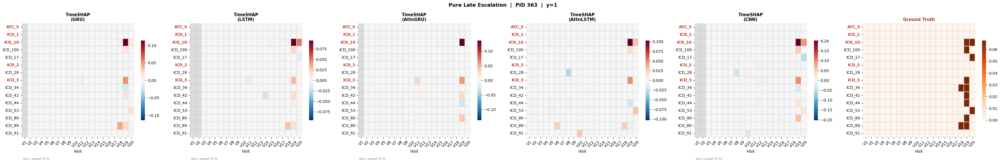

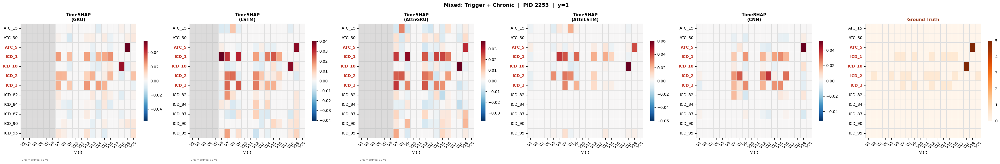

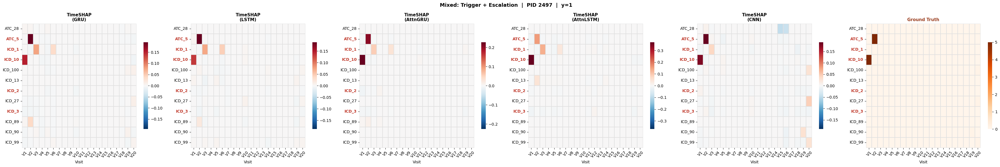

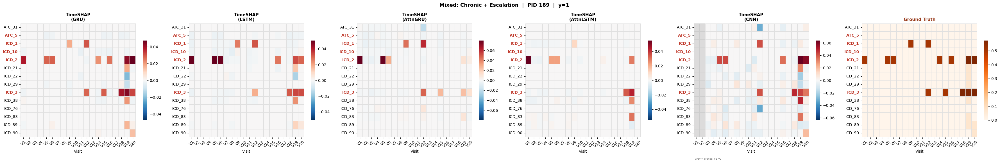

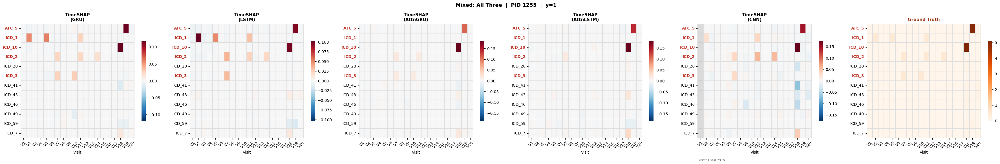

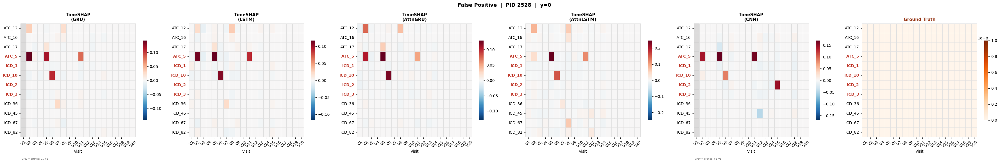

In [12]:
for case_title, p_idx in case_studies.items():
    p_idx   = int(p_idx)
    pid_val = int(pid_test[p_idx])
    pat_maps    = {}
    prune_cutoffs = {}  # panel_title -> first included visit index

    def get_pruning_cutoff(arr):
        for t in range(arr.shape[0]):
            if arr[t].sum() != 0:
                return t
        return arr.shape[0]

    for mname, ntf in timeshap_ntf_dict.items():
        arr = ntf[p_idx, :, :n_tokens]
        if np.any(arr != 0):
            key = f'TimeSHAP\n({model_labels[mname]})'
            pat_maps[key]      = arr
            prune_cutoffs[key] = get_pruning_cutoff(arr)

    pat_maps['Ground Truth'] = truth_ntf[p_idx]
    if len(pat_maps) == 1:
        print(f"  {case_title}: no TimeSHAP data — skipping")
        continue

    combined_imp = sum(np.abs(m).sum(axis=0) for t, m in pat_maps.items() if t != 'Ground Truth')
    top_by     = np.argsort(combined_imp)[-12:][::-1]
    show       = sorted(set(gt_indices) | set(top_by))[:TOP_K]
    show_names = [fnames_seq[i] for i in show]
    n_panels   = len(pat_maps)
    fig, axes  = plt.subplots(1, n_panels, figsize=(6 * n_panels, 6))
    if n_panels == 1: axes = [axes]
    fig.suptitle(f'{case_title}  |  PID {pid_val}  |  y={int(y_test[p_idx])}',
                 fontsize=13, fontweight='bold')

    for ax, (panel_title, mat) in zip(axes, pat_maps.items()):
        is_gt  = panel_title == 'Ground Truth'
        m_show = mat[:, show]
        vmax   = np.abs(m_show).max() + 1e-8
        sns.heatmap(m_show.T, ax=ax,
                    cmap='Oranges' if is_gt else 'RdBu_r',
                    center=None if is_gt else 0,
                    vmin=0 if is_gt else -vmax, vmax=vmax,
                    xticklabels=visit_labels, yticklabels=show_names,
                    linewidths=0.3, linecolor='#e0e0e0', cbar_kws={'shrink': 0.7})
        ax.set_title(panel_title, fontsize=11, fontweight='bold',
                     color='#993C1D' if is_gt else 'black')
        ax.set_xlabel('Visit')
        ax.tick_params(axis='x', rotation=45)
        for fi, f_idx in enumerate(show):
            if fnames_seq[f_idx] in gt_feats:
                ax.get_yticklabels()[fi].set_color('#c0392b')
                ax.get_yticklabels()[fi].set_fontweight('bold')

        # Shade pruned visits — contiguous block from the start
        if panel_title in prune_cutoffs:
            cutoff = prune_cutoffs[panel_title]
            if cutoff > 0:
                ax.add_patch(plt.Rectangle(
                    (0, 0), cutoff, len(show),
                    color='#aaaaaa', alpha=0.35, zorder=5, linewidth=0))
                ax.text(0.01, -0.18,
                        f'Grey = pruned: {visit_labels[0]}–{visit_labels[cutoff - 1]}',
                        transform=ax.transAxes, fontsize=6,
                        color='#666666', va='top')

    plt.tight_layout()
    safe = case_title.replace(' ', '_').replace(':', '').replace('+', '_')
    plt.savefig(os.path.join(out, f'timeshap_all_models_{safe}.png'), dpi=150, bbox_inches='tight')
    plt.show()

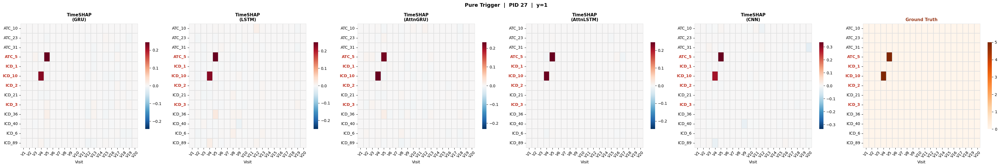

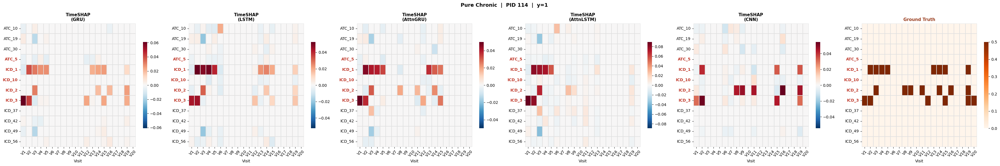

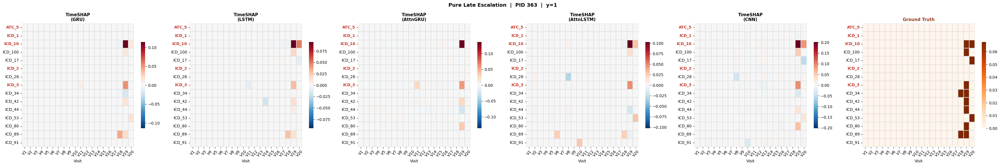

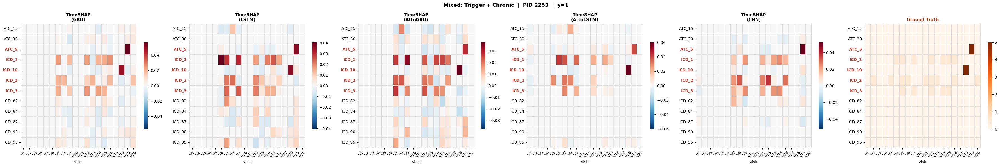

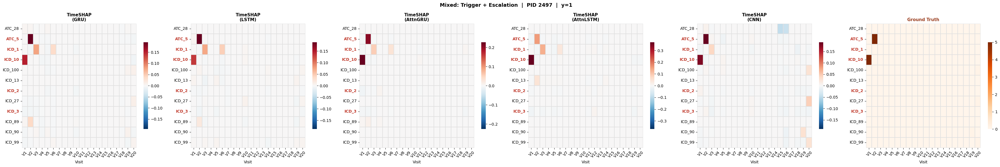

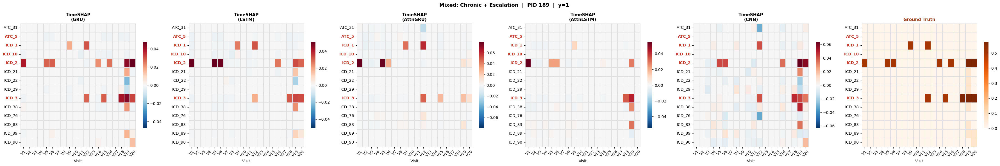

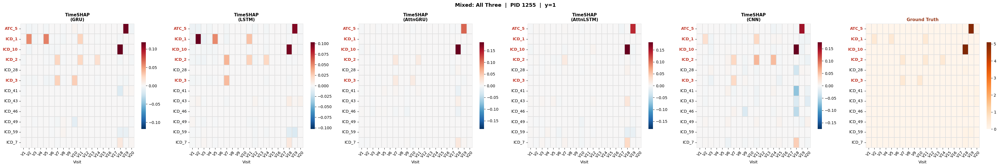

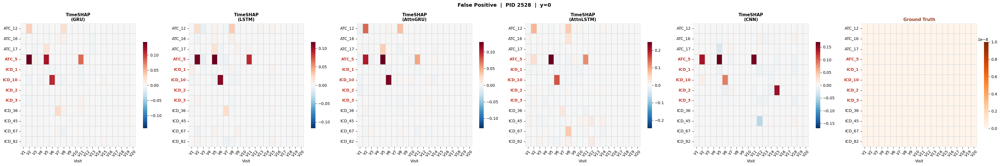

In [13]:
for case_title, p_idx in case_studies.items():
    p_idx   = int(p_idx)
    pid_val = int(pid_test[p_idx])
    pat_maps = {}
    for mname, ntf in timeshap_ntf_dict.items():
        arr = ntf[p_idx, :, :n_tokens]
        if np.any(arr != 0):
            pat_maps[f'TimeSHAP\n({model_labels[mname]})'] = arr
    pat_maps['Ground Truth'] = truth_ntf[p_idx]
    if len(pat_maps) == 1:
        print(f"  {case_title}: no TimeSHAP data — skipping")
        continue
    combined_imp = sum(np.abs(m).sum(axis=0) for t, m in pat_maps.items() if t != 'Ground Truth')
    top_by     = np.argsort(combined_imp)[-12:][::-1]
    show       = sorted(set(gt_indices) | set(top_by))[:TOP_K]
    show_names = [fnames_seq[i] for i in show]
    n_panels   = len(pat_maps)
    fig, axes  = plt.subplots(1, n_panels, figsize=(6 * n_panels, 6))
    if n_panels == 1: axes = [axes]
    fig.suptitle(f'{case_title}  |  PID {pid_val}  |  y={int(y_test[p_idx])}',
                 fontsize=13, fontweight='bold')
    for ax, (panel_title, mat) in zip(axes, pat_maps.items()):
        is_gt  = panel_title == 'Ground Truth'
        m_show = mat[:, show]
        vmax   = np.abs(m_show).max() + 1e-8
        sns.heatmap(m_show.T, ax=ax,
                    cmap='Oranges' if is_gt else 'RdBu_r',
                    center=None if is_gt else 0,
                    vmin=0 if is_gt else -vmax, vmax=vmax,
                    xticklabels=visit_labels, yticklabels=show_names,
                    linewidths=0.3, linecolor='#e0e0e0', cbar_kws={'shrink': 0.7})
        ax.set_title(panel_title, fontsize=11, fontweight='bold',
                     color='#993C1D' if is_gt else 'black')
        ax.set_xlabel('Visit')
        ax.tick_params(axis='x', rotation=45)
        for fi, f_idx in enumerate(show):
            if fnames_seq[f_idx] in gt_feats:
                ax.get_yticklabels()[fi].set_color('#c0392b')
                ax.get_yticklabels()[fi].set_fontweight('bold')
    plt.tight_layout()
    safe = case_title.replace(' ', '_').replace(':', '').replace('+', '_')
    plt.savefig(os.path.join(out, f'timeshap_all_models_{safe}.png'), dpi=150, bbox_inches='tight')
    plt.show()

---
## KernelSHAP + TimeSHAP + Ground Truth  (rows = models)

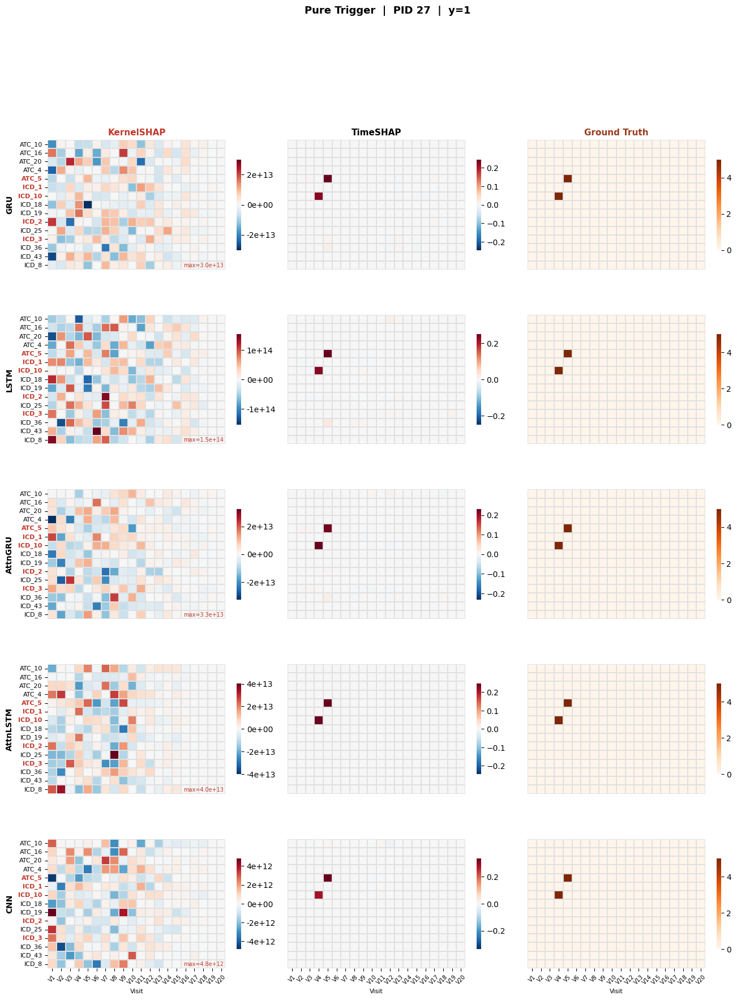

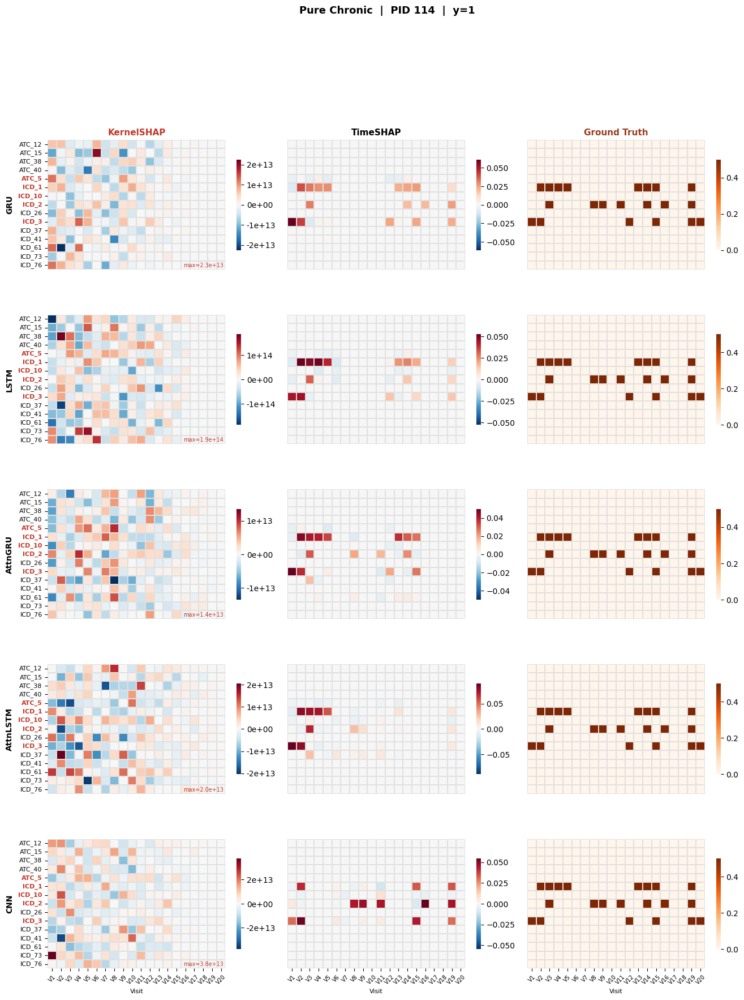

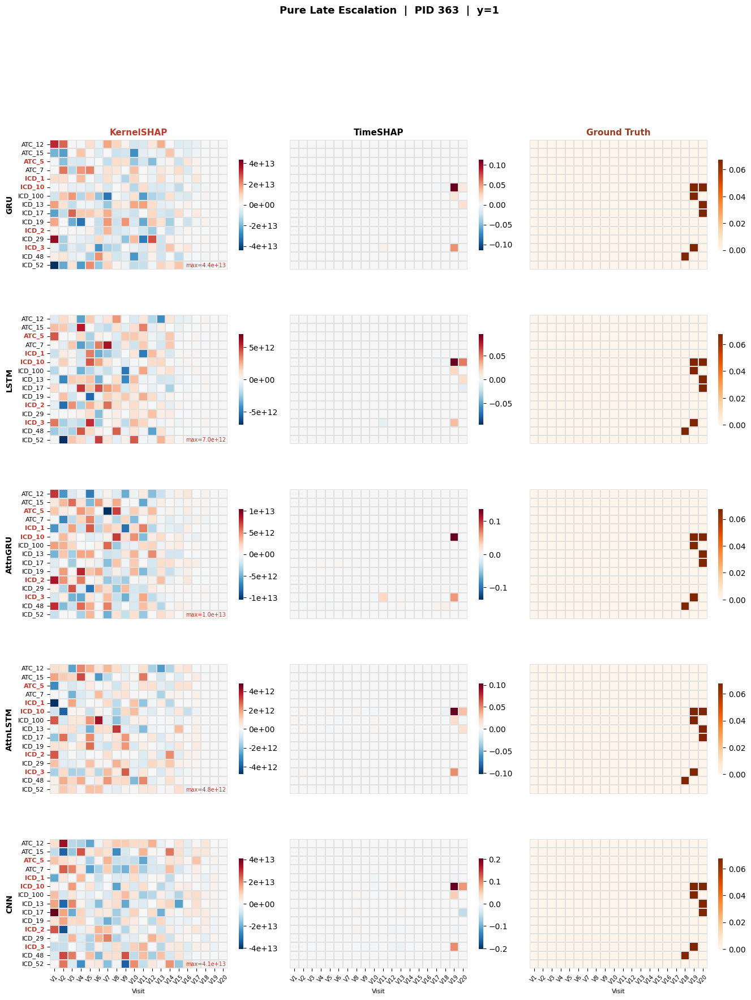

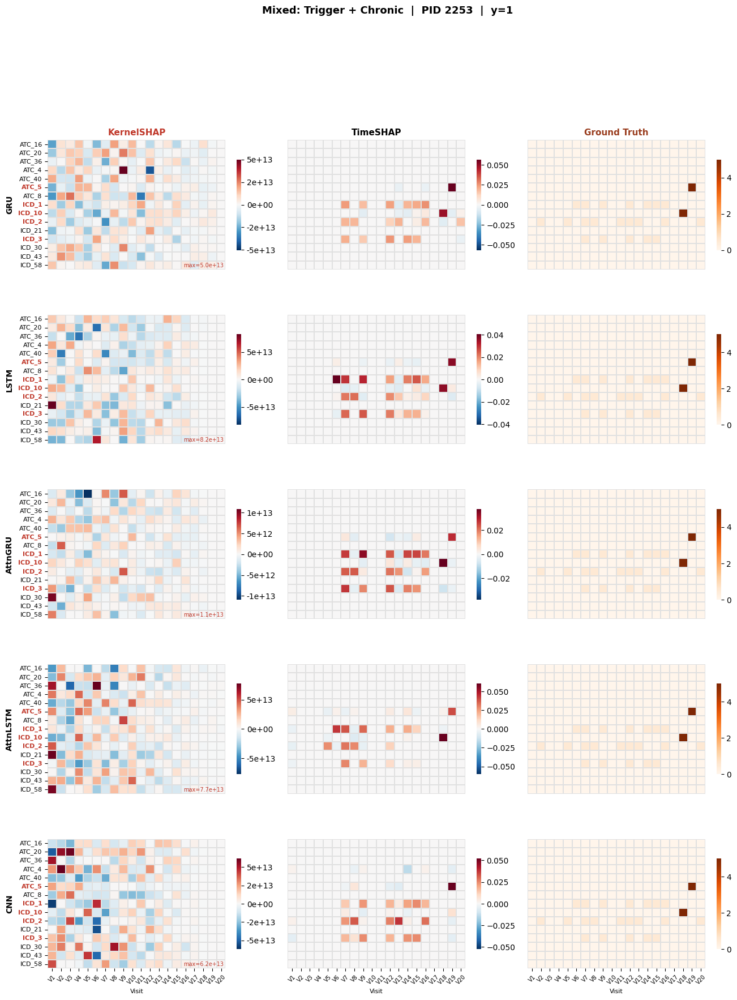

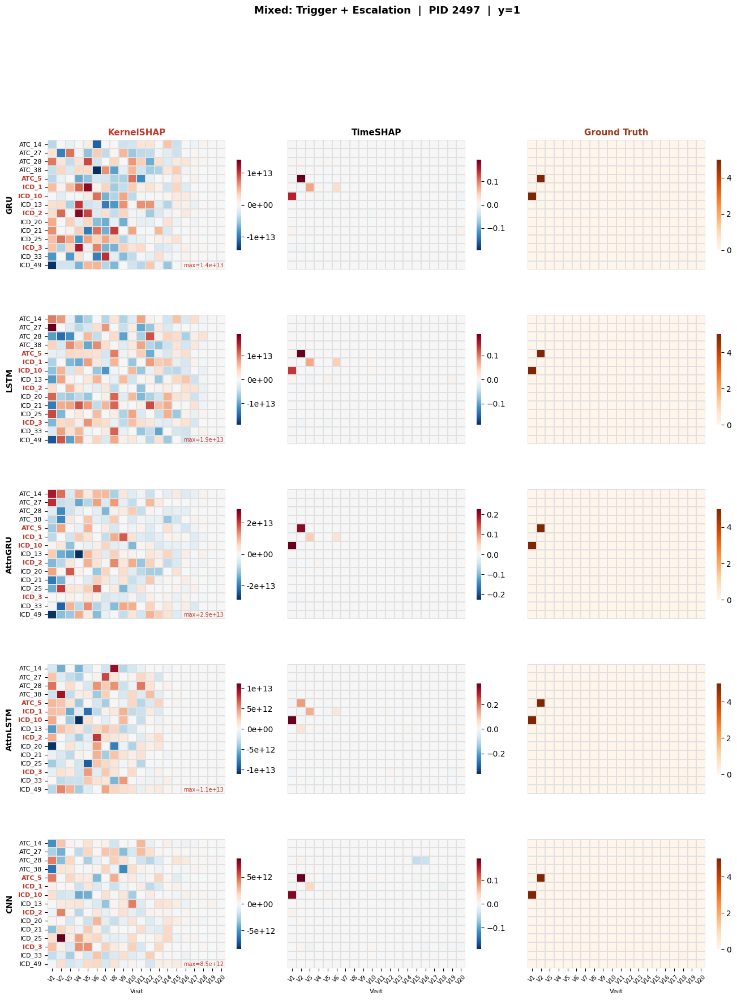

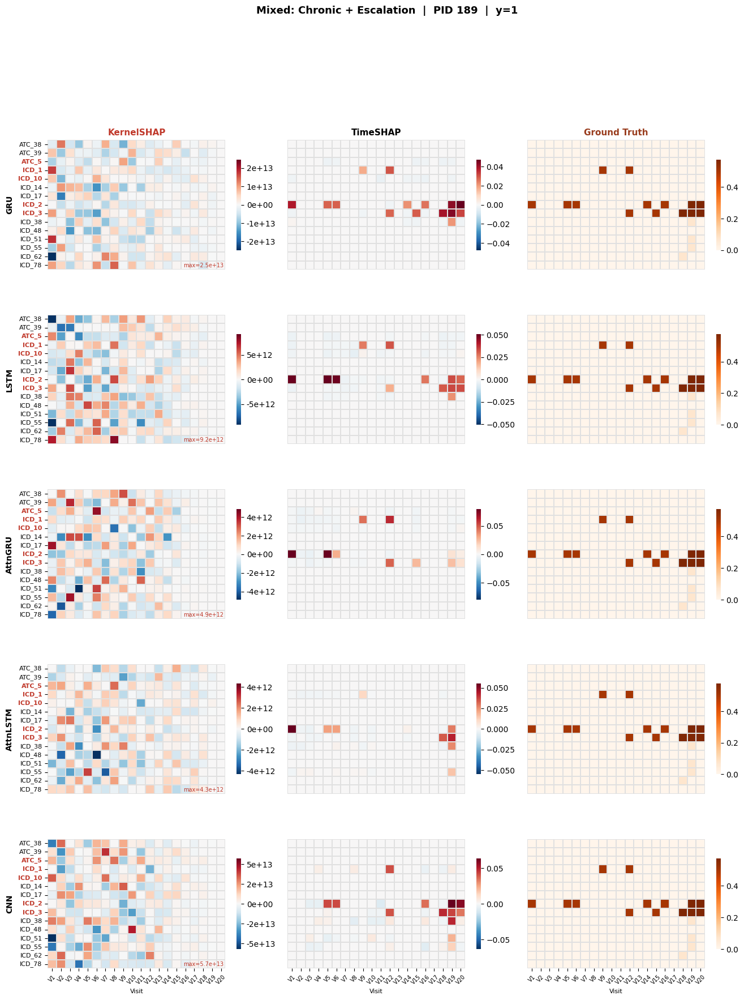

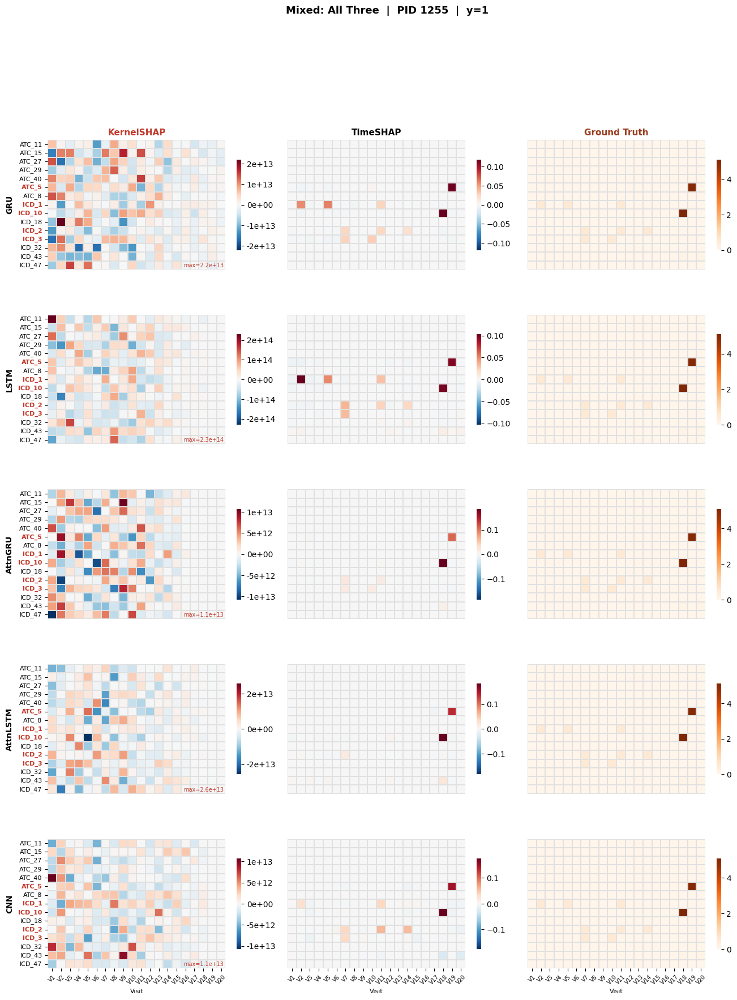

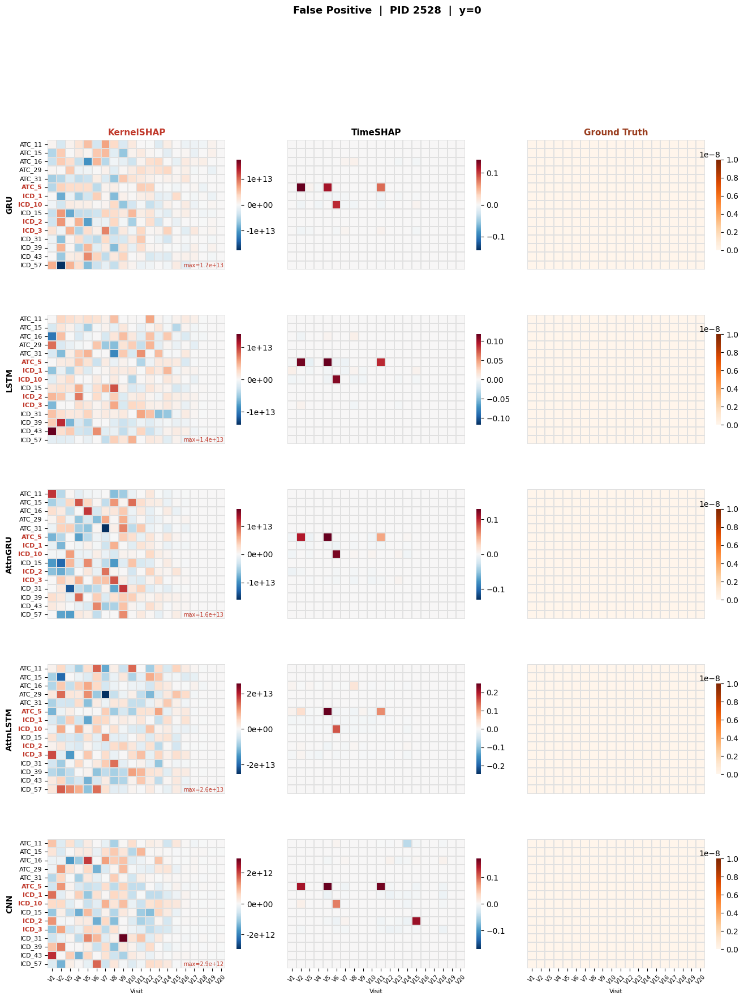

In [14]:
for ci, (case_title, test_idx) in enumerate(zip(case_titles, case_indices)):
    test_idx  = int(test_idx)
    pid_val   = int(pid_test[test_idx])
    truth_pat = truth_ntf[test_idx]
    ks_pats   = [shap_ntf_dict[k][ci, :, :n_tokens] for k in MODEL_KEYS]
    ts_pats   = [timeshap_ntf_dict[k][test_idx, :, :n_tokens]
                 if np.any(timeshap_ntf_dict[k][test_idx, :, :n_tokens] != 0) else None
                 for k in MODEL_KEYS]
    ts_valid  = [a for a in ts_pats if a is not None]
    # ── shared feature selection: all XAI arrays + always include GT features ──
    combined  = sum(np.abs(a).sum(axis=0) for a in ks_pats + (ts_valid if ts_valid else []))
    top_by    = np.argsort(combined)[-12:][::-1]
    show      = sorted(set(gt_indices) | set(top_by))[:TOP_K]
    show_names = [fnames_seq[i] for i in show]
    gt_vmax   = truth_pat[:, show].max() + 1e-8
    N_ROWS = len(MODEL_KEYS)
    fig, axes = plt.subplots(N_ROWS, 3, figsize=(16, 3.8 * N_ROWS),
                              gridspec_kw={'wspace': 0.08, 'hspace': 0.35}, squeeze=False)
    fig.suptitle(f'{case_title}  |  PID {pid_val}  |  y={int(y_test[test_idx])}',
                 fontsize=13, fontweight='bold', y=1.005)
    axes[0, 0].set_title('KernelSHAP', fontsize=11, fontweight='bold', color='#c0392b', pad=6)
    axes[0, 1].set_title('TimeSHAP',   fontsize=11, fontweight='bold', pad=6)
    axes[0, 2].set_title('Ground Truth', fontsize=11, fontweight='bold', color='#993C1D', pad=6)
    for row, (mlabel, ks, ts) in enumerate(zip(MODEL_LABELS, ks_pats, ts_pats)):
        show_xt = (row == N_ROWS - 1)
        ax = axes[row, 0]
        vmax = np.abs(ks[:, show]).max() + 1e-8
        sns.heatmap(ks[:, show].T, ax=ax, cmap='RdBu_r', center=0, vmin=-vmax, vmax=vmax,
                    xticklabels=visit_labels if show_xt else [], yticklabels=show_names,
                    linewidths=0.3, linecolor='#e0e0e0', cbar_kws={'shrink': 0.7, 'format': '%.0e'})
        ax.set_facecolor('#fff5f5')
        ax.text(0.99, 0.01, f'max={vmax:.1e}', ha='right', va='bottom', fontsize=7,
                color='#c0392b', transform=ax.transAxes)
        ax.set_ylabel(mlabel, fontsize=10, fontweight='bold', labelpad=6)
        ax.tick_params(axis='y', labelsize=8)
        for fi, f_idx in enumerate(show):
            if fnames_seq[f_idx] in gt_feats:
                ax.get_yticklabels()[fi].set_color('#c0392b')
                ax.get_yticklabels()[fi].set_fontweight('bold')
        if show_xt: ax.tick_params(axis='x', rotation=45, labelsize=7); ax.set_xlabel('Visit', fontsize=8)
        else: ax.set_xticklabels([])
        ax = axes[row, 1]
        if ts is None:
            ax.text(0.5, 0.5, 'no data', ha='center', va='center', color='gray', fontsize=11, transform=ax.transAxes)
            ax.set_xticks([]); ax.set_yticks([]); ax.set_facecolor('#f7f7f7')
        else:
            vmax = np.abs(ts[:, show]).max() + 1e-8
            sns.heatmap(ts[:, show].T, ax=ax, cmap='RdBu_r', center=0, vmin=-vmax, vmax=vmax,
                        xticklabels=visit_labels if show_xt else [], yticklabels=[],
                        linewidths=0.3, linecolor='#e0e0e0', cbar_kws={'shrink': 0.7})
            ax.set_yticks([])
            if show_xt: ax.tick_params(axis='x', rotation=45, labelsize=7); ax.set_xlabel('Visit', fontsize=8)
            else: ax.set_xticklabels([])
        ax = axes[row, 2]
        sns.heatmap(truth_pat[:, show].T, ax=ax, cmap='Oranges', vmin=0, vmax=gt_vmax,
                    xticklabels=visit_labels if show_xt else [], yticklabels=[],
                    linewidths=0.3, linecolor='#e0e0e0', cbar_kws={'shrink': 0.7})
        ax.set_yticks([])
        if show_xt: ax.tick_params(axis='x', rotation=45, labelsize=7); ax.set_xlabel('Visit', fontsize=8)
        else: ax.set_xticklabels([])
    safe = case_title.replace(' ', '_').replace(':', '').replace('+', '_')
    plt.savefig(os.path.join(out, f'ks_ts_gt_{safe}.png'), dpi=150, bbox_inches='tight')
    plt.show()


---
## KernelSHAP + WindowSHAP (3) + TimeSHAP + Ground Truth

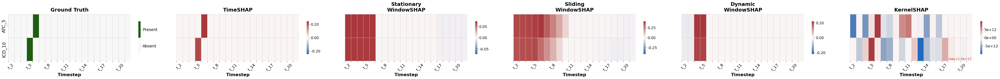

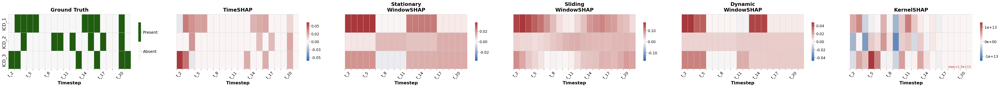

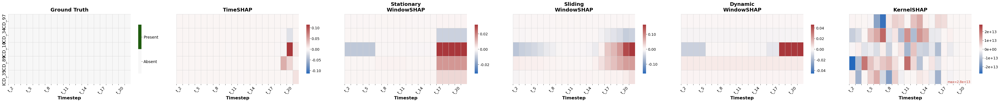

Generated GRU plots for: Pure Trigger, Pure Chronic, Pure Late Escalation


In [15]:
COL_TITLES_WS = ['Ground Truth', 'TimeSHAP', 'Stationary\nWindowSHAP', 'Sliding\nWindowSHAP',
                 'Dynamic\nWindowSHAP', 'KernelSHAP']
COL_BROKEN    = [False, False, False, False, False, True]
COL_GT        = [True, False, False, False, False, False]
N_COLS_WS     = len(COL_TITLES_WS)

# Define which cases to show
CASES_TO_SHOW = ['Pure Trigger', 'Pure Chronic', 'Pure Late Escalation']

ks_idx_lookup = {int(idx): i for i, idx in enumerate(case_indices)}

for case_title, test_idx in case_studies.items():
    # Skip cases we don't want to show
    if case_title not in CASES_TO_SHOW:
        continue
    
    test_idx  = int(test_idx)
    pid_val   = int(pid_test[test_idx])
    truth_pat = truth_ntf[test_idx]
    ws_pos    = tp_pos_map.get(test_idx)
    ci        = ks_idx_lookup.get(test_idx)
    ks_pats   = [shap_ntf_dict[k][ci, :, :n_tokens] if ci is not None
                 else np.zeros((T, n_tokens)) for k in MODEL_KEYS]
    ts_pats   = [timeshap_ntf_dict[k][test_idx, :, :n_tokens]
                 if np.any(timeshap_ntf_dict[k][test_idx, :, :n_tokens] != 0) else None
                 for k in MODEL_KEYS]
    ts_valid  = [a for a in ts_pats if a is not None]
    ws_valid  = [windowshap_ntf_dict.get(mkey, {}).get(ws_key)[ws_pos, :, :n_tokens]
                 for mkey in MODEL_KEYS for ws_key in ['stat','slid','dyn']
                 if windowshap_ntf_dict.get(mkey, {}).get(ws_key) is not None and ws_pos is not None]
    
    # ── Find GRU index ──
    gru_idx = None
    for idx, mkey in enumerate(MODEL_KEYS):
        if 'gru' in mkey.lower():
            gru_idx = idx
            break
    
    if gru_idx is None:
        print(f"Warning: GRU not found for {case_title}, skipping")
        continue
    
    # Get GRU-specific data
    ks = ks_pats[gru_idx]
    ts = ts_pats[gru_idx]
    mkey = MODEL_KEYS[gru_idx]
    mlabel = MODEL_LABELS[gru_idx]
    ws_d = windowshap_ntf_dict.get(mkey, {})
    
    # ── Case-specific feature selection ──
    if case_title == 'Pure Trigger':
        features_to_show = ['ATC_5', 'ICD_10']
    elif case_title == 'Pure Chronic':
        features_to_show = ['ICD_1', 'ICD_2', 'ICD_3']
    elif case_title == 'Pure Late Escalation':
        gt_importance = np.abs(truth_pat).sum(axis=0)
        top_n = 5
        top_indices = np.argsort(gt_importance)[-top_n:][::-1]
        features_to_show = [fnames_seq[i] for i in top_indices]
    else:
        combined = sum(np.abs(a).sum(axis=0) for a in ks_pats + ts_valid + ws_valid)
        top_by = np.argsort(combined)[-12:][::-1]
        show_indices = sorted(set(gt_indices) | set(top_by))[:TOP_K]
        features_to_show = [fnames_seq[i] for i in show_indices]
    
    # Get indices for the features to show
    show = []
    for feat in features_to_show:
        for idx, fname in enumerate(fnames_seq):
            if fname == feat:
                show.append(idx)
                break
    
    show_names = [fnames_seq[i] for i in show]
    gt_vmax = truth_pat[:, show].max() + 1e-8
    
    # Create timestep labels (t_1, t_2, t_3, ...)
    timestep_labels = [f't_{i+1}' for i in range(len(visit_labels))]
    
    # ── Simple multiplier approach for cell sizing ──
    n_features = len(show)
    n_timesteps = len(visit_labels)
    
    # Adjust these two values to control cell width and height
    base_width_per_timestep = 0.5   # Width per timestep
    base_height_per_feature = 0.5   # Height per feature
    
    # Calculate figure dimensions
    fig_width = N_COLS_WS * n_timesteps * base_width_per_timestep + 3
    fig_height = n_features * base_height_per_feature + 2
    
    # Only 1 row for GRU
    N_ROWS = 1
    fig, axes = plt.subplots(N_ROWS, N_COLS_WS, figsize=(fig_width, fig_height),
                              gridspec_kw={'wspace': 0.10, 'hspace': 0.38}, squeeze=False)
    
    # All column titles in black
    for col, ctitle in enumerate(COL_TITLES_WS):
        axes[0, col].set_title(ctitle, fontsize=18, fontweight='bold', color='black', pad=10)

    def _hm(ax, mat, is_gt=False, broken=False, show_yticks=False, show_xticks=False,
            _show=show, _show_names=show_names, _gt_vmax=gt_vmax):
        
        if is_gt:
            from matplotlib.colors import ListedColormap
            binary_cmap = ListedColormap(['#f7f7f7', '#1f5c0f'])
            
            sns.heatmap(mat[:, _show].T, ax=ax, cmap=binary_cmap,
                        vmin=0, vmax=1,
                        xticklabels=timestep_labels if show_xticks else [],
                        yticklabels=_show_names if show_yticks else [],
                        linewidths=0.5, linecolor='#d0d0d0',
                        cbar_kws={'shrink': 0.7, 'aspect': 15, 'ticks': [0.25, 0.75]},
                        square=False)
            
            cbar = ax.collections[0].colorbar
            cbar.ax.set_yticklabels(['Absent', 'Present'])
            cbar.ax.tick_params(labelsize=14)
        else:
            vmax = np.abs(mat[:, _show]).max() + 1e-8
            
            sns.heatmap(mat[:, _show].T, ax=ax, cmap='vlag',
                        center=0, vmin=-vmax, vmax=vmax,
                        xticklabels=timestep_labels if show_xticks else [],
                        yticklabels=_show_names if show_yticks else [],
                        linewidths=0.5, linecolor='#d0d0d0',
                        cbar_kws={'shrink': 0.7, 'aspect': 15, 'format': '%.0e' if broken else '%.2f'},
                        square=False)
            
            cbar = ax.collections[0].colorbar
            cbar.ax.tick_params(labelsize=13)
        
        if broken:
            ax.set_facecolor('#fff5f5')
            vmax = np.abs(mat[:, _show]).max() + 1e-8
            ax.text(0.99, 0.01, f'max={vmax:.1e}', ha='right', va='bottom',
                    fontsize=11, color='#c0392b', transform=ax.transAxes)
        
        if show_yticks:
            ax.tick_params(axis='y', labelsize=16, labelcolor='black')
        else: 
            ax.set_yticks([])
        
        if show_xticks:
            n_labels = len(timestep_labels)
            
            # Show labels starting at t_2 (index 1) every 3 steps, ending with t_20
            # Pattern: show at indices 1, 4, 7, 10, 13, 16, 19 (t_2, t_5, t_8, t_11, t_14, t_17, t_20)
            ax.set_xticks(range(n_labels))
            labels = []
            for i in range(n_labels):
                # Start at index 1 (t_2), then every 3rd: 1, 4, 7, 10, 13, 16, 19
                if (i - 1) % 3 == 0 and i >= 1:
                    labels.append(timestep_labels[i])
                else:
                    labels.append('')
            
            ax.set_xticklabels(labels, rotation=45, ha='right')
            ax.tick_params(axis='x', labelsize=14)
            ax.set_xlabel('Timestep', fontsize=16, fontweight='bold')
        else: 
            ax.set_xticklabels([])

    def _ph(ax, show_xticks=False):
        ax.text(0.5, 0.5, 'no data', ha='center', va='center',
                color='#aaaaaa', fontsize=14, style='italic', transform=ax.transAxes)
        ax.set_facecolor('#f5f5f5'); ax.set_xticks([]); ax.set_yticks([])
        if show_xticks: ax.set_xlabel('Timestep', fontsize=16, fontweight='bold')

    # Plot only GRU row
    row = 0
    show_xt = True
    
    # Column 0: Ground Truth
    _hm(axes[row, 0], truth_pat, is_gt=True, show_yticks=True, show_xticks=show_xt)
    
    # Column 1: TimeSHAP
    if ts is not None: 
        _hm(axes[row, 1], ts, show_yticks=False, show_xticks=show_xt)
    else: 
        _ph(axes[row, 1], show_xticks=show_xt)
    
    # Columns 2-4: WindowSHAP
    for col, ws_key in enumerate(['stat', 'slid', 'dyn'], start=2):
        arr = ws_d.get(ws_key)
        if arr is not None and ws_pos is not None: 
            _hm(axes[row, col], arr[ws_pos, :, :n_tokens], show_yticks=False, show_xticks=show_xt)
        else: 
            _ph(axes[row, col], show_xticks=show_xt)
    
    # Column 5: KernelSHAP
    _hm(axes[row, 5], ks, broken=True, show_yticks=False, show_xticks=show_xt)
    
    safe = case_title.replace(' ', '_').replace(':', '').replace('+', '_')
    plt.savefig(os.path.join(out, f'ks_ws_ts_gt_GRU_{safe}.png'), dpi=600, bbox_inches='tight')
    plt.show()

print(f"Generated GRU plots for: {', '.join(CASES_TO_SHOW)}")

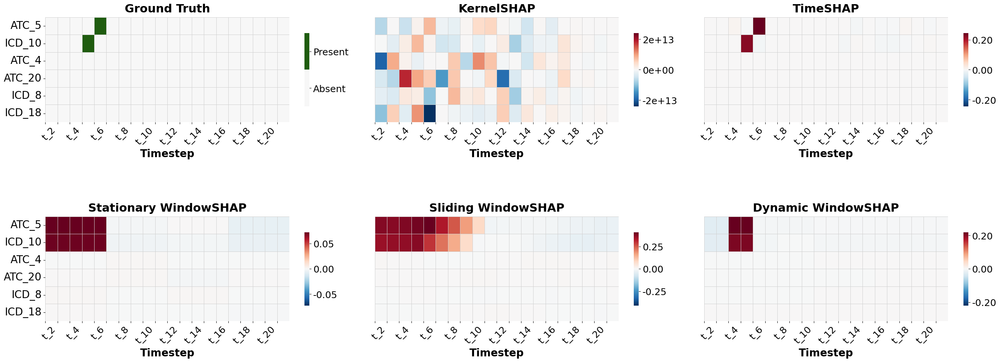

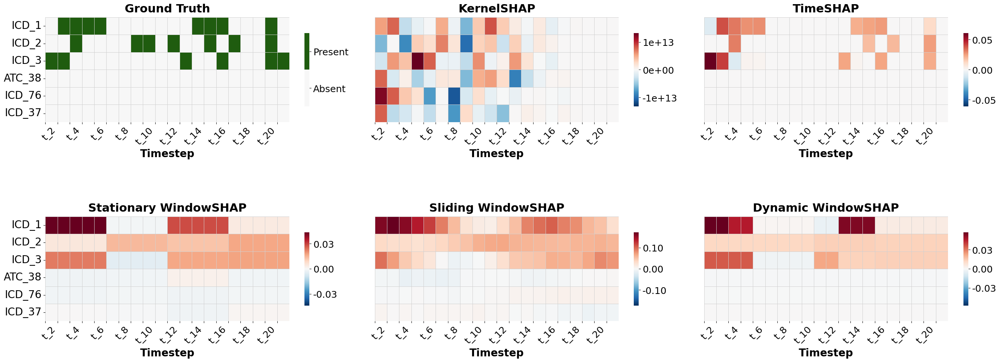

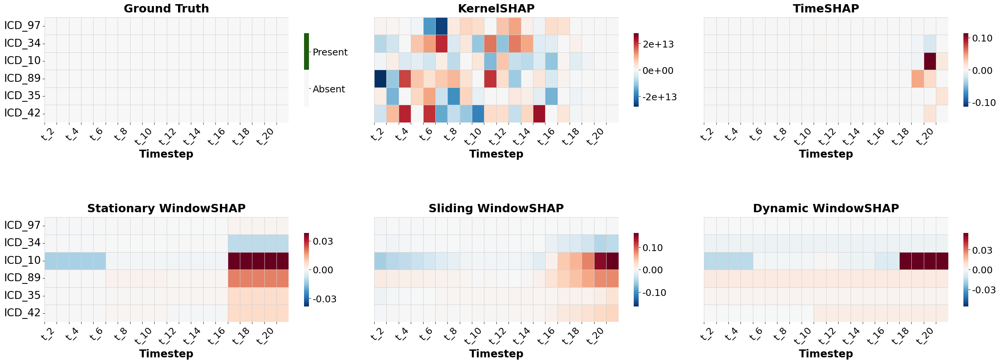

Generated GRU plots for: Pure Trigger, Pure Chronic, Pure Late Escalation


In [16]:
COL_TITLES_WS_ROW1 = ['Ground Truth', 'KernelSHAP', 'TimeSHAP']
COL_TITLES_WS_ROW2 = ['Stationary WindowSHAP', 'Sliding WindowSHAP', 'Dynamic WindowSHAP']

# Define which cases to show
CASES_TO_SHOW = ['Pure Trigger', 'Pure Chronic', 'Pure Late Escalation']

ks_idx_lookup = {int(idx): i for i, idx in enumerate(case_indices)}

for case_title, test_idx in case_studies.items():
    # Skip cases we don't want to show
    if case_title not in CASES_TO_SHOW:
        continue
    
    test_idx  = int(test_idx)
    pid_val   = int(pid_test[test_idx])
    truth_pat = truth_ntf[test_idx]
    ws_pos    = tp_pos_map.get(test_idx)
    ci        = ks_idx_lookup.get(test_idx)
    ks_pats   = [shap_ntf_dict[k][ci, :, :n_tokens] if ci is not None
                 else np.zeros((T, n_tokens)) for k in MODEL_KEYS]
    ts_pats   = [timeshap_ntf_dict[k][test_idx, :, :n_tokens]
                 if np.any(timeshap_ntf_dict[k][test_idx, :, :n_tokens] != 0) else None
                 for k in MODEL_KEYS]
    ts_valid  = [a for a in ts_pats if a is not None]
    ws_valid  = [windowshap_ntf_dict.get(mkey, {}).get(ws_key)[ws_pos, :, :n_tokens]
                 for mkey in MODEL_KEYS for ws_key in ['stat','slid','dyn']
                 if windowshap_ntf_dict.get(mkey, {}).get(ws_key) is not None and ws_pos is not None]
    
    # ── Find GRU index ──
    gru_idx = None
    for idx, mkey in enumerate(MODEL_KEYS):
        if 'gru' in mkey.lower():
            gru_idx = idx
            break
    
    if gru_idx is None:
        print(f"Warning: GRU not found for {case_title}, skipping")
        continue
    
    # Get GRU-specific data
    ks = ks_pats[gru_idx]
    ts = ts_pats[gru_idx]
    mkey = MODEL_KEYS[gru_idx]
    mlabel = MODEL_LABELS[gru_idx]
    ws_d = windowshap_ntf_dict.get(mkey, {})
    
    # ── Feature selection: Always show 6 features ──
    # First, identify ground truth features for this case
    if case_title == 'Pure Trigger':
        gt_features = ['ATC_5', 'ICD_10']
    elif case_title == 'Pure Chronic':
        gt_features = ['ICD_1', 'ICD_2', 'ICD_3']
    elif case_title == 'Pure Late Escalation':
        # For late escalation, get top 6 features by ground truth importance
        gt_importance = np.abs(truth_pat).sum(axis=0)
        top_n = 6  # Get all 6 from ground truth
        top_indices = np.argsort(gt_importance)[-top_n:][::-1]
        gt_features = [fnames_seq[i] for i in top_indices]
    else:
        gt_features = []
    
    # Get indices of ground truth features
    gt_feature_indices = []
    for feat in gt_features:
        for idx, fname in enumerate(fnames_seq):
            if fname == feat:
                gt_feature_indices.append(idx)
                break
    
    # For Trigger and Chronic, add more features; for Late Escalation, use only GT features
    if case_title == 'Pure Late Escalation':
        # Use only the ground truth features (top 6)
        show = gt_feature_indices[:6]
    else:
        # Calculate combined importance across all methods to find additional features
        combined = sum(np.abs(a).sum(axis=0) for a in ks_pats + ts_valid + ws_valid)
        
        # Get top features by combined importance, excluding ground truth features
        remaining_indices = np.array([i for i in range(len(fnames_seq)) if i not in gt_feature_indices])
        remaining_importance = combined[remaining_indices]
        sorted_order = np.argsort(remaining_importance)[::-1]
        top_remaining_indices = remaining_indices[sorted_order]
        
        # Combine: ground truth features + top additional features to reach 6 total
        n_additional = max(0, 6 - len(gt_feature_indices))
        additional_indices = top_remaining_indices[:n_additional].tolist()
        
        # Final feature set: ground truth features first, then additional
        show = gt_feature_indices + additional_indices
        show = show[:6]  # Ensure we have exactly 6 features
    
    show_names = [fnames_seq[i] for i in show]
    gt_vmax = truth_pat[:, show].max() + 1e-8
    
    # Create timestep labels (t_1, t_2, t_3, ...)
    timestep_labels = [f't_{i+1}' for i in range(len(visit_labels))]
    
    # ── Simple multiplier approach for cell sizing ──
    n_features = len(show)
    n_timesteps = len(visit_labels)
    
    # Adjust these two values to control cell width and height
    base_width_per_timestep = 0.5   # Width per timestep
    base_height_per_feature = 0.5   # Height per feature
    
    # Calculate figure dimensions - 2 rows, 3 columns
    N_ROWS = 2
    N_COLS = 3
    subplot_width = n_timesteps * base_width_per_timestep
    subplot_height = n_features * base_height_per_feature
    
    fig_width = N_COLS * subplot_width + 3
    fig_height = N_ROWS * subplot_height + 4.5
    
    fig, axes = plt.subplots(N_ROWS, N_COLS, figsize=(fig_width, fig_height),
                              gridspec_kw={'wspace': 0.08, 'hspace': 0.9}, squeeze=False)
    
    # Set titles for row 1
    for col, ctitle in enumerate(COL_TITLES_WS_ROW1):
        axes[0, col].set_title(ctitle, fontsize=22, fontweight='bold', color='black', pad=10)
    
    # Set titles for row 2
    for col, ctitle in enumerate(COL_TITLES_WS_ROW2):
        axes[1, col].set_title(ctitle, fontsize=22, fontweight='bold', color='black', pad=10)

    def _hm(ax, mat, is_gt=False, broken=False, show_yticks=False, show_xticks=False,
            _show=show, _show_names=show_names, _gt_vmax=gt_vmax):
        
        if is_gt:
            from matplotlib.colors import ListedColormap
            binary_cmap = ListedColormap(['#f7f7f7', '#1f5c0f'])
            
            sns.heatmap(mat[:, _show].T, ax=ax, cmap=binary_cmap,
                        vmin=0, vmax=1,
                        xticklabels=timestep_labels if show_xticks else [],
                        yticklabels=_show_names if show_yticks else [],
                        linewidths=0.5, linecolor='#d0d0d0',
                        cbar_kws={'shrink': 0.7, 'aspect': 15, 'ticks': [0.25, 0.75]},
                        square=False)
            
            cbar = ax.collections[0].colorbar
            cbar.ax.set_yticklabels(['Absent', 'Present'])
            cbar.ax.tick_params(labelsize=18)  # INCREASED from 16 to 18
        else:
            # Each method uses its own scale (non-normalized)
            vmax = np.abs(mat[:, _show]).max() + 1e-8
            
            sns.heatmap(mat[:, _show].T, ax=ax, cmap='RdBu_r',
                        center=0, vmin=-vmax, vmax=vmax,
                        xticklabels=timestep_labels if show_xticks else [],
                        yticklabels=_show_names if show_yticks else [],
                        linewidths=0.5, linecolor='#d0d0d0',
                        cbar_kws={'shrink': 0.7, 'aspect': 15, 'format': '%.0e' if broken else '%.2f'},
                        square=False)
            
            cbar = ax.collections[0].colorbar
            cbar.ax.tick_params(labelsize=18)  # INCREASED from 16 to 18
        
        if broken:
            ax.set_facecolor('#fff5f5')
        
        if show_yticks:
            # Horizontal y-tick labels - 20pt
            ax.tick_params(axis='y', labelsize=20, labelcolor='black', rotation=0)
        else: 
            ax.set_yticks([])
        
        if show_xticks:
            n_labels = len(timestep_labels)
            ax.set_xticks(range(n_labels))
            
            # Show every second timestep: t_2, t_4, t_6, t_8, t_10, ..., t_20
            labels = []
            for i in range(n_labels):
                if i % 2 == 1:  # Odd indices
                    labels.append(timestep_labels[i])
                else:
                    labels.append('')
            
            ax.set_xticklabels(labels, rotation=45, ha='right')
            ax.tick_params(axis='x', labelsize=18)
            ax.set_xlabel('Timestep', fontsize=20, fontweight='bold')
        else: 
            ax.set_xticklabels([])

    def _ph(ax, show_xticks=False):
        ax.text(0.5, 0.5, 'no data', ha='center', va='center',
                color='#aaaaaa', fontsize=14, style='italic', transform=ax.transAxes)
        ax.set_facecolor('#f5f5f5'); ax.set_xticks([]); ax.set_yticks([])
        if show_xticks: ax.set_xlabel('Timestep', fontsize=20, fontweight='bold')

    # ── Row 1: Ground Truth, KernelSHAP, TimeSHAP ──
    _hm(axes[0, 0], truth_pat, is_gt=True, show_yticks=True, show_xticks=True)
    _hm(axes[0, 1], ks, broken=True, show_yticks=False, show_xticks=True)
    
    if ts is not None: 
        _hm(axes[0, 2], ts, broken=False, show_yticks=False, show_xticks=True)
    else: 
        _ph(axes[0, 2], show_xticks=True)
    
    # ── Row 2: WindowSHAP variants ──
    arr_stat = ws_d.get('stat')
    if arr_stat is not None and ws_pos is not None:
        _hm(axes[1, 0], arr_stat[ws_pos, :, :n_tokens], broken=False, show_yticks=True, show_xticks=True)
    else: 
        _ph(axes[1, 0], show_xticks=True)
    
    arr_slid = ws_d.get('slid')
    if arr_slid is not None and ws_pos is not None:
        _hm(axes[1, 1], arr_slid[ws_pos, :, :n_tokens], broken=False, show_yticks=False, show_xticks=True)
    else: 
        _ph(axes[1, 1], show_xticks=True)
    
    arr_dyn = ws_d.get('dyn')
    if arr_dyn is not None and ws_pos is not None:
        _hm(axes[1, 2], arr_dyn[ws_pos, :, :n_tokens], broken=False, show_yticks=False, show_xticks=True)
    else: 
        _ph(axes[1, 2], show_xticks=True)
    
    safe = case_title.replace(' ', '_').replace(':', '').replace('+', '_')
    plt.savefig(os.path.join(out, f'ks_ws_ts_gt_GRU_{safe}.png'), dpi=600, bbox_inches='tight')
    plt.show()

print(f"Generated GRU plots for: {', '.join(CASES_TO_SHOW)}")

---
## IG — global importance bars

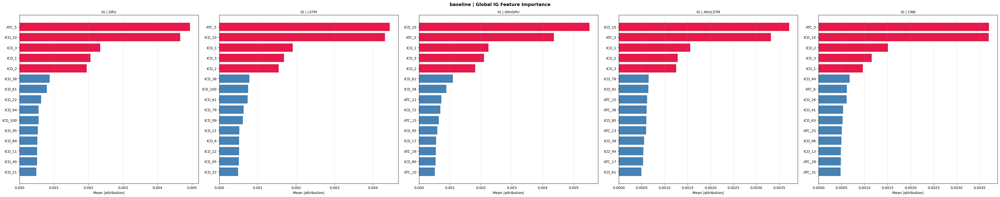

In [17]:
n_cols = len(MODEL_IG)
fig, axes = plt.subplots(1, n_cols, figsize=(8 * n_cols, 8))
fig.suptitle(f'{SCENARIO_NAME} | Global IG Feature Importance', fontsize=13, fontweight='bold')
for ax, (mname, ntf) in zip(axes, MODEL_IG):
    imp   = utils.global_importance_per_feature(ntf[:, :, :n_tokens])
    top15 = np.argsort(imp)[::-1][:15]
    cols  = [GT_COLOR if fnames_seq[j] in GT_FEATURES else DEFAULT_COLOR for j in top15]
    ax.barh([fnames_seq[j] for j in top15[::-1]], imp[top15[::-1]], color=cols[::-1])
    ax.set_title(f'IG | {mname}', fontsize=10)
    ax.set_xlabel('Mean |attribution|')
    ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.savefig(os.path.join(out, 'ig_global_bars.png'), dpi=150, bbox_inches='tight')
plt.show()

## IG — case study heatmaps

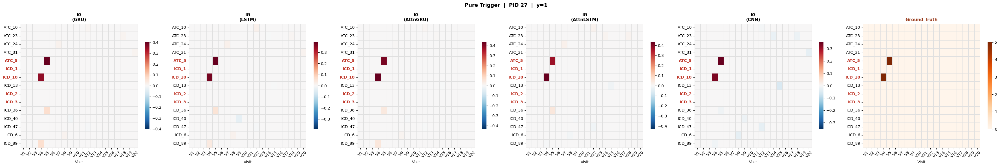

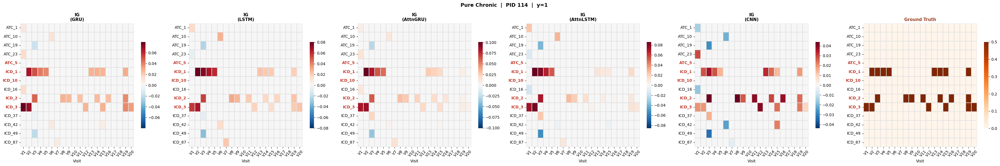

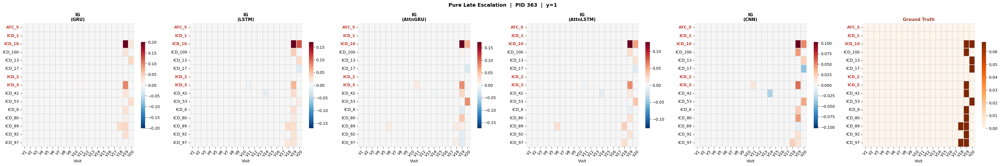

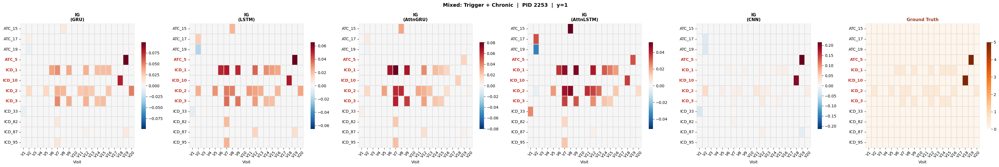

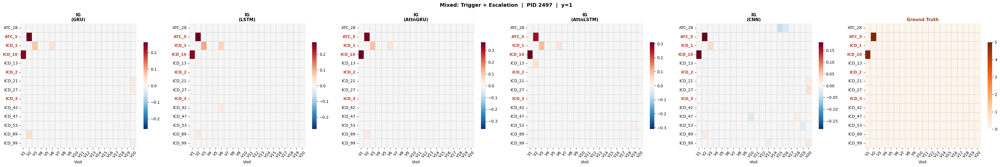

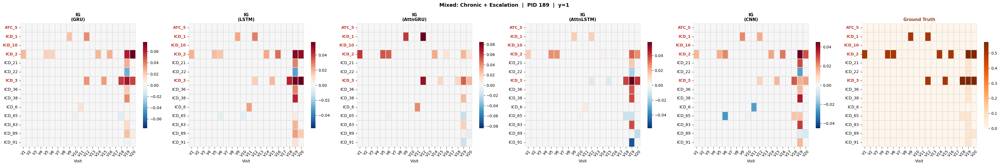

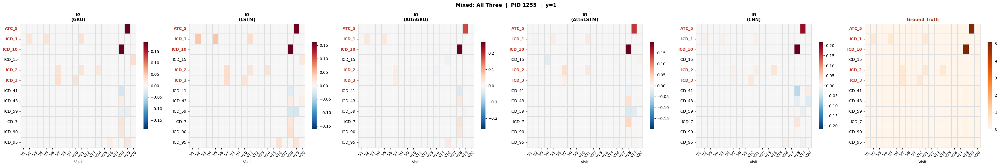

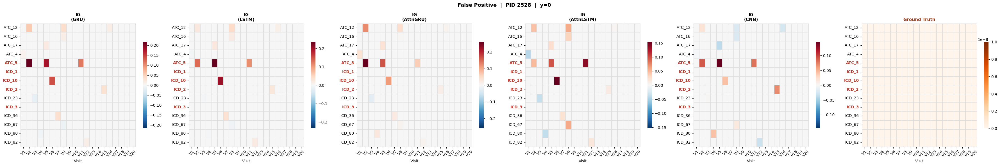

In [18]:
gt_ids_set = set(gt_indices)
for case_title, p_idx in case_studies.items():
    p_idx   = int(p_idx)
    pid_val = int(pid_test[p_idx])
    pat_maps = {}
    for mname, ig_ntf in MODEL_IG:
        attr = ig_ntf[p_idx, :, :n_tokens].copy()
        attr = attr / (np.sum(np.abs(attr)) + 1e-8)
        pat_maps[f'IG\n({mname})'] = attr
    pat_maps['Ground Truth'] = truth_ntf[p_idx]
    combined_imp = sum(np.abs(mat).sum(axis=0) for t, mat in pat_maps.items() if t != 'Ground Truth')
    top_by     = np.argsort(combined_imp)[-12:][::-1]
    show       = sorted(set(gt_ids_set) | set(top_by))[:TOP_K]
    show_names = [fnames_seq[i] for i in show]
    n_panels   = len(pat_maps)
    fig, axes  = plt.subplots(1, n_panels, figsize=(6 * n_panels, 6))
    fig.suptitle(f'{case_title}  |  PID {pid_val}  |  y={int(y_test[p_idx])}',
                 fontsize=13, fontweight='bold')
    for ax, (panel_title, mat) in zip(axes, pat_maps.items()):
        is_gt  = panel_title == 'Ground Truth'
        m_show = mat[:, show]; vmax = np.abs(m_show).max() + 1e-8
        sns.heatmap(m_show.T, ax=ax, cmap='Oranges' if is_gt else 'RdBu_r',
                    center=None if is_gt else 0, vmin=0 if is_gt else -vmax, vmax=vmax,
                    xticklabels=visit_labels, yticklabels=show_names,
                    linewidths=0.3, linecolor='#e0e0e0', cbar_kws={'shrink': 0.7})
        ax.set_title(panel_title, fontsize=11, fontweight='bold',
                     color='#993C1D' if is_gt else 'black')
        ax.set_xlabel('Visit'); ax.tick_params(axis='x', rotation=45)
        for fi, f_idx in enumerate(show):
            if fnames_seq[f_idx] in GT_FEATURES:
                ax.get_yticklabels()[fi].set_color('#c0392b')
                ax.get_yticklabels()[fi].set_fontweight('bold')
    plt.tight_layout()
    safe = case_title.replace(' ', '_').replace(':', '').replace('+', '_')
    plt.savefig(os.path.join(out, f'ig_case_{safe}.png'), dpi=150, bbox_inches='tight')
    plt.show()

---
## EG — global importance bars

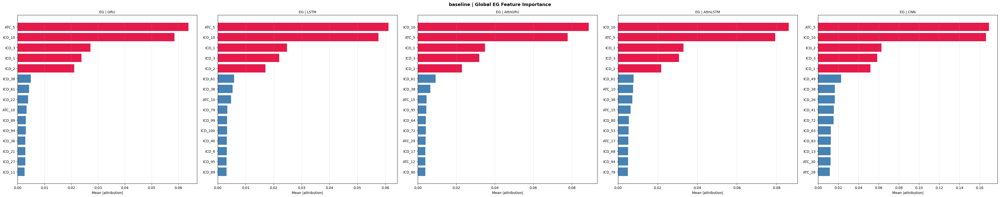

In [19]:
n_cols = len(MODEL_EG_LIST)
fig, axes = plt.subplots(1, n_cols, figsize=(8 * n_cols, 8))
fig.suptitle(f'{SCENARIO_NAME} | Global EG Feature Importance', fontsize=13, fontweight='bold')
for ax, (mname, ntf) in zip(axes, MODEL_EG_LIST):
    imp   = utils.global_importance_per_feature(ntf[:, :, :n_tokens])
    top15 = np.argsort(imp)[::-1][:15]
    cols  = [GT_COLOR if fnames_seq[j] in GT_FEATURES else DEFAULT_COLOR for j in top15]
    ax.barh([fnames_seq[j] for j in top15[::-1]], imp[top15[::-1]], color=cols[::-1])
    ax.set_title(f'EG | {mname}', fontsize=10)
    ax.set_xlabel('Mean |attribution|')
    ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.savefig(os.path.join(out, 'eg_global_bars.png'), dpi=150, bbox_inches='tight')
plt.show()

## EG — case study heatmaps

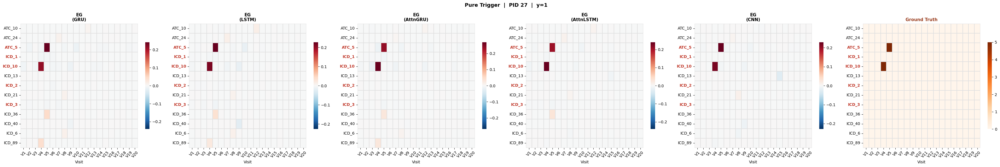

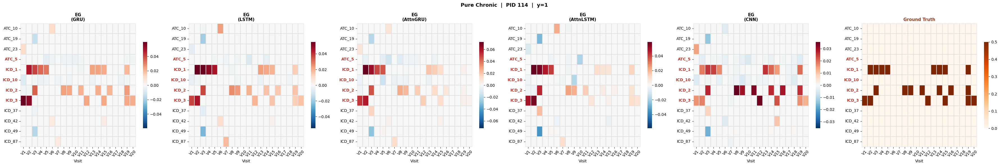

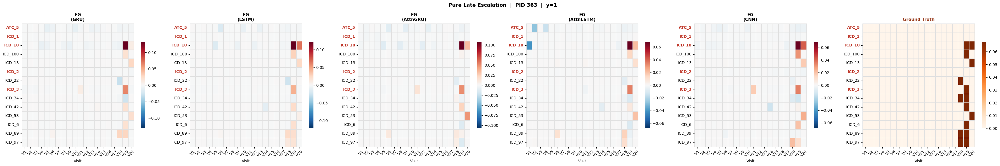

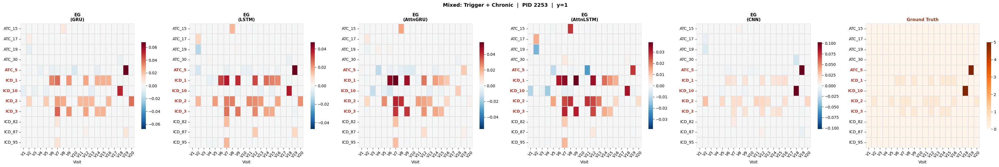

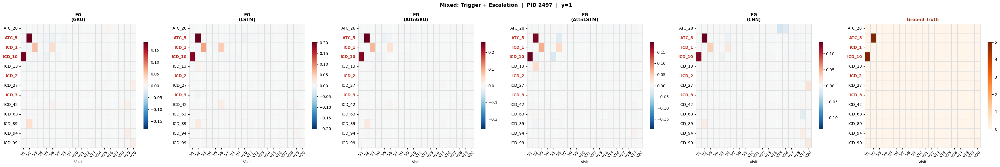

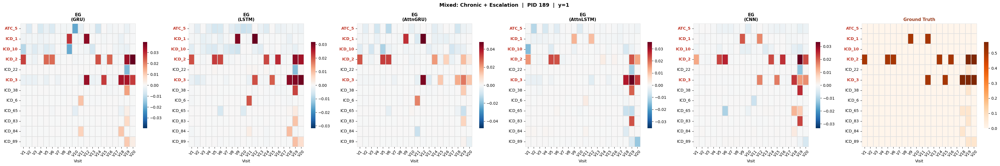

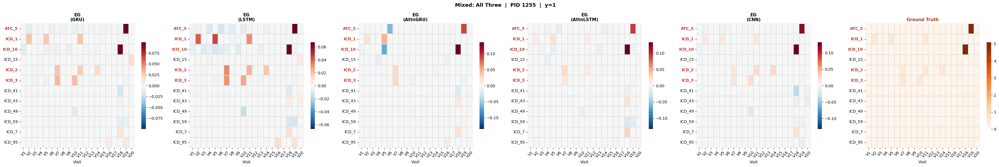

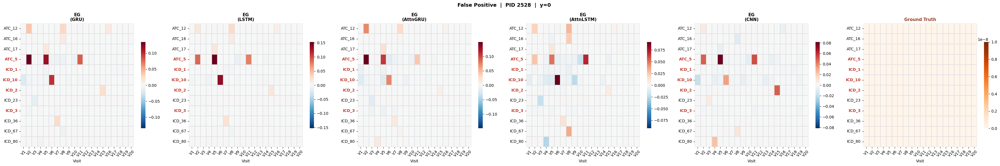

In [20]:
for case_title, p_idx in case_studies.items():
    p_idx   = int(p_idx)
    pid_val = int(pid_test[p_idx])
    pat_maps = {}
    for mname, eg_ntf in MODEL_EG_LIST:
        attr = eg_ntf[p_idx, :, :n_tokens].copy()
        attr = attr / (np.sum(np.abs(attr)) + 1e-8)
        pat_maps[f'EG\n({mname})'] = attr
    pat_maps['Ground Truth'] = truth_ntf[p_idx]
    combined_imp = sum(np.abs(mat).sum(axis=0) for t, mat in pat_maps.items() if t != 'Ground Truth')
    top_by     = np.argsort(combined_imp)[-12:][::-1]
    show       = sorted(set(gt_ids_set) | set(top_by))[:TOP_K]
    show_names = [fnames_seq[i] for i in show]
    n_panels   = len(pat_maps)
    fig, axes  = plt.subplots(1, n_panels, figsize=(6 * n_panels, 6))
    fig.suptitle(f'{case_title}  |  PID {pid_val}  |  y={int(y_test[p_idx])}',
                 fontsize=13, fontweight='bold')
    for ax, (panel_title, mat) in zip(axes, pat_maps.items()):
        is_gt  = panel_title == 'Ground Truth'
        m_show = mat[:, show]; vmax = np.abs(m_show).max() + 1e-8
        sns.heatmap(m_show.T, ax=ax, cmap='Oranges' if is_gt else 'RdBu_r',
                    center=None if is_gt else 0, vmin=0 if is_gt else -vmax, vmax=vmax,
                    xticklabels=visit_labels, yticklabels=show_names,
                    linewidths=0.3, linecolor='#e0e0e0', cbar_kws={'shrink': 0.7})
        ax.set_title(panel_title, fontsize=11, fontweight='bold',
                     color='#993C1D' if is_gt else 'black')
        ax.set_xlabel('Visit'); ax.tick_params(axis='x', rotation=45)
        for fi, f_idx in enumerate(show):
            if fnames_seq[f_idx] in GT_FEATURES:
                ax.get_yticklabels()[fi].set_color('#c0392b')
                ax.get_yticklabels()[fi].set_fontweight('bold')
    plt.tight_layout()
    safe = case_title.replace(' ', '_').replace(':', '').replace('+', '_')
    plt.savefig(os.path.join(out, f'eg_case_{safe}.png'), dpi=150, bbox_inches='tight')
    plt.show()

---
## EG + IG + Ground Truth  (rows = models)

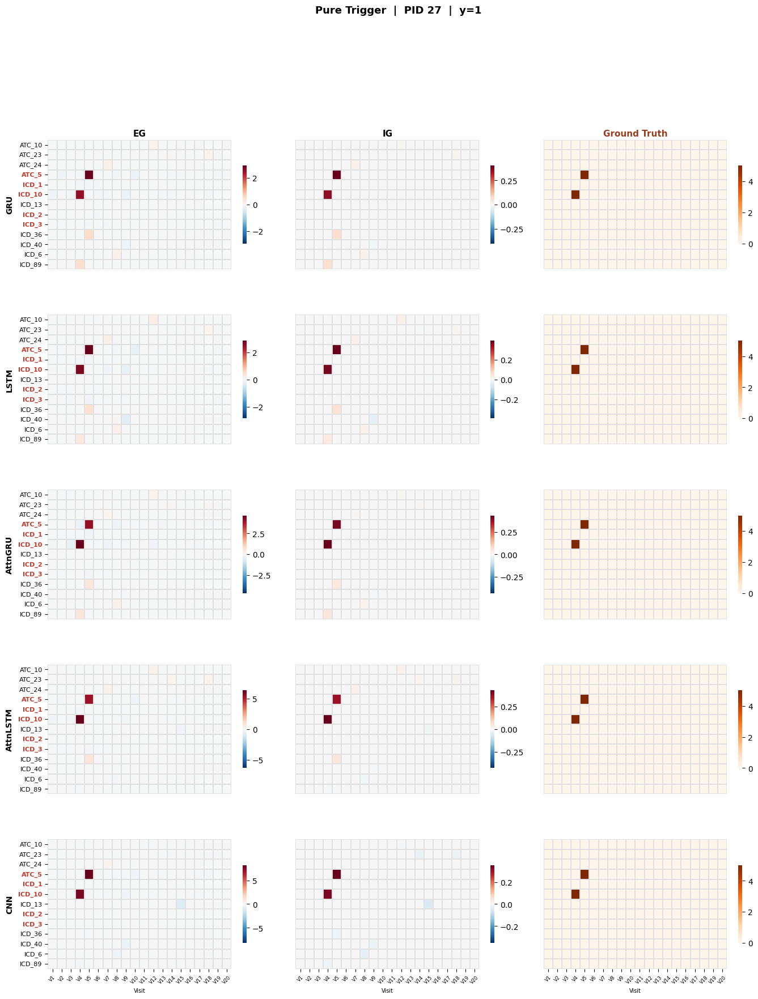

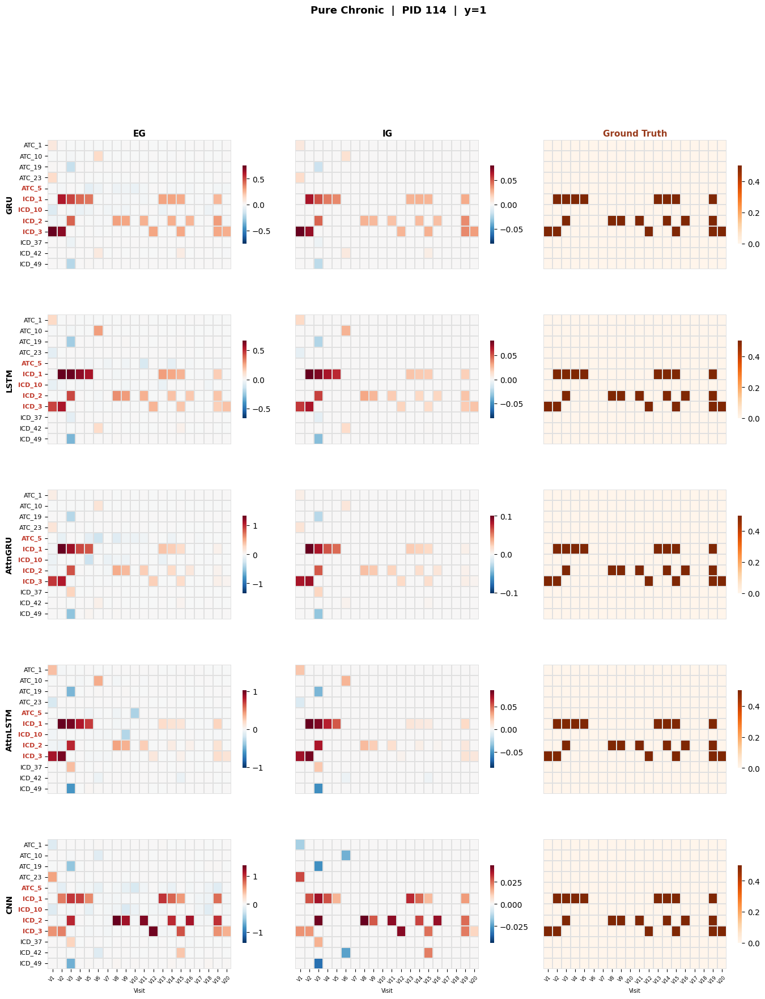

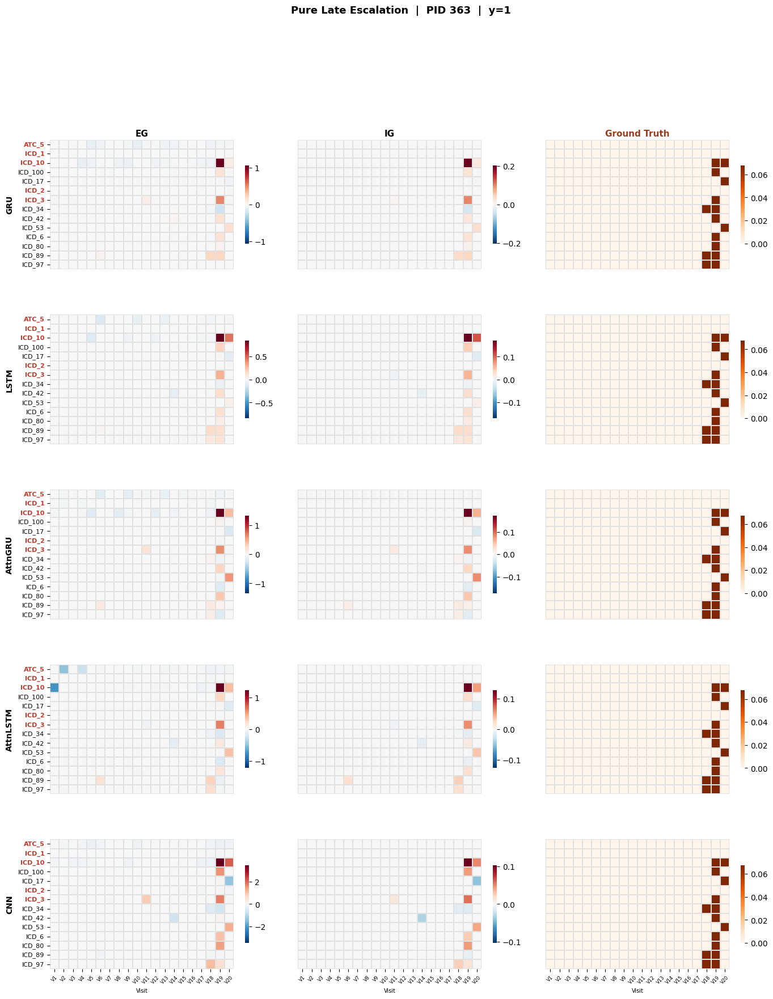

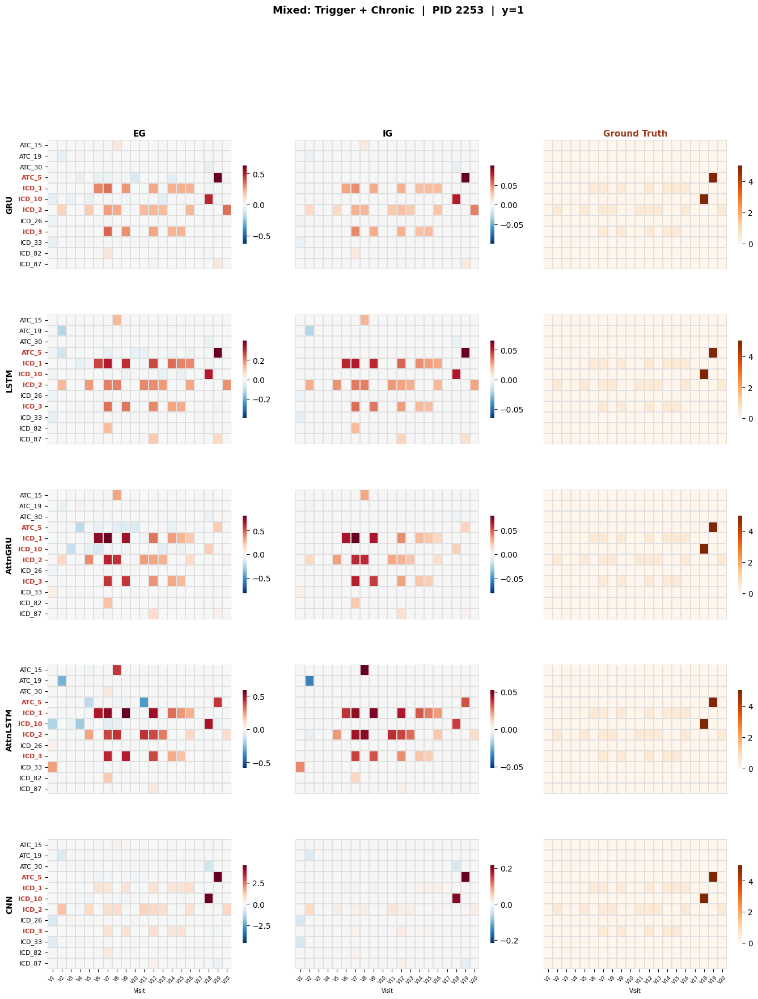

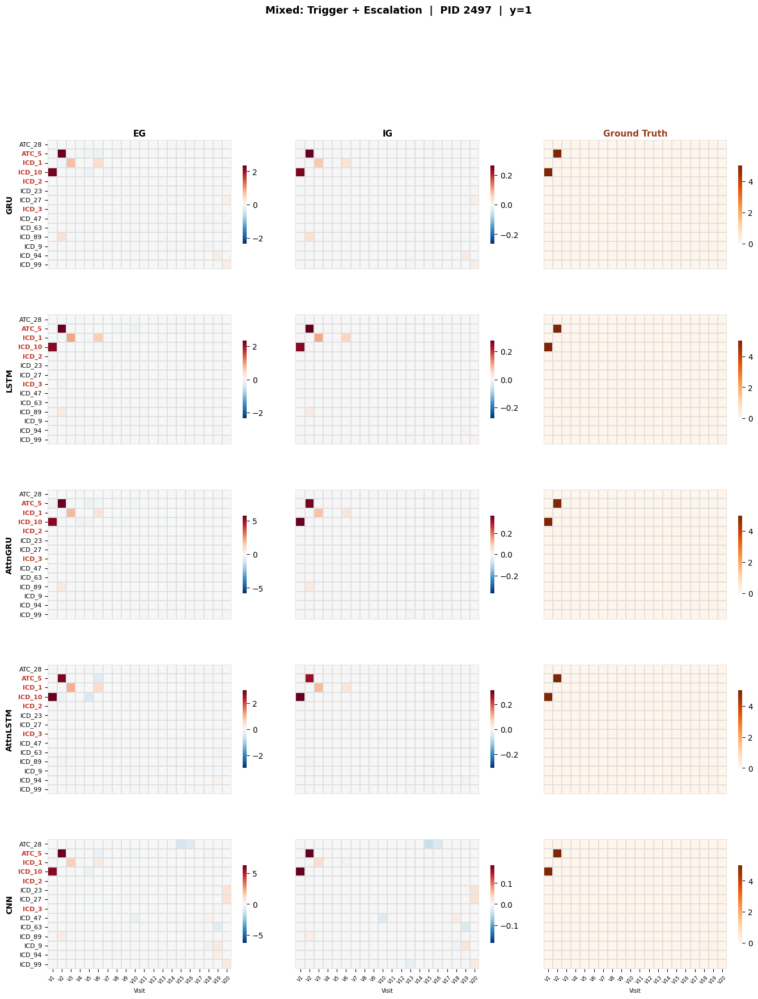

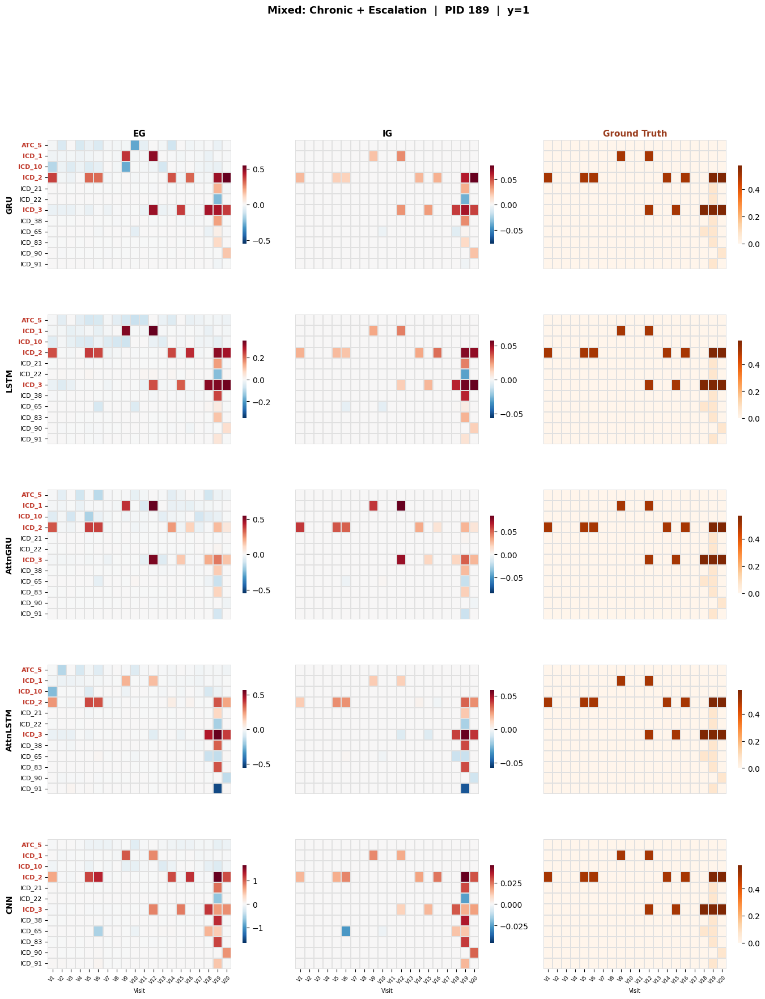

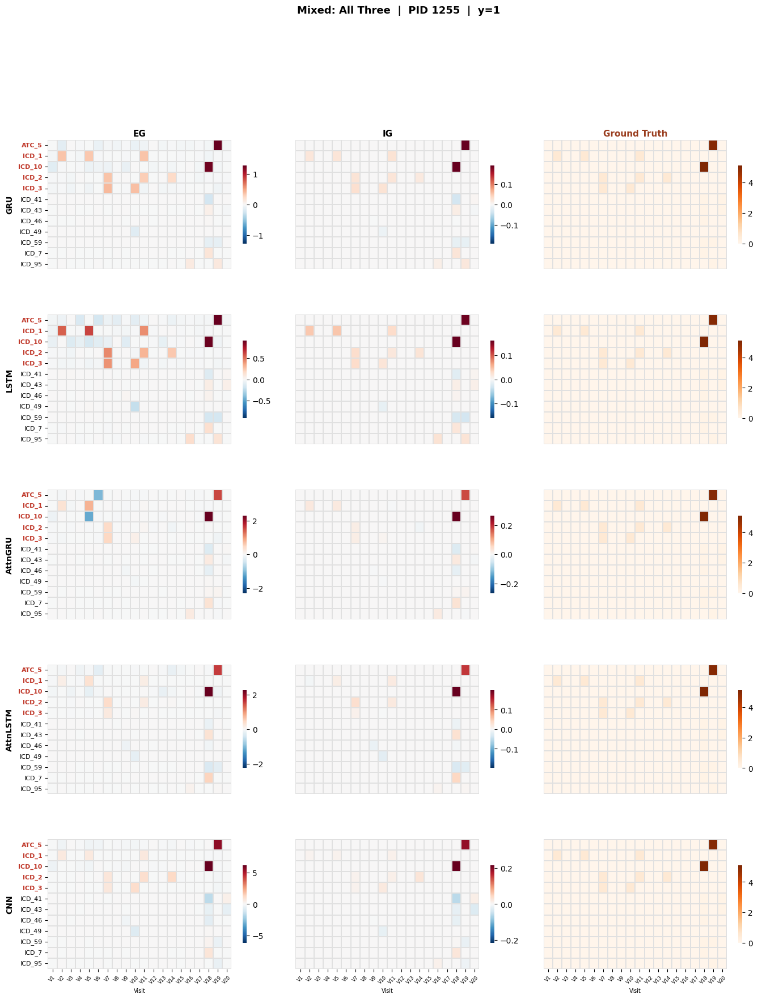

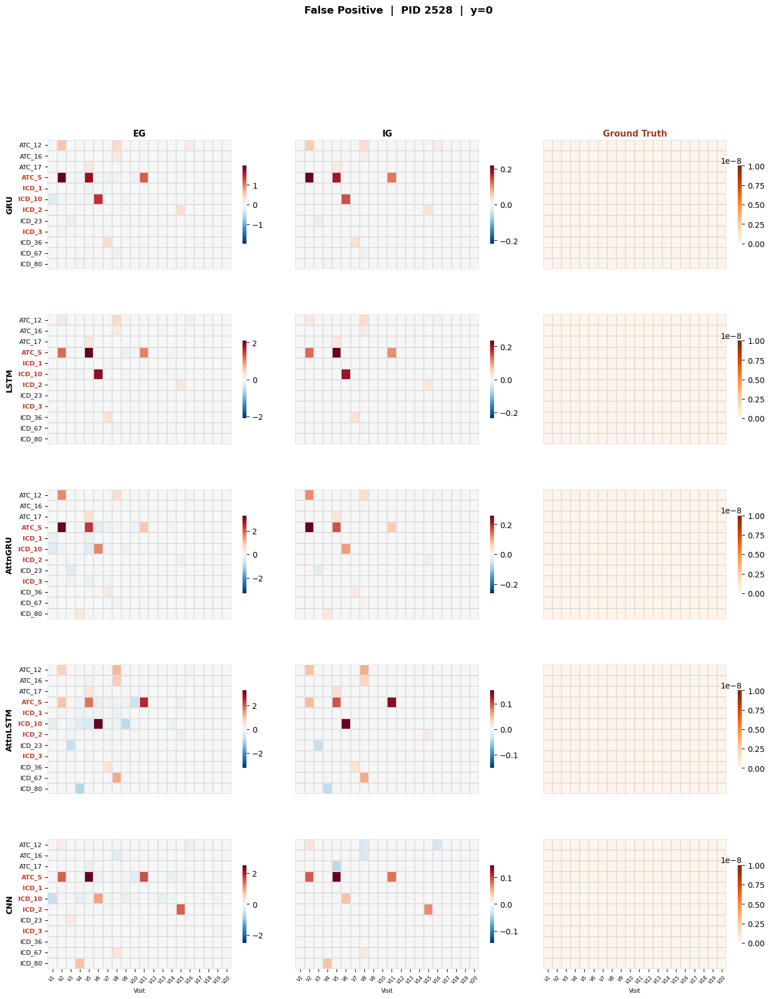

In [21]:
for case_title, p_idx in case_studies.items():
    p_idx     = int(p_idx)
    pid_val   = int(pid_test[p_idx])
    truth_pat = truth_ntf[p_idx]
    eg_pats   = [arr[p_idx, :, :n_tokens] for arr in EG_ARRS]
    ig_pats   = [arr[p_idx, :, :n_tokens] for arr in IG_ARRS]
    combined  = sum(np.abs(a).sum(axis=0) for a in eg_pats + ig_pats)
    top_by    = np.argsort(combined)[-12:][::-1]
    show      = sorted(set(gt_indices) | set(top_by))[:TOP_K]
    show_names = [fnames_seq[i] for i in show]
    N_ROWS = len(MODEL_KEYS); N_COLS = 3
    fig, axes = plt.subplots(N_ROWS, N_COLS, figsize=(5.5 * N_COLS, 3.8 * N_ROWS),
                              gridspec_kw={'wspace': 0.08, 'hspace': 0.35}, squeeze=False)
    fig.suptitle(f'{case_title}  |  PID {pid_val}  |  y={int(y_test[p_idx])}',
                 fontsize=13, fontweight='bold', y=1.005)
    axes[0, 0].set_title('EG', fontsize=11, fontweight='bold', pad=5)
    axes[0, 1].set_title('IG', fontsize=11, fontweight='bold', pad=5)
    axes[0, 2].set_title('Ground Truth', fontsize=11, fontweight='bold', color='#993C1D', pad=5)
    def _hm2(ax, mat, is_gt=False, show_yticks=False, show_xticks=False):
        vmax = mat[:, show].max() + 1e-8 if is_gt else np.abs(mat[:, show]).max() + 1e-8
        sns.heatmap(mat[:, show].T, ax=ax, cmap='Oranges' if is_gt else 'RdBu_r',
                    center=None if is_gt else 0, vmin=0 if is_gt else -vmax, vmax=vmax,
                    xticklabels=visit_labels if show_xticks else [],
                    yticklabels=show_names if show_yticks else [],
                    linewidths=0.3, linecolor='#e0e0e0', cbar_kws={'shrink': 0.6})
        if show_yticks:
            ax.tick_params(axis='y', labelsize=8)
            for fi, f_idx in enumerate(show):
                if fnames_seq[f_idx] in gt_feats:
                    ax.get_yticklabels()[fi].set_color('#c0392b')
                    ax.get_yticklabels()[fi].set_fontweight('bold')
        else: ax.set_yticks([])
        if show_xticks: ax.tick_params(axis='x', rotation=45, labelsize=6); ax.set_xlabel('Visit', fontsize=7)
        else: ax.set_xticklabels([])
    for row, (mlabel, eg, ig) in enumerate(zip(MODEL_LABELS, eg_pats, ig_pats)):
        show_xt = (row == N_ROWS - 1)
        _hm2(axes[row, 0], eg, show_yticks=True,  show_xticks=show_xt)
        _hm2(axes[row, 1], ig, show_yticks=False, show_xticks=show_xt)
        _hm2(axes[row, 2], truth_pat, is_gt=True,  show_yticks=False, show_xticks=show_xt)
        axes[row, 0].set_ylabel(mlabel, fontsize=10, fontweight='bold', labelpad=6)
    gt_x = axes[0, 2].get_position().x0
    safe = case_title.replace(' ', '_').replace(':', '').replace('+', '_')
    plt.savefig(os.path.join(out, f'eg_ig_gt_{safe}.png'), dpi=150, bbox_inches='tight')
    plt.show()

---
## All methods combined  (rows = models)

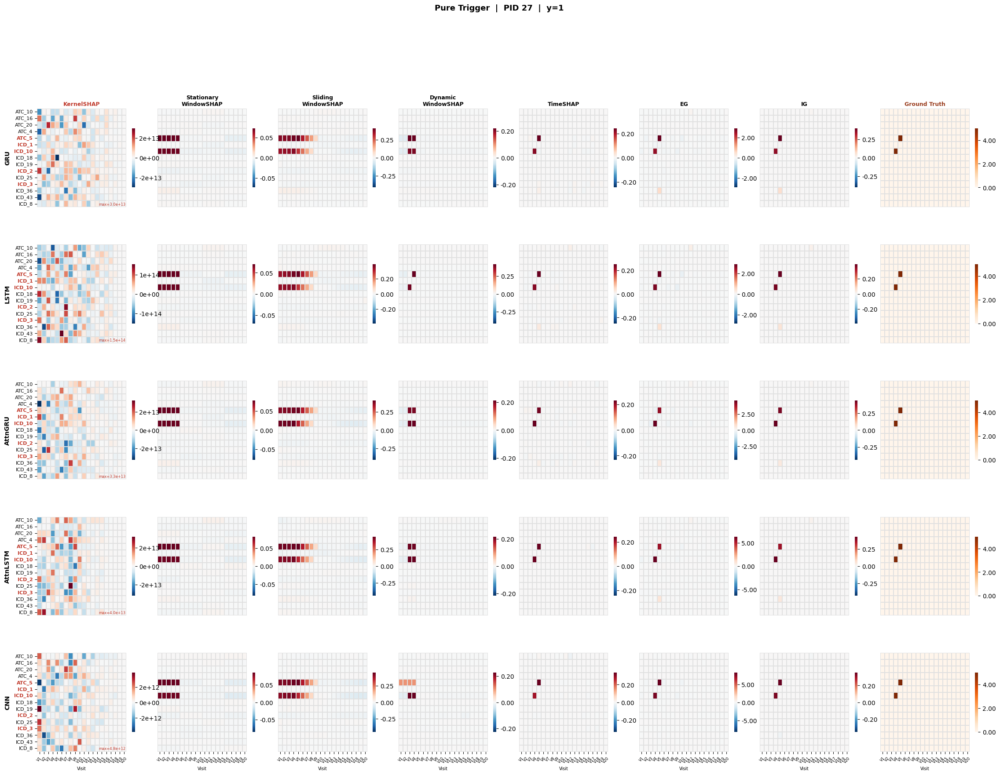

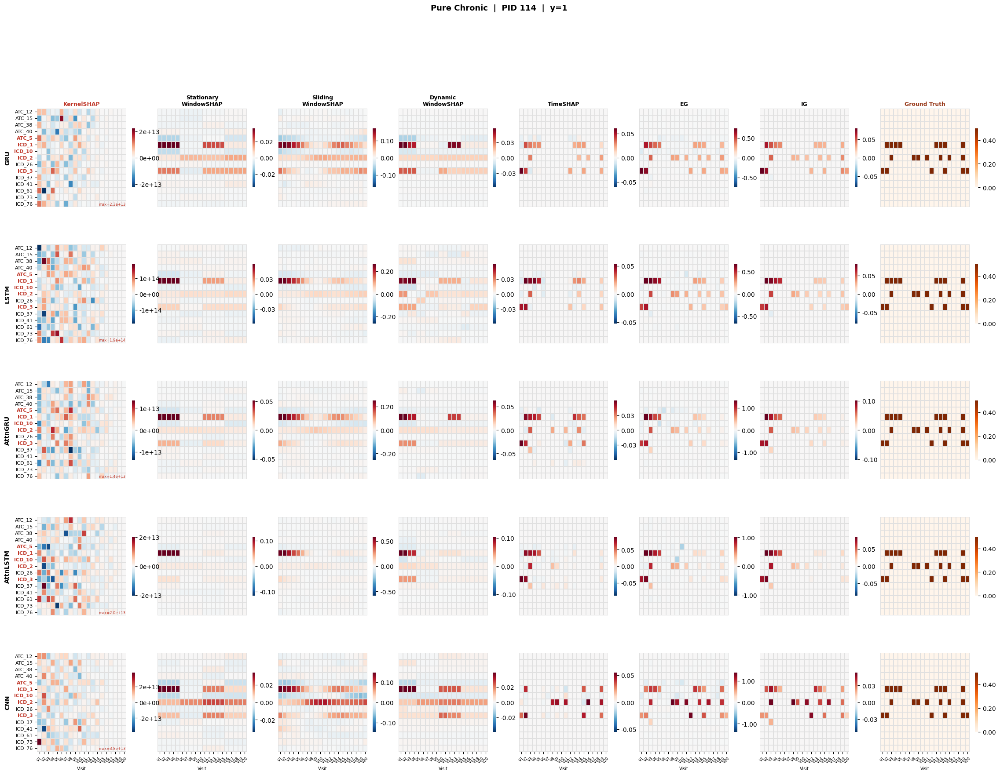

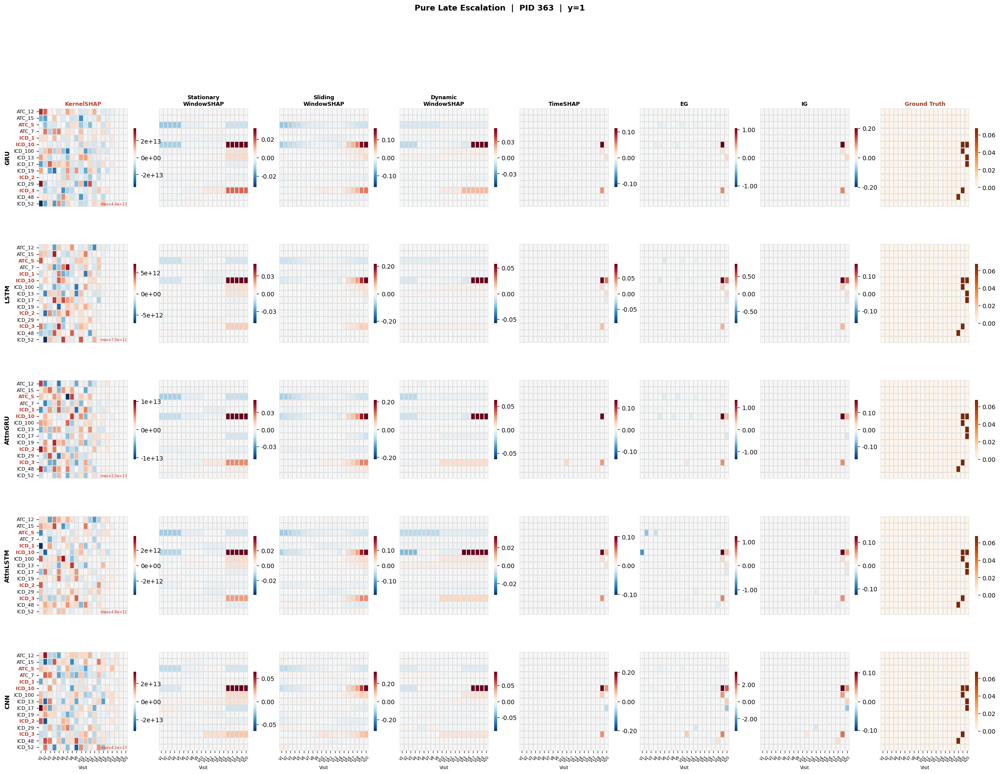

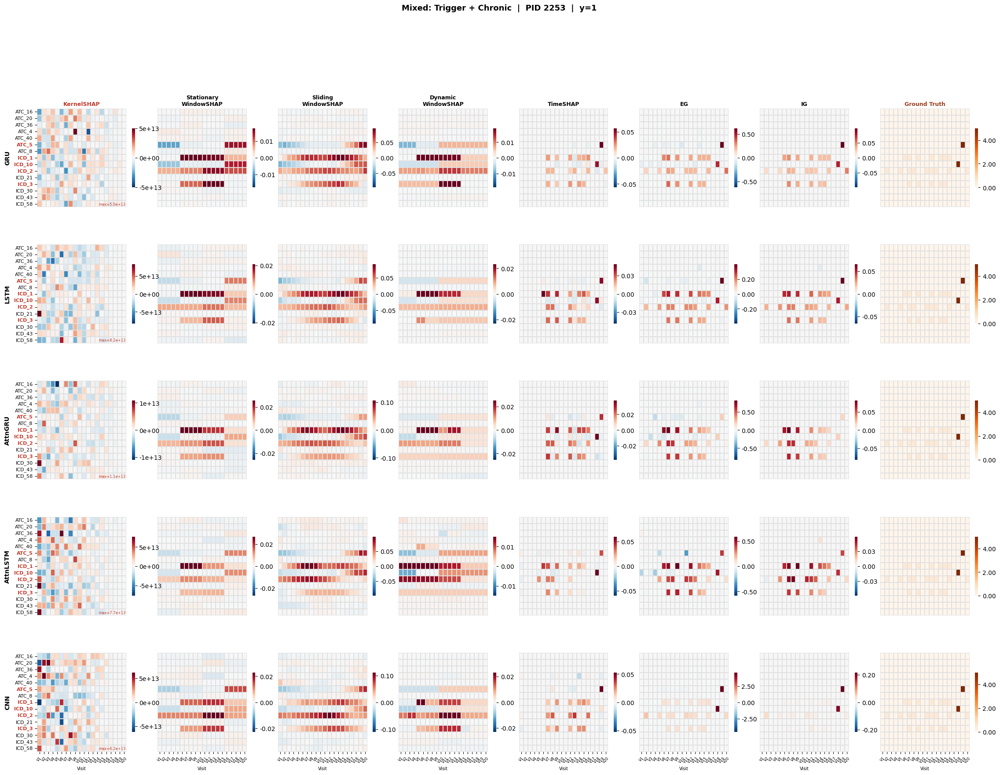

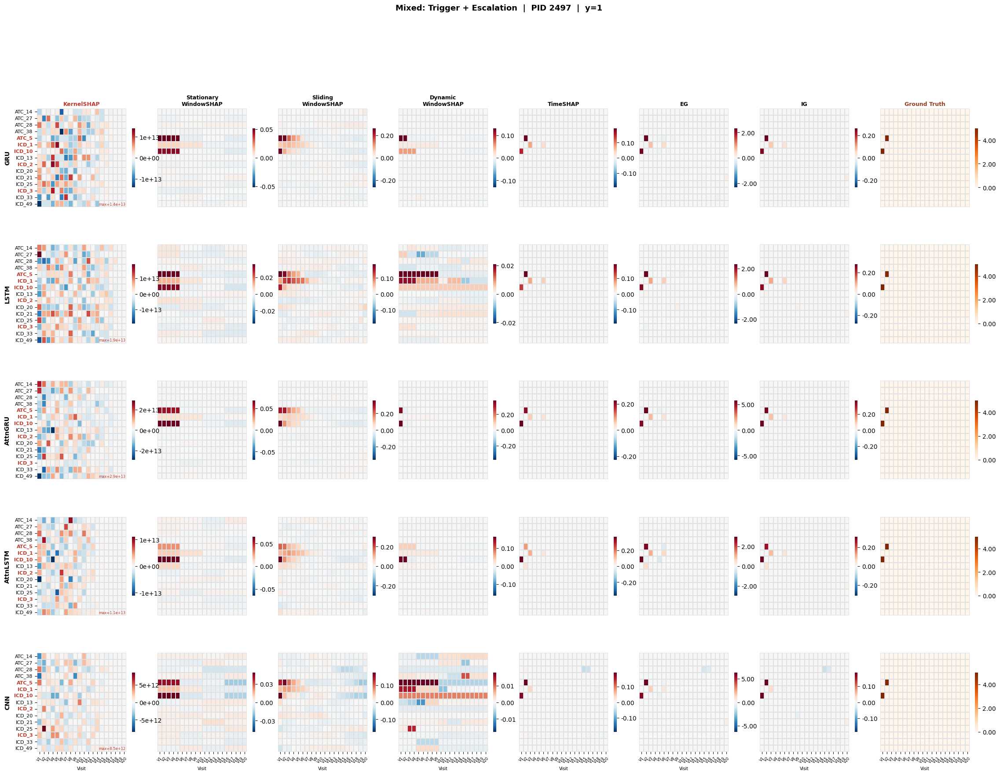

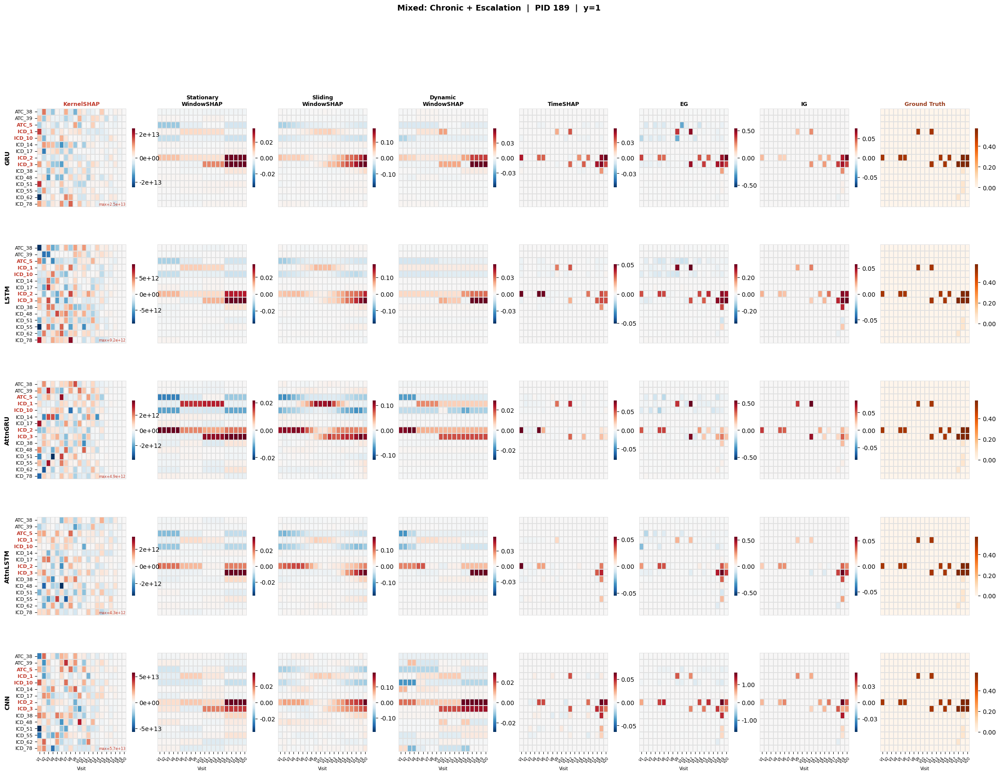

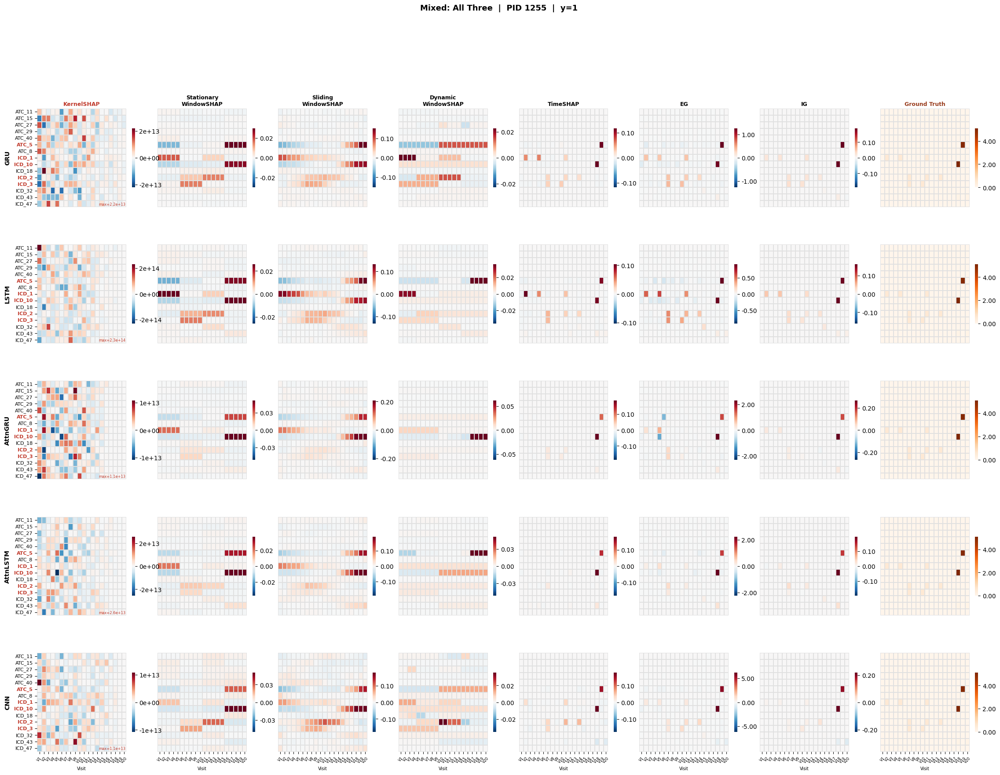

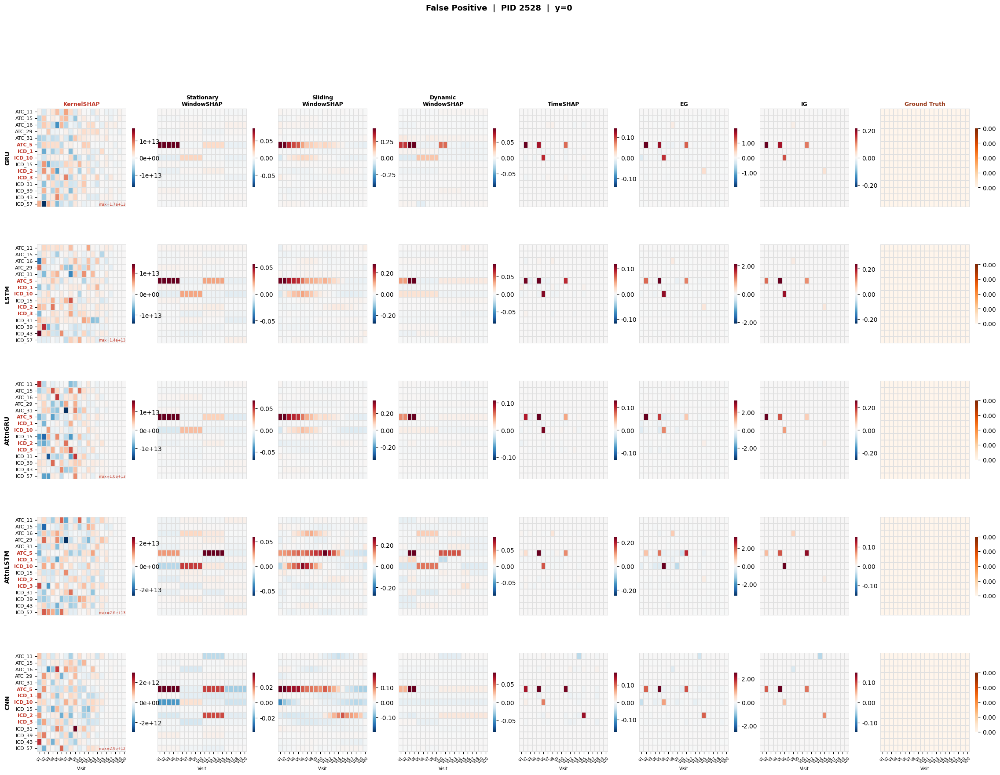

In [22]:
COL_TITLES_ALL = ['KernelSHAP', 'Stationary\nWindowSHAP', 'Sliding\nWindowSHAP',
                  'Dynamic\nWindowSHAP', 'TimeSHAP', 'EG', 'IG', 'Ground Truth']
COL_BROKEN_ALL = [True, False, False, False, False, False, False, False]
COL_GT_ALL     = [False, False, False, False, False, False, False, True]
N_COLS_ALL     = len(COL_TITLES_ALL)

for ci, (case_title, test_idx) in enumerate(zip(case_titles, case_indices)):
    test_idx  = int(test_idx)
    pid_val   = int(pid_test[test_idx])
    truth_pat = truth_ntf[test_idx]
    ws_pos    = tp_pos_map.get(test_idx)
    ks_pats   = [shap_ntf_dict[k][ci, :, :n_tokens] for k in MODEL_KEYS]
    eg_pats   = [arr[test_idx, :, :n_tokens] for arr in EG_ARRS]
    ig_pats   = [arr[test_idx, :, :n_tokens] for arr in IG_ARRS]
    ts_pats   = [timeshap_ntf_dict[k][test_idx, :, :n_tokens]
                 if np.any(timeshap_ntf_dict[k][test_idx, :, :n_tokens] != 0) else None
                 for k in MODEL_KEYS]
    valid = ks_pats + eg_pats + ig_pats + [a for a in ts_pats if a is not None]
    for mkey in MODEL_KEYS:
        for ws_key in ['stat', 'slid', 'dyn']:
            arr = windowshap_ntf_dict.get(mkey, {}).get(ws_key)
            if arr is not None and ws_pos is not None: valid.append(arr[ws_pos, :, :n_tokens])
    # ── shared feature selection: all XAI arrays + always include GT features ──
    combined   = sum(np.abs(a).sum(axis=0) for a in valid) if valid else np.ones(n_tokens)
    top_by     = np.argsort(combined)[-12:][::-1]
    show       = sorted(set(gt_indices) | set(top_by))[:TOP_K]
    show_names = [fnames_seq[i] for i in show]
    gt_vmax    = truth_pat[:, show].max() + 1e-8
    N_ROWS = len(MODEL_KEYS)
    fig, axes = plt.subplots(N_ROWS, N_COLS_ALL, figsize=(3.5 * N_COLS_ALL, 3.8 * N_ROWS),
                              gridspec_kw={'wspace': 0.08, 'hspace': 0.38}, squeeze=False)
    fig.suptitle(f'{case_title}  |  PID {pid_val}  |  y={int(y_test[test_idx])}',
                 fontsize=13, fontweight='bold', y=1.005)
    for col, (ctitle, broken, is_gt_col) in enumerate(zip(COL_TITLES_ALL, COL_BROKEN_ALL, COL_GT_ALL)):
        color = '#c0392b' if broken else ('#993C1D' if is_gt_col else 'black')
        axes[0, col].set_title(ctitle, fontsize=9, fontweight='bold', color=color, pad=5)

    def _hm3(ax, mat, is_gt=False, broken=False, show_yticks=False, show_xticks=False,
             _show=show, _show_names=show_names, _gt_vmax=gt_vmax):
        vmax = _gt_vmax if is_gt else np.abs(mat[:, _show]).max() + 1e-8
        sns.heatmap(mat[:, _show].T, ax=ax, cmap='Oranges' if is_gt else 'RdBu_r',
                    center=None if is_gt else 0, vmin=0 if is_gt else -vmax, vmax=vmax,
                    xticklabels=visit_labels if show_xticks else [],
                    yticklabels=_show_names if show_yticks else [],
                    linewidths=0.3, linecolor='#e0e0e0',
                    cbar_kws={'shrink': 0.6, 'format': '%.0e' if broken else '%.2f'})
        if broken:
            ax.set_facecolor('#fff5f5')
            ax.text(0.99, 0.01, f'max={vmax:.1e}', ha='right', va='bottom',
                    fontsize=6, color='#c0392b', transform=ax.transAxes)
        if show_yticks:
            ax.tick_params(axis='y', labelsize=8)
            for fi, f_idx in enumerate(_show):
                if fnames_seq[f_idx] in gt_feats:
                    ax.get_yticklabels()[fi].set_color('#c0392b')
                    ax.get_yticklabels()[fi].set_fontweight('bold')
        else: ax.set_yticks([])
        if show_xticks: ax.tick_params(axis='x', rotation=45, labelsize=6); ax.set_xlabel('Visit', fontsize=7)
        else: ax.set_xticklabels([])

    def _ph3(ax, show_xticks=False):
        ax.text(0.5, 0.5, 'no data', ha='center', va='center',
                color='#aaaaaa', fontsize=9, style='italic', transform=ax.transAxes)
        ax.set_facecolor('#f5f5f5'); ax.set_xticks([]); ax.set_yticks([])
        if show_xticks: ax.set_xlabel('Visit', fontsize=7)

    for row, (mlabel, mkey, ks, eg, ig, ts) in enumerate(
            zip(MODEL_LABELS, MODEL_KEYS, ks_pats, eg_pats, ig_pats, ts_pats)):
        show_xt = (row == N_ROWS - 1)
        ws_d    = windowshap_ntf_dict.get(mkey, {})
        _hm3(axes[row, 0], ks, broken=True, show_yticks=True, show_xticks=show_xt)
        axes[row, 0].set_ylabel(mlabel, fontsize=10, fontweight='bold', labelpad=6)
        for col, ws_key in enumerate(['stat', 'slid', 'dyn'], start=1):
            arr = ws_d.get(ws_key)
            if arr is not None and ws_pos is not None: _hm3(axes[row, col], arr[ws_pos, :, :n_tokens], show_yticks=False, show_xticks=show_xt)
            else: _ph3(axes[row, col], show_xticks=show_xt)
        if ts is not None: _hm3(axes[row, 4], ts, show_yticks=False, show_xticks=show_xt)
        else: _ph3(axes[row, 4], show_xticks=show_xt)
        _hm3(axes[row, 5], eg, show_yticks=False, show_xticks=show_xt)
        _hm3(axes[row, 6], ig, show_yticks=False, show_xticks=show_xt)
        _hm3(axes[row, 7], truth_pat, is_gt=True, show_yticks=False, show_xticks=show_xt)
    gt_x = axes[0, N_COLS_ALL - 1].get_position().x0
    safe = case_title.replace(' ', '_').replace(':', '').replace('+', '_')
    plt.savefig(os.path.join(out, f'all_methods_{safe}.png'), dpi=150, bbox_inches='tight')
    plt.show()


## WindowSHAP, TimeSHAP, IG, EG and Ground Truth Heatmaps

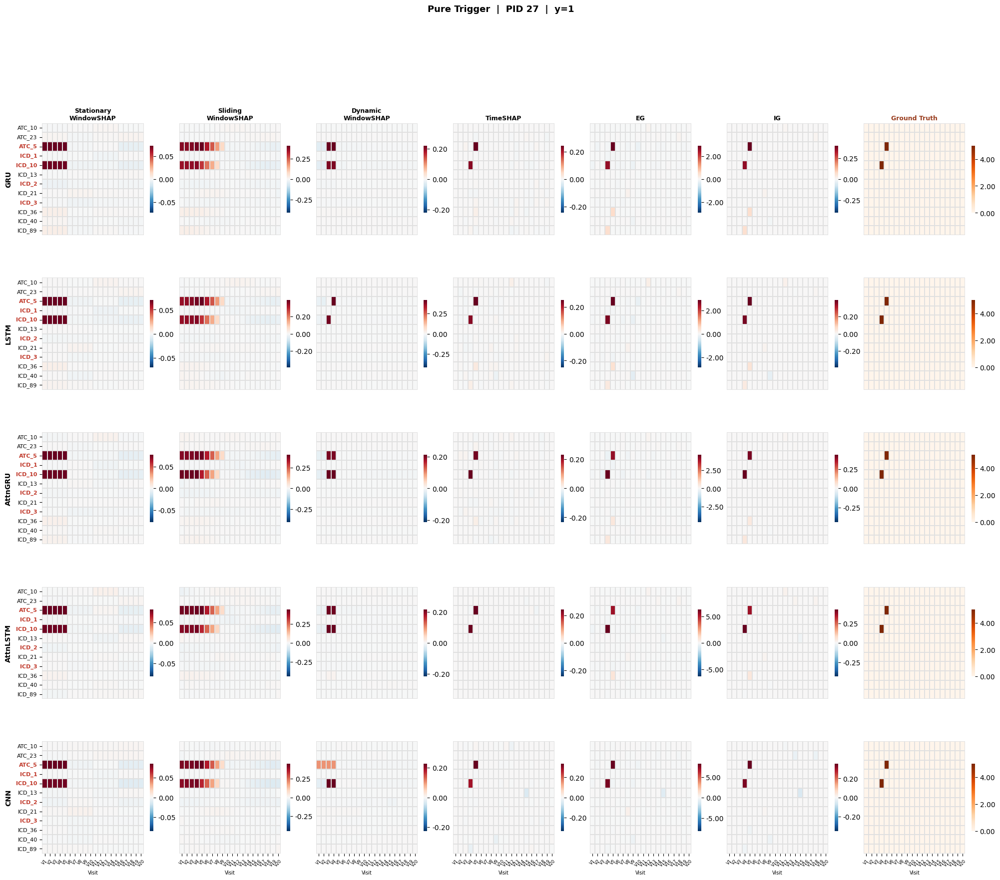

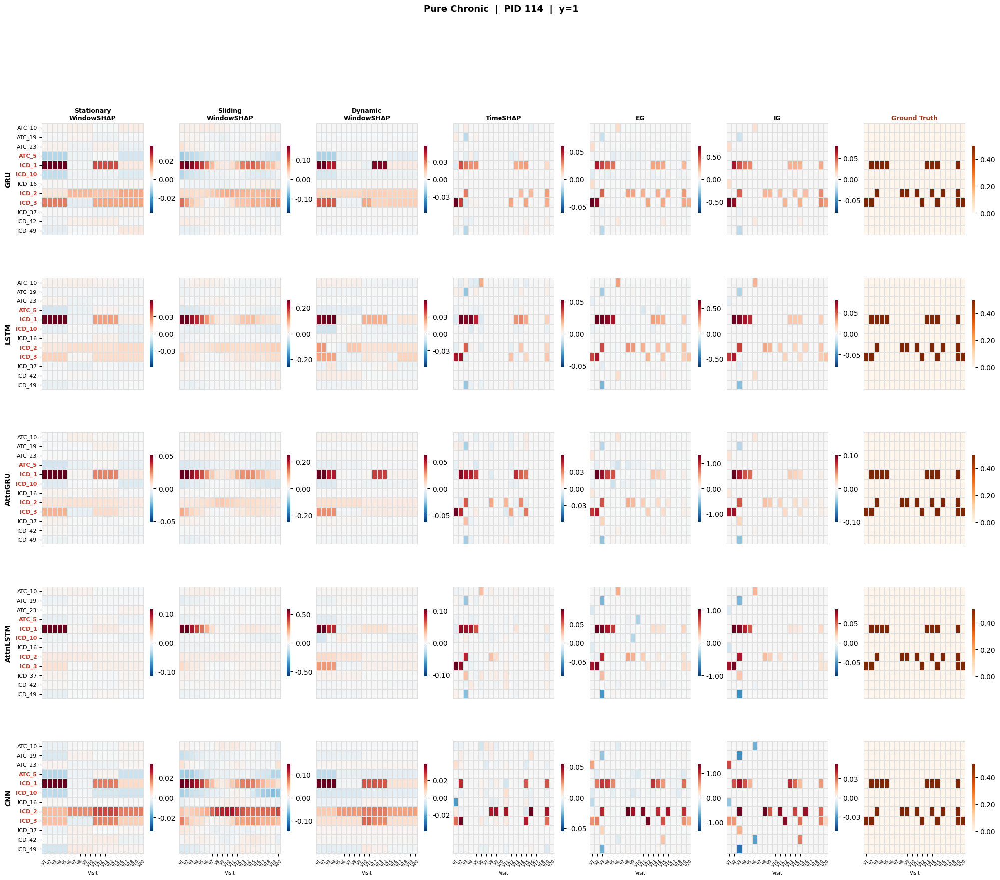

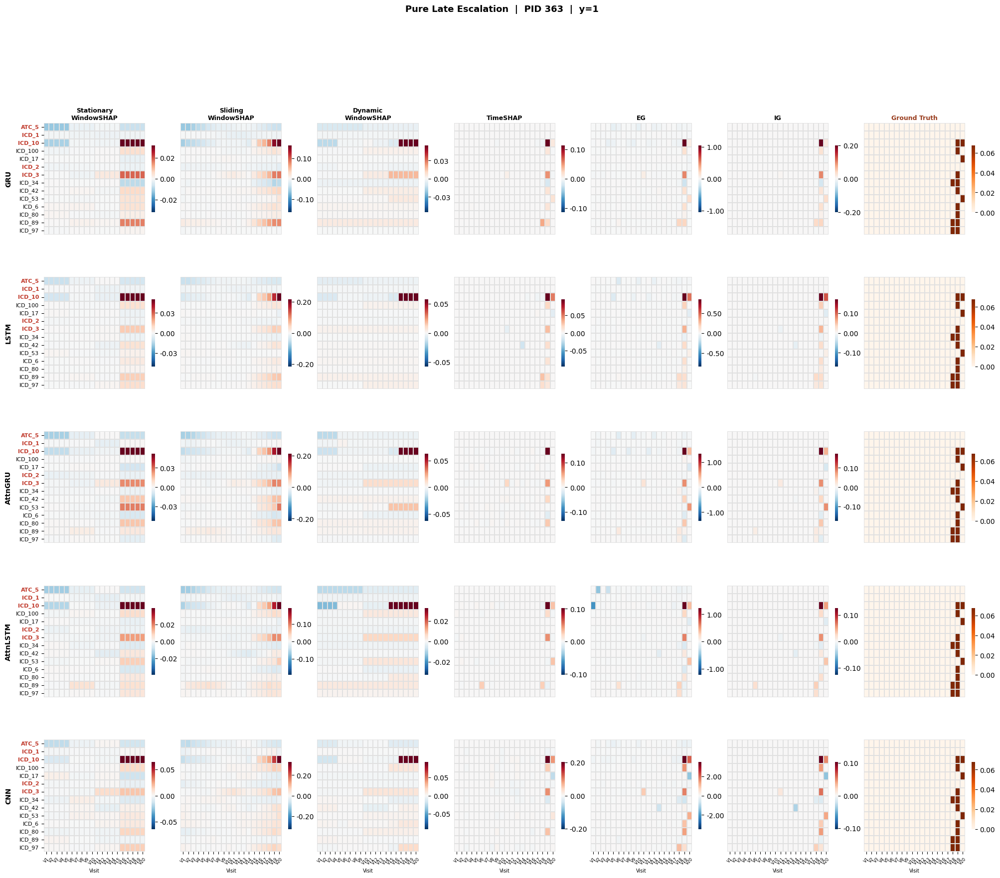

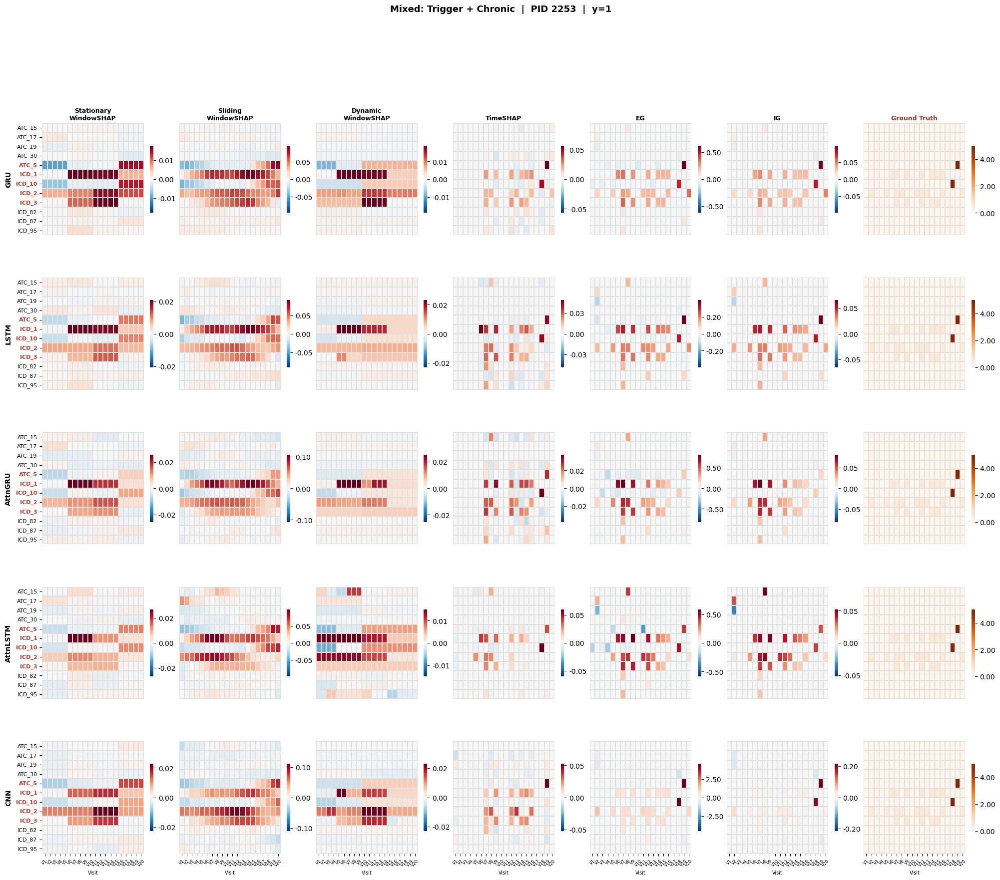

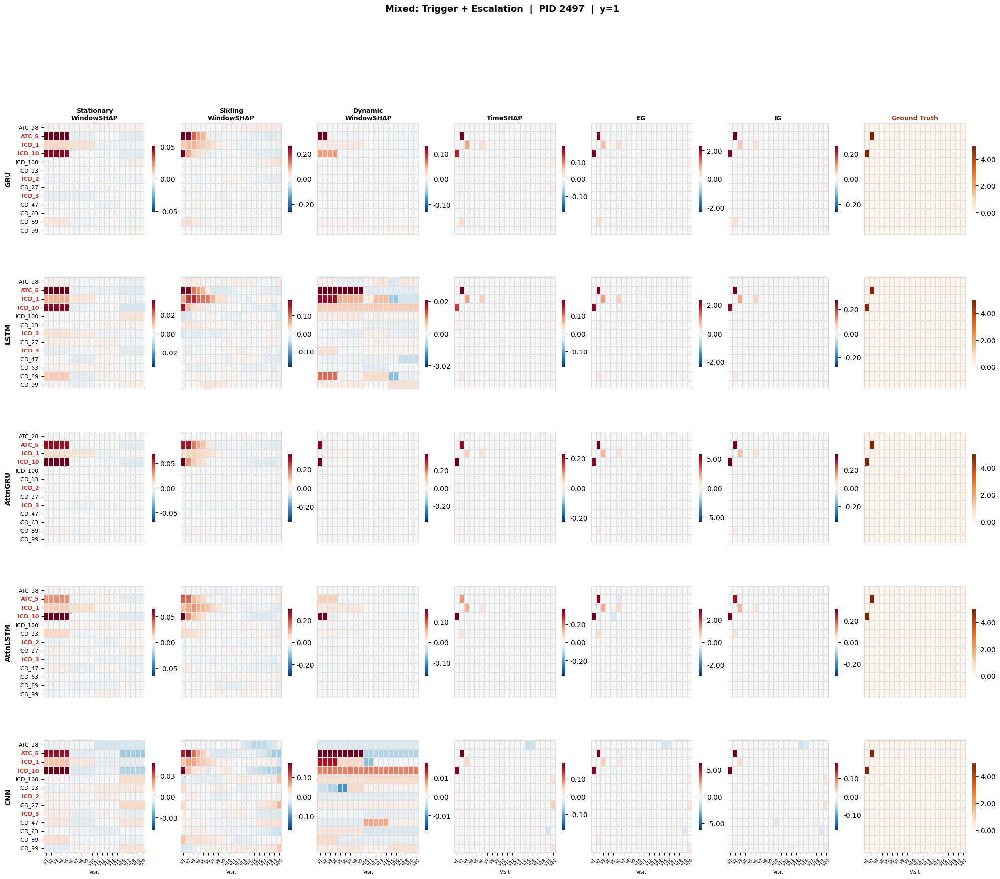

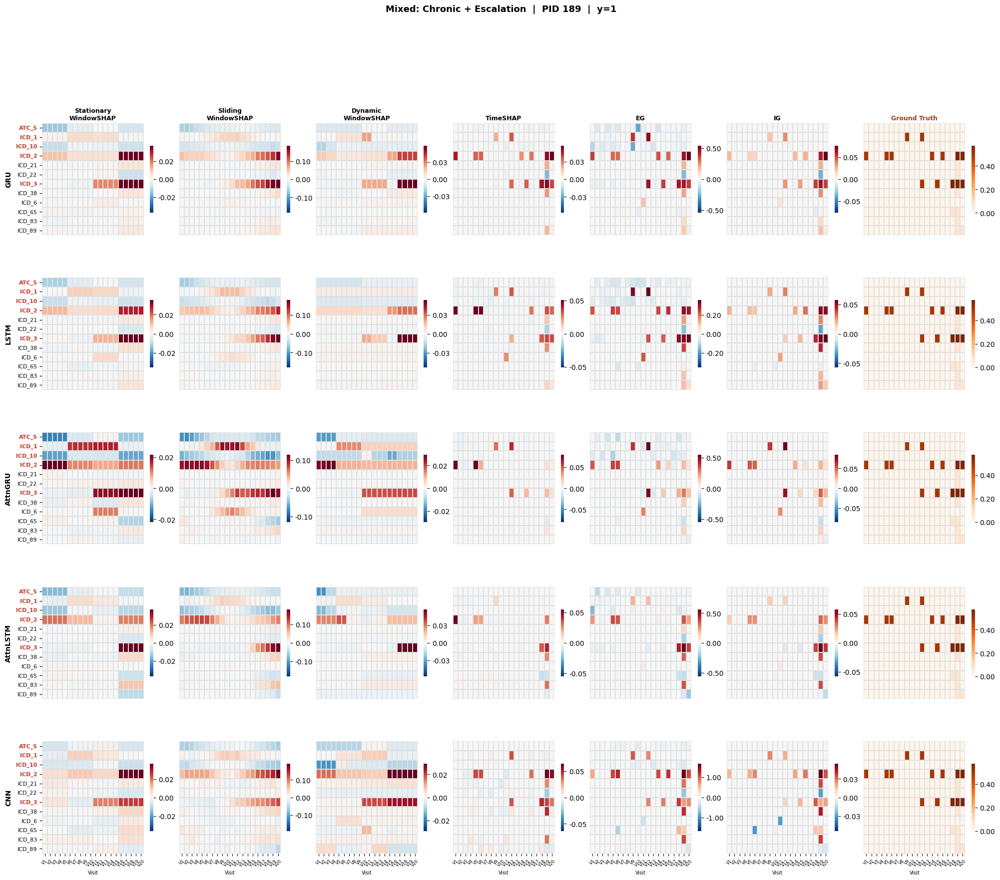

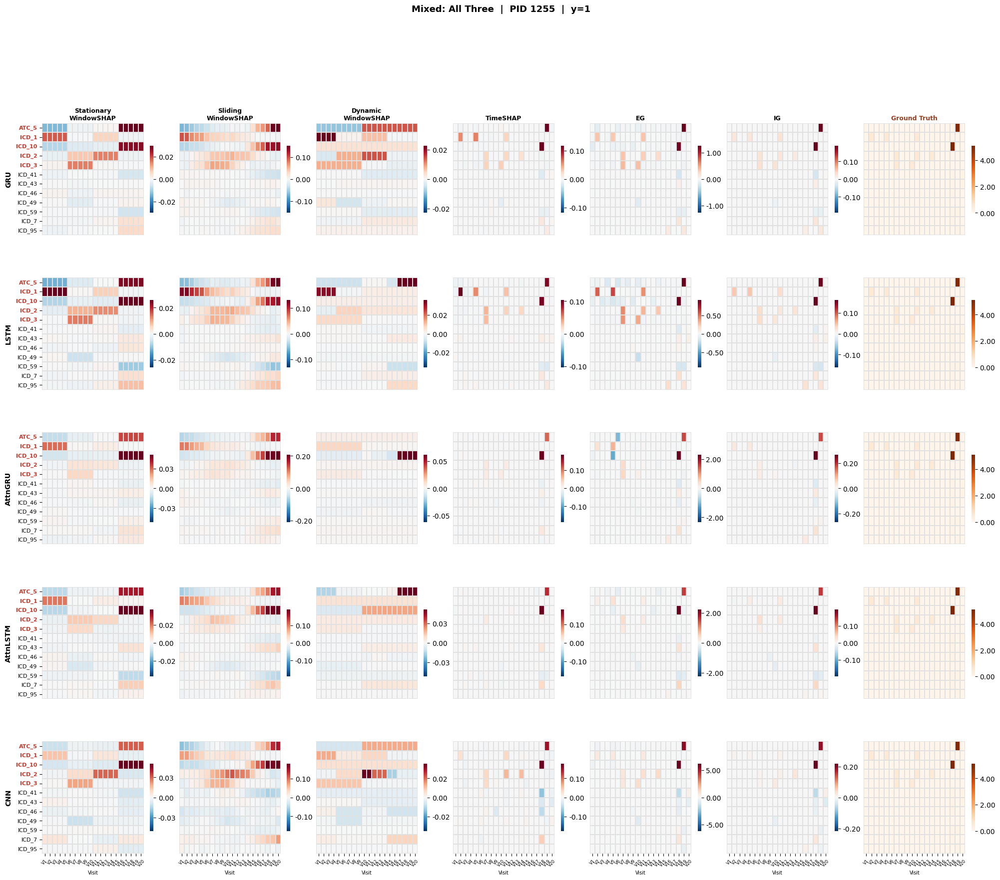

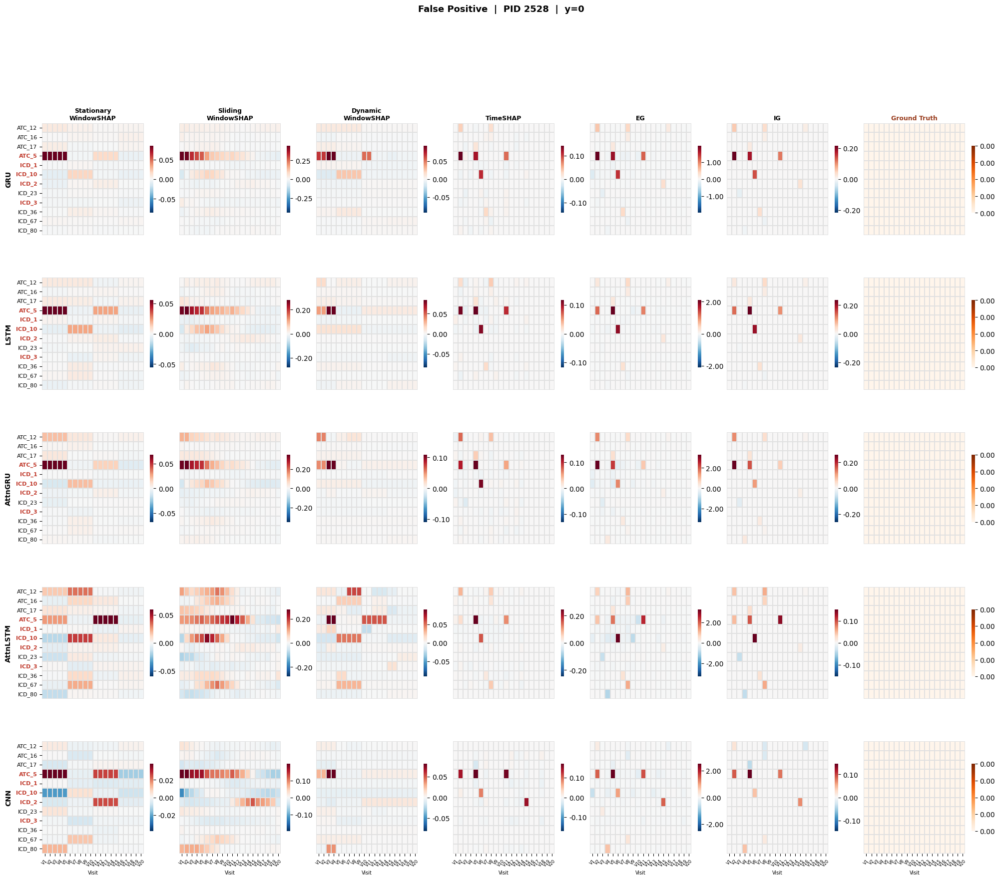

In [23]:
COL_TITLES_ALL = ['Stationary\nWindowSHAP', 'Sliding\nWindowSHAP',
                  'Dynamic\nWindowSHAP', 'TimeSHAP', 'EG', 'IG', 'Ground Truth']
COL_GT_ALL     = [False, False, False, False, False, False, True]
N_COLS_ALL     = len(COL_TITLES_ALL)

for ci, (case_title, test_idx) in enumerate(zip(case_titles, case_indices)):
    test_idx  = int(test_idx)
    pid_val   = int(pid_test[test_idx])
    truth_pat = truth_ntf[test_idx]
    ws_pos    = tp_pos_map.get(test_idx)
    ks_pats   = [shap_ntf_dict[k][ci, :, :n_tokens] for k in MODEL_KEYS]
    eg_pats   = [arr[test_idx, :, :n_tokens] for arr in EG_ARRS]
    ig_pats   = [arr[test_idx, :, :n_tokens] for arr in IG_ARRS]
    ts_pats   = [timeshap_ntf_dict[k][test_idx, :, :n_tokens]
                 if np.any(timeshap_ntf_dict[k][test_idx, :, :n_tokens] != 0) else None
                 for k in MODEL_KEYS]
    valid = eg_pats + ig_pats + [a for a in ts_pats if a is not None]
    for mkey in MODEL_KEYS:
        for ws_key in ['stat', 'slid', 'dyn']:
            arr = windowshap_ntf_dict.get(mkey, {}).get(ws_key)
            if arr is not None and ws_pos is not None: valid.append(arr[ws_pos, :, :n_tokens])
    combined   = sum(np.abs(a).sum(axis=0) for a in valid) if valid else np.ones(n_tokens)
    top_by     = np.argsort(combined)[-12:][::-1]
    show       = sorted(set(gt_indices) | set(top_by))[:TOP_K]
    show_names = [fnames_seq[i] for i in show]
    gt_vmax    = truth_pat[:, show].max() + 1e-8
    N_ROWS = len(MODEL_KEYS)
    fig, axes = plt.subplots(N_ROWS, N_COLS_ALL, figsize=(3.5 * N_COLS_ALL, 3.8 * N_ROWS),
                              gridspec_kw={'wspace': 0.08, 'hspace': 0.38}, squeeze=False)
    fig.suptitle(f'{case_title}  |  PID {pid_val}  |  y={int(y_test[test_idx])}',
                 fontsize=13, fontweight='bold', y=1.005)
    for col, (ctitle, is_gt_col) in enumerate(zip(COL_TITLES_ALL, COL_GT_ALL)):
        axes[0, col].set_title(ctitle, fontsize=9, fontweight='bold',
                                color='#993C1D' if is_gt_col else 'black', pad=5)

    def _hm3(ax, mat, is_gt=False, show_yticks=False, show_xticks=False,
             _show=show, _show_names=show_names, _gt_vmax=gt_vmax):
        vmax = _gt_vmax if is_gt else np.abs(mat[:, _show]).max() + 1e-8
        sns.heatmap(mat[:, _show].T, ax=ax, cmap='Oranges' if is_gt else 'RdBu_r',
                    center=None if is_gt else 0, vmin=0 if is_gt else -vmax, vmax=vmax,
                    xticklabels=visit_labels if show_xticks else [],
                    yticklabels=_show_names if show_yticks else [],
                    linewidths=0.3, linecolor='#e0e0e0',
                    cbar_kws={'shrink': 0.6, 'format': '%.2f'})
        if show_yticks:
            ax.tick_params(axis='y', labelsize=8)
            for fi, f_idx in enumerate(_show):
                if fnames_seq[f_idx] in gt_feats:
                    ax.get_yticklabels()[fi].set_color('#c0392b')
                    ax.get_yticklabels()[fi].set_fontweight('bold')
        else: ax.set_yticks([])
        if show_xticks: ax.tick_params(axis='x', rotation=45, labelsize=6); ax.set_xlabel('Visit', fontsize=7)
        else: ax.set_xticklabels([])

    def _ph3(ax, show_xticks=False):
        ax.text(0.5, 0.5, 'no data', ha='center', va='center',
                color='#aaaaaa', fontsize=9, style='italic', transform=ax.transAxes)
        ax.set_facecolor('#f5f5f5'); ax.set_xticks([]); ax.set_yticks([])
        if show_xticks: ax.set_xlabel('Visit', fontsize=7)

    for row, (mlabel, mkey, eg, ig, ts) in enumerate(
            zip(MODEL_LABELS, MODEL_KEYS, eg_pats, ig_pats, ts_pats)):
        show_xt = (row == N_ROWS - 1)
        ws_d    = windowshap_ntf_dict.get(mkey, {})
        for col, ws_key in enumerate(['stat', 'slid', 'dyn']):
            arr = ws_d.get(ws_key)
            if arr is not None and ws_pos is not None:
                _hm3(axes[row, col], arr[ws_pos, :, :n_tokens], show_yticks=(col == 0), show_xticks=show_xt)
            else:
                _ph3(axes[row, col], show_xticks=show_xt)
        axes[row, 0].set_ylabel(mlabel, fontsize=10, fontweight='bold', labelpad=6)
        if ts is not None: _hm3(axes[row, 3], ts, show_yticks=False, show_xticks=show_xt)
        else: _ph3(axes[row, 3], show_xticks=show_xt)
        _hm3(axes[row, 4], eg, show_yticks=False, show_xticks=show_xt)
        _hm3(axes[row, 5], ig, show_yticks=False, show_xticks=show_xt)
        _hm3(axes[row, 6], truth_pat, is_gt=True, show_yticks=False, show_xticks=show_xt)

    gt_x = axes[0, N_COLS_ALL - 1].get_position().x0
    safe = case_title.replace(' ', '_').replace(':', '').replace('+', '_')
    plt.savefig(os.path.join(out, f'all_methods_{safe}.png'), dpi=150, bbox_inches='tight')
    plt.show()

## Attention vs XAI: Attention-weighted feature importance

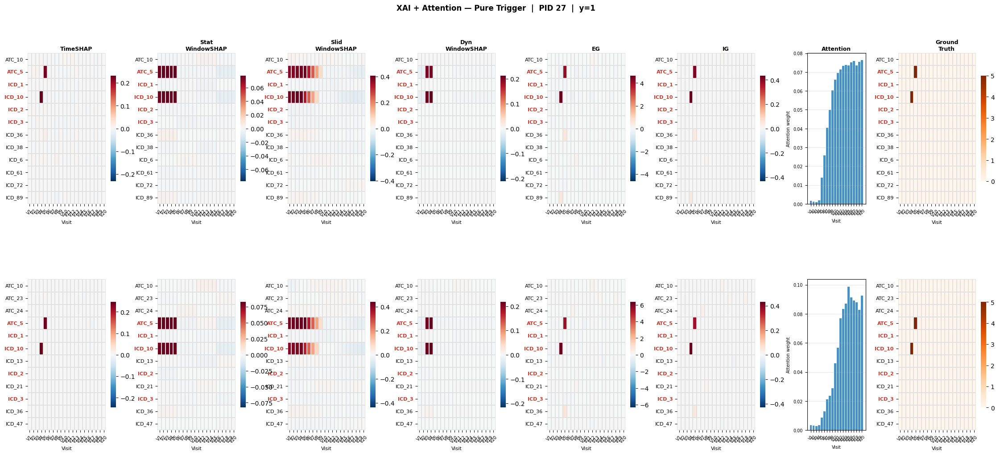

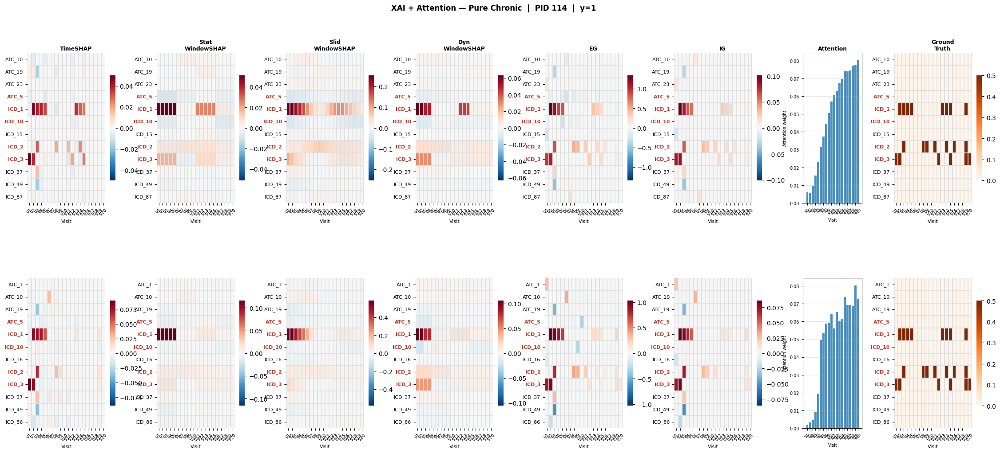

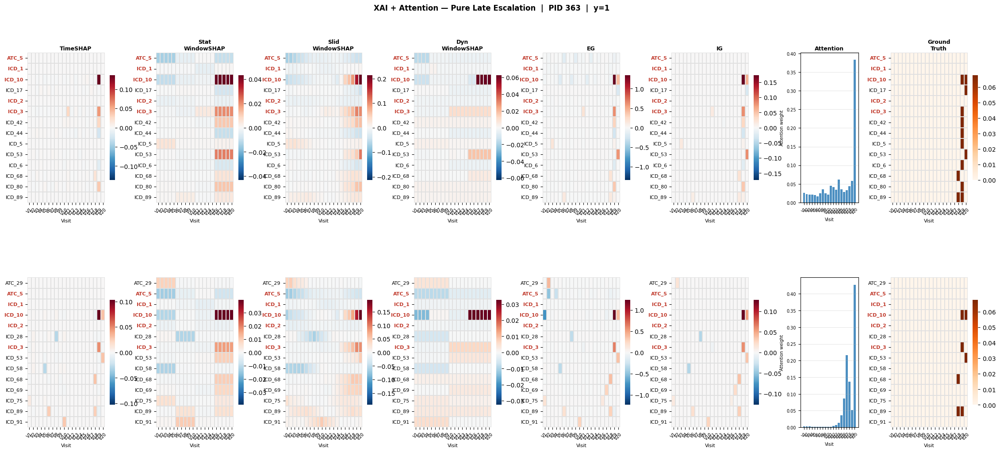

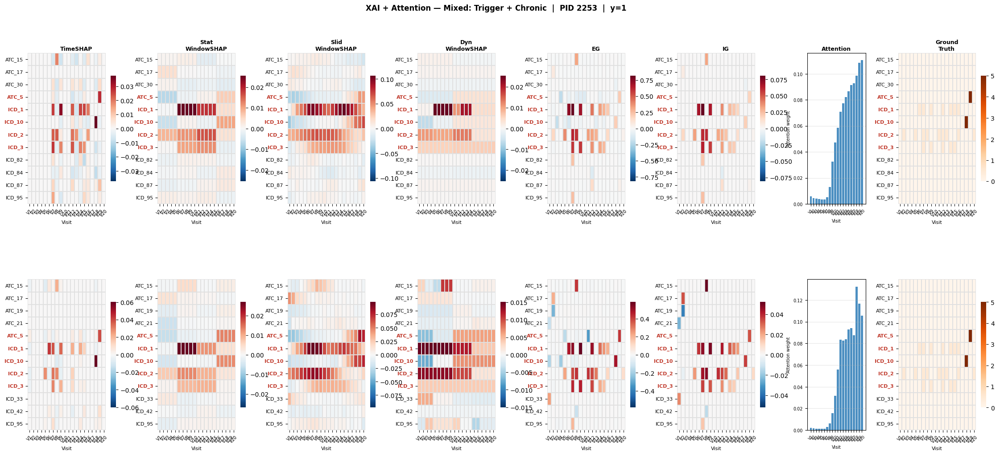

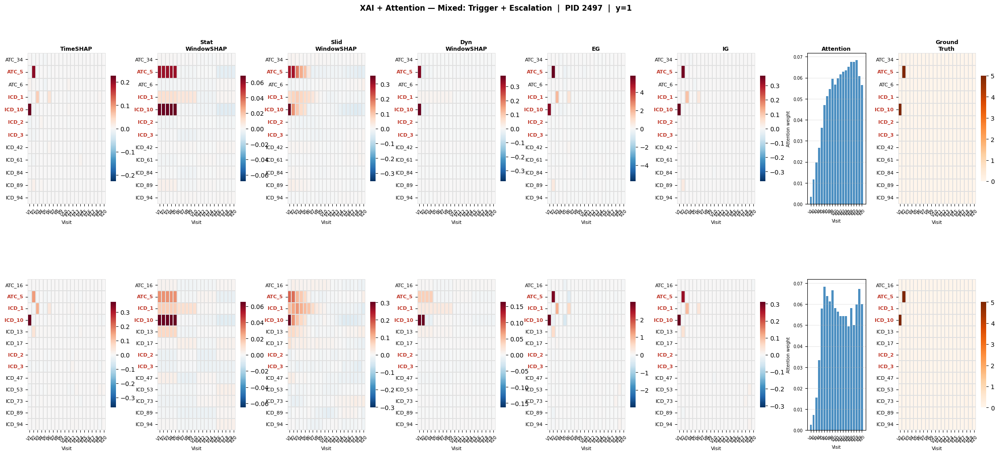

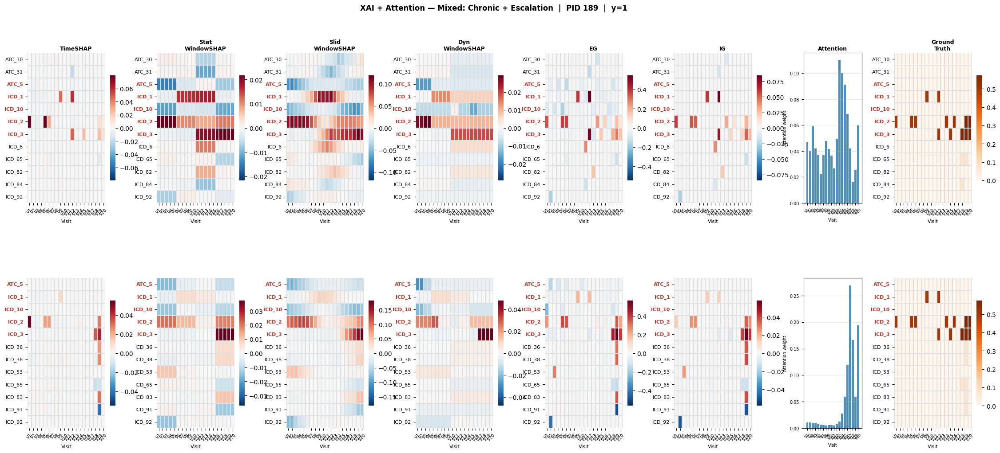

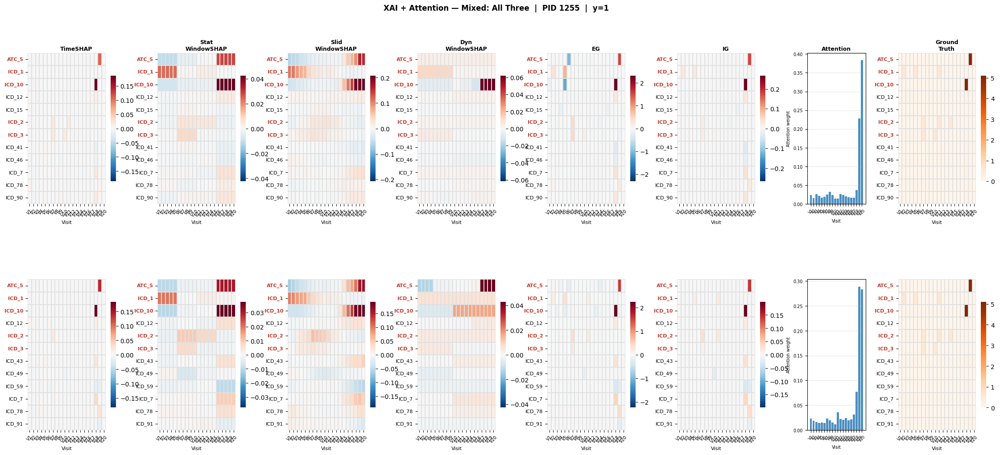

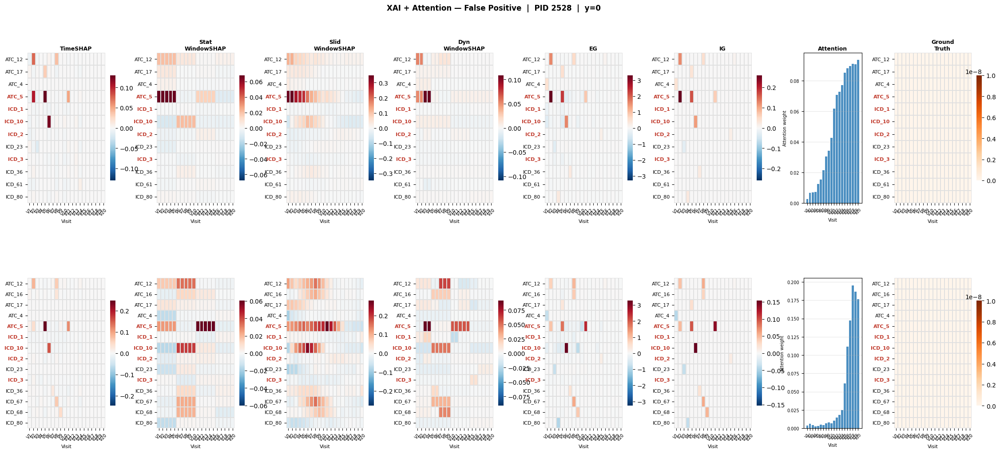

In [24]:
import matplotlib.gridspec as gridspec

TOP_K_H = 15

def _hm_h(ax, mat, top_idx, top_names, title, cmap='RdBu_r', center=0,
           vmin=None, vmax=None, show_xticks=False, truth_pat=None, gt_feats=None):
    if vmax is None:
        vmax = np.abs(mat[:, top_idx]).max() + 1e-8
    if vmin is None:
        vmin = 0 if cmap == 'Oranges' else -vmax
    sns.heatmap(mat[:, top_idx].T, ax=ax, cmap=cmap,
                center=center if cmap != 'Oranges' else None,
                vmin=vmin, vmax=vmax,
                xticklabels=visit_labels if show_xticks else [],
                yticklabels=top_names,
                linewidths=0.3, linecolor='#e0e0e0',
                cbar_kws={'shrink': 0.7})
    ax.set_title(title, fontsize=10, fontweight='bold',
                 color='#993C1D' if cmap == 'Oranges' else 'black')
    ax.tick_params(axis='y', labelsize=8)
    if show_xticks:
        ax.tick_params(axis='x', rotation=45, labelsize=7)
        ax.set_xlabel('Visit', fontsize=8)
    else:
        ax.set_xticklabels([])
    if gt_feats is not None:
        for fi, fname in enumerate(top_names):
            if fname in gt_feats:
                ax.get_yticklabels()[fi].set_color('#c0392b')
                ax.get_yticklabels()[fi].set_fontweight('bold')

ATTN_MODELS_4 = [
    ('AttnGRU',  model_attn_gru,  eg_attn_gru_ntf,  ig_attn_gru_ntf,  'attn_gru'),
    ('AttnLSTM', model_attn_lstm, eg_attn_lstm_ntf, ig_attn_lstm_ntf, 'attn_lstm'),
]

# Columns: TimeSHAP | Stat WS | Slid WS | Dyn WS | EG | IG | Attention | GT
COL_TITLES  = ['TimeSHAP', 'Stat\nWindowSHAP', 'Slid\nWindowSHAP', 'Dyn\nWindowSHAP',
               'EG', 'IG', 'Attention', 'Ground\nTruth']
WIDTH_RATIOS = [3, 3, 3, 3, 3, 3, 1.8, 3]

for case_title, p_idx in case_studies.items():
    p_idx     = int(p_idx)
    pid_val   = int(pid_test[p_idx])
    truth_pat = truth_ntf[p_idx] if truth_ntf is not None else None
    ws_pos    = tp_pos_map.get(p_idx)
    gt_vmax   = truth_pat[:, :n_tokens].max() + 1e-8 if truth_pat is not None else 1.0

    fig = plt.figure(figsize=(len(WIDTH_RATIOS) * 3.5, 5.5 * len(ATTN_MODELS_4)))
    fig.suptitle(
        f'XAI + Attention — {case_title}  |  PID {pid_val}  |  y={int(y_test[p_idx])}',
        fontsize=12, fontweight='bold')
    gs = gridspec.GridSpec(len(ATTN_MODELS_4), len(WIDTH_RATIOS), figure=fig,
                           width_ratios=WIDTH_RATIOS, wspace=0.35, hspace=0.5)

    for col, title in enumerate(COL_TITLES):
        ax = fig.add_subplot(gs[0, col])
        ax.set_title(title, fontsize=9, fontweight='bold', pad=4)
        ax.axis('off')

    for row, (mname, attn_model, eg_arr, ig_arr, mkey) in enumerate(ATTN_MODELS_4):
        attn_w = attn_model.get_attention_weights(
            X_test_tensor[p_idx:p_idx+1],
            X_static_t[p_idx:p_idx+1] if X_static_t is not None else None)[0]
        eg_pat = eg_arr[p_idx, :, :n_tokens]
        ig_pat = ig_arr[p_idx, :, :n_tokens]
        ts_pat = timeshap_ntf_dict[mkey][p_idx, :, :n_tokens] \
                 if np.any(timeshap_ntf_dict[mkey][p_idx, :, :n_tokens] != 0) else None

        # Shared feature ranking
        arrays_for_ranking = [eg_pat, ig_pat]
        if ts_pat is not None: arrays_for_ranking.append(ts_pat)
        for ws_key in ['stat', 'slid', 'dyn']:
            arr = windowshap_ntf_dict.get(mkey, {}).get(ws_key)
            if arr is not None and ws_pos is not None:
                arrays_for_ranking.append(arr[ws_pos, :, :n_tokens])
        combined  = sum(np.abs(a).sum(axis=0) for a in arrays_for_ranking)
        top_by    = np.argsort(combined)[-12:][::-1]
        show      = sorted(set(gt_indices) | set(top_by))[:TOP_K_H]
        top_names = [fnames_seq[j] for j in show]
        top_idx   = np.array(show)

        kw = dict(top_idx=top_idx, top_names=top_names, show_xticks=True,
                  truth_pat=truth_pat, gt_feats=gt_feats)

        ax_ts  = fig.add_subplot(gs[row, 0])
        ax_st  = fig.add_subplot(gs[row, 1])
        ax_sl  = fig.add_subplot(gs[row, 2])
        ax_dy  = fig.add_subplot(gs[row, 3])
        ax_eg  = fig.add_subplot(gs[row, 4])
        ax_ig  = fig.add_subplot(gs[row, 5])
        ax_bar = fig.add_subplot(gs[row, 6])
        ax_gt  = fig.add_subplot(gs[row, 7])

        ax_ts.set_ylabel(mname, fontsize=11, fontweight='bold', labelpad=6)

        if ts_pat is not None:
            _hm_h(ax_ts, ts_pat, **kw, title='')
        else:
            ax_ts.text(0.5, 0.5, 'no data', ha='center', va='center',
                       color='#aaaaaa', fontsize=9, style='italic', transform=ax_ts.transAxes)
            ax_ts.set_facecolor('#f5f5f5'); ax_ts.set_xticks([]); ax_ts.set_yticks([])

        for ax_ws, ws_key in zip([ax_st, ax_sl, ax_dy], ['stat', 'slid', 'dyn']):
            arr = windowshap_ntf_dict.get(mkey, {}).get(ws_key)
            if arr is not None and ws_pos is not None:
                _hm_h(ax_ws, arr[ws_pos, :, :n_tokens], **kw, title='')
            else:
                ax_ws.text(0.5, 0.5, 'no data', ha='center', va='center',
                           color='#aaaaaa', fontsize=9, style='italic', transform=ax_ws.transAxes)
                ax_ws.set_facecolor('#f5f5f5'); ax_ws.set_xticks([]); ax_ws.set_yticks([])

        _hm_h(ax_eg, eg_pat, **kw, title='')
        _hm_h(ax_ig, ig_pat, **kw, title='')

        # Attention bar
        ax_bar.bar(visit_labels, attn_w, color='#2c7bb6', alpha=0.85)
        ax_bar.set_ylabel('Attention weight', fontsize=7)
        ax_bar.set_xlabel('Visit', fontsize=7)
        ax_bar.tick_params(axis='x', rotation=45, labelsize=6)
        ax_bar.tick_params(axis='y', labelsize=7)
        ax_bar.grid(True, alpha=0.3, axis='y')
  

        # Ground truth
        if truth_pat is not None:
            _hm_h(ax_gt, truth_pat[:, :n_tokens], top_idx=top_idx, top_names=top_names,
                  title='', cmap='Oranges', center=None, vmin=0, vmax=gt_vmax,
                  show_xticks=True, truth_pat=None, gt_feats=gt_feats)
        else:
            ax_gt.set_visible(False)

    safe = case_title.replace(' ', '_').replace(':', '').replace('+', '_')
    plt.savefig(os.path.join(out, f'attn_xai_{safe}.png'),
                dpi=150, bbox_inches='tight')
    plt.show()

### All methods including ConditionalSHAP — full comparison (GRU)


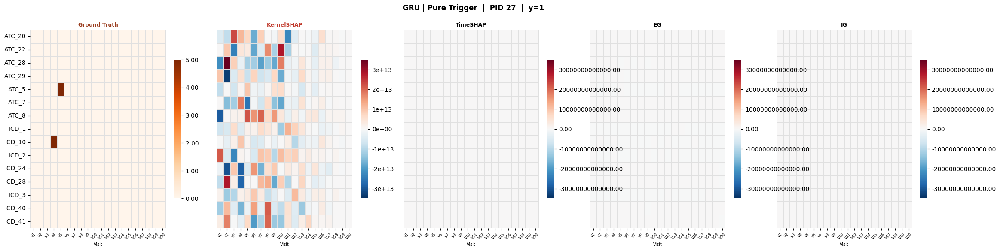

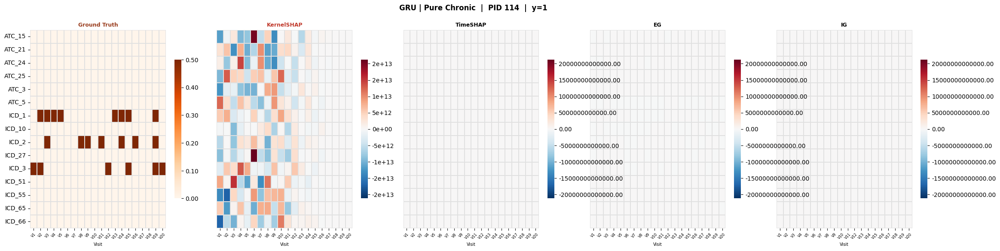

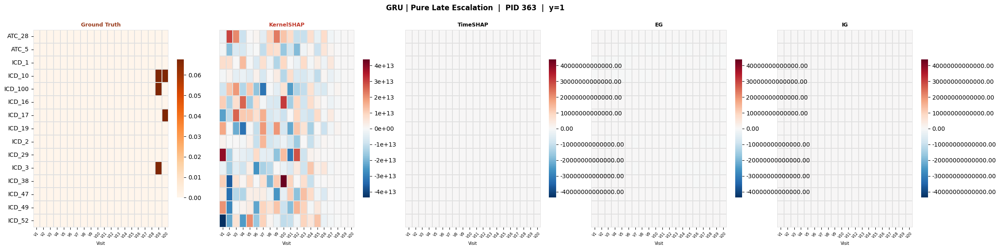

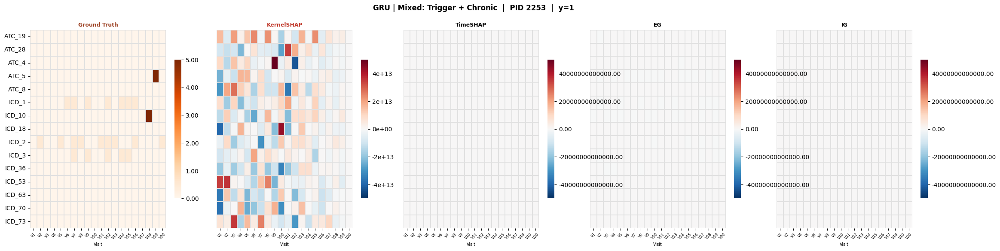

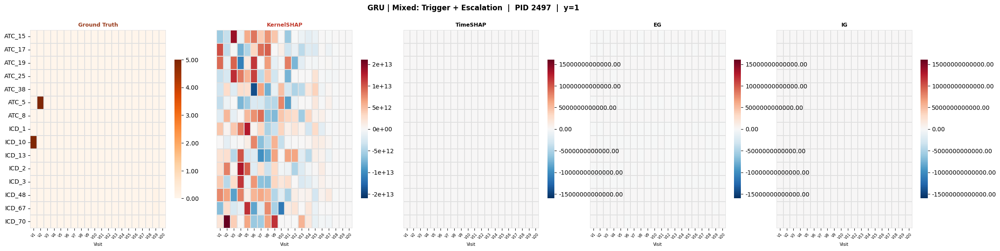

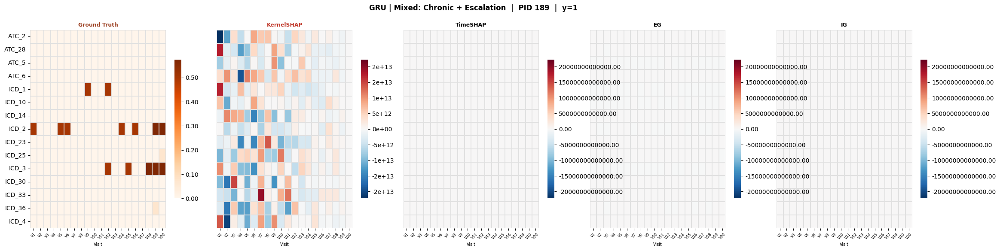

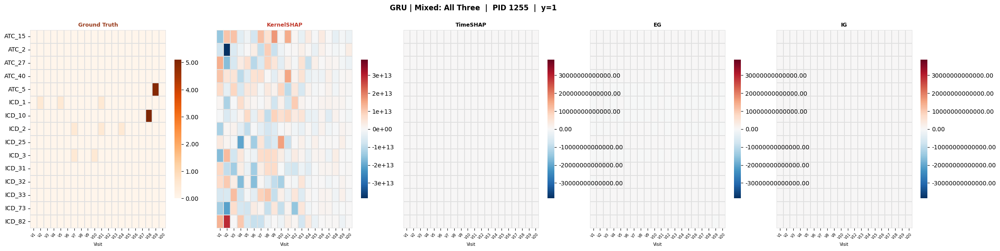

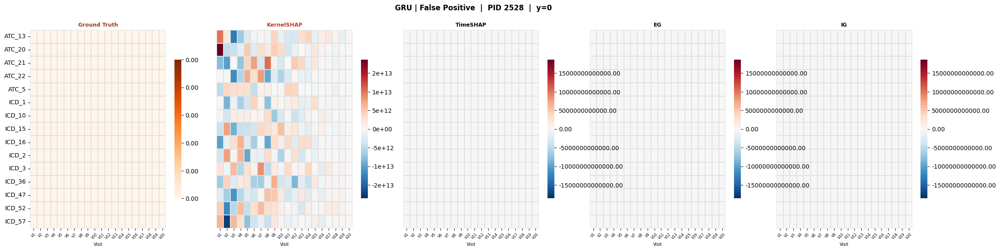

In [25]:
# ── All methods including ConditionalSHAP  (GRU only, rows = cases) ─────────

COL_TITLES_FULL = (['Ground Truth', 'KernelSHAP', 'TimeSHAP']
                   + ['EG', 'IG'])
N_COLS_FULL = len(COL_TITLES_FULL)

mkey   = 'gru'
mlabel = 'GRU'

for ci, (case_title, test_idx) in enumerate(zip(case_titles, case_indices)):
    test_idx  = int(test_idx)
    pid_val   = int(pid_test[test_idx])
    truth_pat = truth_ntf[test_idx]

    ks_arr = shap_ntf_dict[mkey][ci, :, :n_tokens]
    ts_arr = timeshap_ntf_dict[mkey][test_idx, :, :n_tokens]
    ts_arr = ts_arr if np.any(ts_arr != 0) else None
    eg_arr = EG_ARRS[MODEL_KEYS.index(mkey)][test_idx, :, :n_tokens]
    ig_arr = IG_ARRS[MODEL_KEYS.index(mkey)][test_idx, :, :n_tokens]

    valid = [ks_arr, eg_arr, ig_arr]
    if ts_arr is not None: valid.append(ts_arr)
    combined   = sum(np.abs(a).sum(axis=0) for a in valid)
    top_by     = np.argsort(combined)[-12:][::-1]
    show       = sorted(set(gt_indices) | set(top_by))[:TOP_K]
    show_names = [fnames_seq[i] for i in show]
    shared_vmax = max(np.abs(a[:, show]).max() for a in valid) + 1e-8
    gt_vmax     = truth_pat[:, show].max() + 1e-8

    fig, axes = plt.subplots(1, N_COLS_FULL,
                              figsize=(5.5 * N_COLS_FULL, 6),
                              gridspec_kw={'wspace': 0.10})
    fig.suptitle(f'{mlabel} | {case_title}  |  PID {pid_val}  |  y={int(y_test[test_idx])}',
                 fontsize=12, fontweight='bold')

    def _panel(ax, mat, title, is_gt=False, is_ks=False, yticks=False):
        vmax = gt_vmax if is_gt else shared_vmax
        sns.heatmap(mat[:, show].T, ax=ax,
                    cmap='Oranges' if is_gt else 'RdBu_r',
                    center=None if is_gt else 0,
                    vmin=0 if is_gt else -vmax, vmax=vmax,
                    xticklabels=visit_labels, yticklabels=show_names if yticks else [],
                    linewidths=0.3, linecolor='#e0e0e0',
                    cbar_kws={'shrink': 0.7, 'format': '%.0e' if is_ks else '%.2f'})
        ax.set_title(title, fontsize=9, fontweight='bold',
                     color='#993C1D' if is_gt else ('#c0392b' if is_ks else 'black'))
        if is_ks: ax.set_facecolor('#fff5f5')
        ax.tick_params(axis='x', rotation=45, labelsize=6)
        ax.set_xlabel('Visit', fontsize=7)
        if not yticks: ax.set_yticks([])

    def _no_data(ax, title):
        ax.text(0.5, 0.5, 'no data', ha='center', va='center',
                color='#aaaaaa', fontsize=9, style='italic', transform=ax.transAxes)
        ax.set_facecolor('#f5f5f5'); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(title, fontsize=9, fontweight='bold')

    col_data = [
        (truth_pat, 'Ground Truth', True,  False),
        (ks_arr,    'KernelSHAP',   False, True),
        (ts_arr,    'TimeSHAP',     False, False),
    ] + [
        (eg_arr, 'EG', False, False),
        (ig_arr, 'IG', False, False),
    ]

    for ax, (mat, title, is_gt, is_ks) in zip(axes, col_data):
        if mat is None:
            _no_data(ax, title)
        else:
            _panel(ax, mat, title, is_gt=is_gt, is_ks=is_ks,
                   yticks=(title == 'Ground Truth'))

    safe = case_title.replace(' ', '_').replace(':', '').replace('+', '_')
    plt.savefig(os.path.join(out, f'full_comparison_GRU_{safe}.png'),
                dpi=150, bbox_inches='tight')
    plt.show()
